In [1]:

import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# ==========================================
# 1. 데이터 불러오기 및 입항 기록 추출
# ==========================================

df = pd.read_csv("./data/i.csv", encoding="euc-kr")

df["입항일시_dt"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

arrival = df[
    (df["입출"] == "입항")
    & (df["입항일시_dt"].notna())
].copy()

arrival["날짜"] = arrival["입항일시_dt"].dt.normalize()

print("전체 입항 기록:", len(arrival))
print("분석 시작:", arrival["날짜"].min())
print("분석 종료:", arrival["날짜"].max())


# ==========================================
# 2. 분석 가능한 날짜 범위 생성
#    2020~2022년은 데이터 공백이므로 제외
# ==========================================

date_blocks = [
    ("2013-01-01", "2019-12-31"),
    ("2023-01-01", "2026-10-16")
]

all_dates = pd.DatetimeIndex([])

for start, end in date_blocks:
    all_dates = all_dates.append(
        pd.date_range(start=start, end=end, freq="D")
    )

daily = pd.DataFrame(index=all_dates)
daily.index.name = "날짜"

# 날짜별 전체 입항 건수
daily["입항건수"] = (
    arrival.groupby("날짜").size()
    .reindex(daily.index, fill_value=0)
)


# ==========================================
# 3. 예측 목표 생성
#    하루 중 60분 이내 2척 이상 입항 여부
# ==========================================

daily["집중입항"] = 0

for date, group in arrival.groupby("날짜"):
    times = sorted(group["입항일시_dt"].tolist())

    left = 0
    max_ships = 0

    for right in range(len(times)):
        while (
            times[right] - times[left]
            > pd.Timedelta(minutes=60)
        ):
            left += 1

        max_ships = max(max_ships, right - left + 1)

    if date in daily.index:
        daily.loc[date, "집중입항"] = int(max_ships >= 2)


# ==========================================
# 4. 예측 변수 생성
# ==========================================

daily["월"] = daily.index.month
daily["요일"] = daily.index.dayofweek
daily["연도"] = daily.index.year

# 월과 요일의 순환 특성 반영
daily["월_sin"] = np.sin(2 * np.pi * daily["월"] / 12)
daily["월_cos"] = np.cos(2 * np.pi * daily["월"] / 12)

daily["요일_sin"] = np.sin(
    2 * np.pi * daily["요일"] / 7
)
daily["요일_cos"] = np.cos(
    2 * np.pi * daily["요일"] / 7
)

# 데이터가 연속적으로 존재하는 구간별로
# 과거 입항 건수 계산
daily["직전7일입항"] = np.nan
daily["직전30일입항"] = np.nan

for start, end in date_blocks:
    block_index = pd.date_range(start, end, freq="D")
    block = daily.loc[block_index, "입항건수"]

    daily.loc[block_index, "직전7일입항"] = (
        block.shift(1).rolling(7, min_periods=7).sum()
    )

    daily.loc[block_index, "직전30일입항"] = (
        block.shift(1).rolling(30, min_periods=30).sum()
    )


# ==========================================
# 5. 학습 데이터와 검증 데이터 분리
# ==========================================

features = [
    "연도",
    "월_sin", "월_cos",
    "요일_sin", "요일_cos",
    "직전7일입항",
    "직전30일입항"
]

model_data = daily.dropna(subset=features).copy()

train = model_data[
    model_data.index < "2025-01-01"
]

test = model_data[
    (model_data.index >= "2025-01-01")
    & (model_data.index <= "2026-10-16")
]

X_train = train[features]
y_train = train["집중입항"]

X_test = test[features]
y_test = test["집중입항"]

print("\n학습 기간:", train.index.min(), "~", train.index.max())
print("검증 기간:", test.index.min(), "~", test.index.max())

print("학습 데이터:", len(train))
print("학습 집중 입항 사례:", int(y_train.sum()))
print("검증 데이터:", len(test))
print("검증 집중 입항 사례:", int(y_test.sum()))


# ==========================================
# 6. 모델 학습
# ==========================================

models = {
    "기준모델": DummyClassifier(strategy="prior"),

    "로지스틱 회귀": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),

    "랜덤포레스트": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    # 집중 입항일일 확률
    probabilities = model.predict_proba(X_test)[:, 1]

    # 우선 0.5를 기준으로 분류
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("\n혼동행렬 [실제 0/1, 예측 0/1]")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

    print("\n분류 성능")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["일반일", "집중입항일"],
            zero_division=0
        )
    )

    ap = average_precision_score(y_test, probabilities)

    # 검증 데이터에 양성/음성 클래스가 모두 있을 때 계산
    auc = (
        roc_auc_score(y_test, probabilities)
        if y_test.nunique() == 2
        else np.nan
    )

    results.append({
        "모델": name,
        "집중입항_평균정밀도": ap,
        "ROC_AUC": auc,
        "예측집중일수": int(predictions.sum())
    })


# ==========================================
# 7. 모델별 성능 비교
# ==========================================

comparison = pd.DataFrame(results).sort_values(
    "집중입항_평균정밀도",
    ascending=False
)

print("\n=== 모델 성능 비교 ===")
print(comparison.to_string(index=False))


# ==========================================
# 8. 랜덤포레스트 기준 예측 결과 저장
# ==========================================

rf = models["랜덤포레스트"]

forecast = test.copy()
forecast["집중입항확률"] = rf.predict_proba(X_test)[:, 1]

forecast["예측결과"] = np.where(
    forecast["집중입항확률"] >= 0.5,
    "집중 입항 예상",
    "일반 입항 예상"
)

forecast = forecast[
    [
        "입항건수",
        "집중입항",
        "직전7일입항",
        "직전30일입항",
        "집중입항확률",
        "예측결과"
    ]
]

forecast.to_csv(
    "크루즈_집중입항_예측결과.csv",
    encoding="utf-8-sig"
)

print("\n=== 예측 결과 상위 20일 ===")
print(
    forecast.sort_values(
        "집중입항확률", ascending=False
    ).head(20).to_string()
)

print("\n예측 결과를 CSV 파일로 저장했습니다.")


전체 입항 기록: 1518
분석 시작: 2013-01-01 00:00:00
분석 종료: 2026-10-16 00:00:00

학습 기간: 2013-01-31 00:00:00 ~ 2024-12-31 00:00:00
검증 기간: 2025-01-01 00:00:00 ~ 2026-10-16 00:00:00
학습 데이터: 3227
학습 집중 입항 사례: 53
검증 데이터: 654
검증 집중 입항 사례: 61

기준모델

혼동행렬 [실제 0/1, 예측 0/1]
[[593   0]
 [ 61   0]]

분류 성능
              precision    recall  f1-score   support

         일반일       0.91      1.00      0.95       593
       집중입항일       0.00      0.00      0.00        61

    accuracy                           0.91       654
   macro avg       0.45      0.50      0.48       654
weighted avg       0.82      0.91      0.86       654


로지스틱 회귀

혼동행렬 [실제 0/1, 예측 0/1]
[[196 397]
 [  4  57]]

분류 성능
              precision    recall  f1-score   support

         일반일       0.98      0.33      0.49       593
       집중입항일       0.13      0.93      0.22        61

    accuracy                           0.39       654
   macro avg       0.55      0.63      0.36       654
weighted avg       0.90      0.39      0.47       654



In [2]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# ==========================================
# 1. 학습 / 임계값 선택 / 최종 평가 데이터 분리
# ==========================================

model_data = daily.dropna(subset=features).copy()

train = model_data[model_data.index < "2023-01-01"].copy()

tune = model_data[
    (model_data.index >= "2023-01-01")
    & (model_data.index < "2025-01-01")
].copy()

test = model_data[
    (model_data.index >= "2025-01-01")
    & (model_data.index <= "2026-10-16")
].copy()

X_train = train[features]
y_train = train["집중입항"]

X_tune = tune[features]
y_tune = tune["집중입항"]

X_test = test[features]
y_test = test["집중입항"]

print("학습 집중일:", int(y_train.sum()), "/", len(train))
print("임계값 선택 집중일:", int(y_tune.sum()), "/", len(tune))
print("최종 평가 집중일:", int(y_test.sum()), "/", len(test))


# ==========================================
# 2. 임계값 선택용 모델
# ==========================================

def create_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

tuning_model = create_model()
tuning_model.fit(X_train, y_train)

tune_prob = tuning_model.predict_proba(X_tune)[:, 1]


# ==========================================
# 3. 2023~2024년에서 임계값 비교
#    재현율 80% 이상인 기준 중 정밀도가
#    가장 높은 임계값을 우선 선택
# ==========================================

threshold_rows = []

for threshold in np.arange(0.05, 0.96, 0.05):
    pred = (tune_prob >= threshold).astype(int)

    precision = precision_score(
        y_tune, pred, zero_division=0
    )
    recall = recall_score(
        y_tune, pred, zero_division=0
    )
    f1 = f1_score(
        y_tune, pred, zero_division=0
    )

    threshold_rows.append({
        "임계값": round(threshold, 2),
        "정밀도": precision,
        "재현율": recall,
        "F1": f1,
        "경보일수": int(pred.sum())
    })

threshold_table = pd.DataFrame(threshold_rows)

print("\n=== 임계값별 성능: 2023~2024년 ===")
print(threshold_table.round(3).to_string(index=False))

eligible = threshold_table[
    threshold_table["재현율"] >= 0.80
]

if len(eligible) > 0:
    selected_threshold = float(
        eligible.sort_values(
            ["정밀도", "F1"],
            ascending=False
        ).iloc[0]["임계값"]
    )
else:
    selected_threshold = float(
        threshold_table.sort_values(
            "F1", ascending=False
        ).iloc[0]["임계값"]
    )

print("\n선택된 임계값:", selected_threshold)


# ==========================================
# 4. 2025년 이전 전체 자료로 재학습
# ==========================================

final_model = create_model()

pre_test = model_data[
    model_data.index < "2025-01-01"
]

final_model.fit(
    pre_test[features],
    pre_test["집중입항"]
)

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)


# ==========================================
# 5. 최종 평가
# ==========================================

print("\n=== 최종 평가: 2025~2026-10-16 ===")

print("\n혼동행렬")
print(
    confusion_matrix(
        y_test, test_pred, labels=[0, 1]
    )
)

print("\n선택한 임계값 기준 성능")
print("정밀도:", round(
    precision_score(y_test, test_pred, zero_division=0), 3
))
print("재현율:", round(
    recall_score(y_test, test_pred, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test, test_pred, zero_division=0), 3
))
print("경보일수:", int(test_pred.sum()))

print(
    "평균정밀도(AP):",
    round(average_precision_score(y_test, test_prob), 3)
)

if y_test.nunique() == 2:
    print(
        "ROC-AUC:",
        round(roc_auc_score(y_test, test_prob), 3)
    )


# ==========================================
# 6. 결과 저장
# ==========================================

forecast = test.copy()
forecast["예측점수"] = test_prob
forecast["예측집중입항"] = test_pred
forecast["예측결과"] = np.where(
    test_pred == 1,
    "집중 입항 경보",
    "일반"
)

forecast.to_csv(
    "크루즈_집중입항_임계값개선.csv",
    encoding="utf-8-sig"
)

print("\n=== 예측 점수 상위 20일 ===")
print(
    forecast.sort_values(
        "예측점수", ascending=False
    )[
        [
            "입항건수",
            "집중입항",
            "예측점수",
            "예측결과"
        ]
    ].head(20).to_string()
)


학습 집중일: 41 / 2526
임계값 선택 집중일: 12 / 701
최종 평가 집중일: 61 / 654

=== 임계값별 성능: 2023~2024년 ===
 임계값   정밀도   재현율    F1  경보일수
0.05 0.017 1.000 0.034   701
0.10 0.017 1.000 0.034   690
0.15 0.019 1.000 0.038   625
0.20 0.022 1.000 0.042   555
0.25 0.022 0.917 0.043   502
0.30 0.024 0.917 0.048   451
0.35 0.030 0.917 0.057   372
0.40 0.031 0.833 0.060   320
0.45 0.031 0.750 0.060   290
0.50 0.031 0.667 0.059   261
0.55 0.034 0.667 0.064   237
0.60 0.037 0.667 0.070   217
0.65 0.040 0.667 0.075   200
0.70 0.042 0.667 0.079   191
0.75 0.037 0.500 0.069   161
0.80 0.038 0.417 0.069   133
0.85 0.039 0.250 0.067    77
0.90 0.024 0.083 0.037    42
0.95 0.250 0.083 0.125     4

선택된 임계값: 0.4

=== 최종 평가: 2025~2026-10-16 ===

혼동행렬
[[ 98 495]
 [  1  60]]

선택한 임계값 기준 성능
정밀도: 0.108
재현율: 0.984
F1: 0.195
경보일수: 555
평균정밀도(AP): 0.184
ROC-AUC: 0.737

=== 예측 점수 상위 20일 ===
            입항건수  집중입항      예측점수      예측결과
날짜                                        
2026-04-14     2     0  0.997934  집중 입항 경보
2026-04-13     1 

In [8]:

import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    recall_score,
    precision_score
)

# ==========================================
# 1. 데이터 준비
# ==========================================

df = pd.read_csv("./data/i.csv", encoding="euc-kr")
df["입항일시_dt"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

arrival = df[
    (df["입출"] == "입항")
    & df["입항일시_dt"].notna()
].copy()

arrival["날짜"] = arrival["입항일시_dt"].dt.normalize()

date_blocks = [
    ("2013-01-01", "2019-12-31"),
    ("2023-01-01", "2026-10-16")
]

dates = pd.DatetimeIndex([])
for start, end in date_blocks:
    dates = dates.append(
        pd.date_range(start, end, freq="D")
    )

daily = pd.DataFrame(index=dates)
daily.index.name = "날짜"

daily["입항건수"] = (
    arrival.groupby("날짜").size()
    .reindex(dates, fill_value=0)
)

# 60분 이내 2척 이상 입항 여부
daily["집중입항"] = 0

for date, group in arrival.groupby("날짜"):
    times = sorted(group["입항일시_dt"].tolist())
    left = 0
    max_ships = 0

    for right in range(len(times)):
        while times[right] - times[left] > pd.Timedelta(minutes=60):
            left += 1
        max_ships = max(max_ships, right - left + 1)

    if date in daily.index:
        daily.loc[date, "집중입항"] = int(max_ships >= 2)

# ==========================================
# 2. 예측 변수 생성
# ==========================================

daily["월"] = daily.index.month
daily["요일"] = daily.index.dayofweek
daily["연도"] = daily.index.year

daily["월_sin"] = np.sin(2 * np.pi * daily["월"] / 12)
daily["월_cos"] = np.cos(2 * np.pi * daily["월"] / 12)
daily["요일_sin"] = np.sin(2 * np.pi * daily["요일"] / 7)
daily["요일_cos"] = np.cos(2 * np.pi * daily["요일"] / 7)

daily["직전7일입항"] = np.nan
daily["직전30일입항"] = np.nan

for start, end in date_blocks:
    idx = pd.date_range(start, end, freq="D")
    block = daily.loc[idx, "입항건수"]

    daily.loc[idx, "직전7일입항"] = (
        block.shift(1).rolling(7, min_periods=7).sum()
    )
    daily.loc[idx, "직전30일입항"] = (
        block.shift(1).rolling(30, min_periods=30).sum()
    )

features = [
    "연도", "월_sin", "월_cos",
    "요일_sin", "요일_cos",
    "직전7일입항", "직전30일입항"
]

data = daily.dropna(subset=features).copy()

train = data[data.index < "2025-01-01"]
test = data[
    (data.index >= "2025-01-01")
    & (data.index <= "2026-10-16")
]

X_train, y_train = train[features], train["집중입항"]
X_test, y_test = test[features], test["집중입항"]

# ==========================================
# 3. 모델 학습
# ==========================================

models = {
    "로지스틱 회귀": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),
    "랜덤포레스트": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{'=' * 45}\n{name}\n{'=' * 45}")
    print("AP:", round(average_precision_score(y_test, prob), 3))
    print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

    # 실제 검증 데이터에서 변수 중요도 확인
    perm = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="average_precision",
        n_repeats=10,
        random_state=42
    )

    importance = pd.DataFrame({
        "변수": features,
        "중요도": perm.importances_mean,
        "표준편차": perm.importances_std
    }).sort_values("중요도", ascending=False)

    print("\n변수 중요도 (Permutation Importance)")
    print(importance.round(4).to_string(index=False))

    # 월별 점수 편향 확인
    monthly = pd.DataFrame({
        "월": X_test.index.month,
        "실제집중": y_test.to_numpy(),
        "예측점수": prob
    }).groupby("월").agg(
        실제집중일수=("실제집중", "sum"),
        평균예측점수=("예측점수", "mean"),
        평균실제집중비율=("실제집중", "mean"),
        평가일수=("실제집중", "size")
    )

    print("\n월별 예측 점수")
    print(monthly.round(3).to_string())

# ==========================================
# 4. 실제 집중일의 월별 분포 확인
# ==========================================

print("\n=== 실제 집중 입항일의 월별 분포 ===")
print(
    data.loc[test.index]
    .assign(월=lambda x: x.index.month)
    .groupby("월")["집중입항"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "집중일수",
        "count": "평가일수",
        "mean": "집중일비율"
    })
    .round(3)
    .to_string()
)



로지스틱 회귀
AP: 0.184
ROC-AUC: 0.737

변수 중요도 (Permutation Importance)
     변수     중요도   표준편차
직전30일입항  0.0746 0.0130
  월_sin  0.0045 0.0079
 요일_sin  0.0005 0.0022
     연도  0.0002 0.0002
 직전7일입항  0.0001 0.0020
 요일_cos -0.0015 0.0063
  월_cos -0.0035 0.0106

월별 예측 점수
    실제집중일수  평균예측점수  평균실제집중비율  평가일수
월                                 
1        2   0.428     0.032    62
2        1   0.518     0.018    56
3        7   0.688     0.113    62
4       15   0.948     0.250    60
5       11   0.968     0.177    62
6        4   0.913     0.067    60
7        5   0.745     0.081    62
8        6   0.658     0.097    62
9        4   0.658     0.067    60
10       4   0.595     0.085    47
11       1   0.567     0.033    30
12       1   0.449     0.032    31

랜덤포레스트
AP: 0.18
ROC-AUC: 0.687

변수 중요도 (Permutation Importance)
     변수     중요도   표준편차
  월_cos  0.0412 0.0157
직전30일입항  0.0089 0.0142
  월_sin  0.0084 0.0096
 직전7일입항  0.0054 0.0097
 요일_sin  0.0021 0.0150
     연도  0.0000 0.0000
 요일_cos -0.0002 0.0259


In [5]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# 월 정보만 사용하는 단순 모델
season_features = ["월_sin", "월_cos"]

# 계절성 + 최근 30일 입항 건수 모델
recent_features = [
    "월_sin", "월_cos", "직전30일입항"
]

# 현재 사용한 전체 변수 모델
full_features = features

model_specs = {
    "월 정보만": season_features,
    "월 + 직전30일": recent_features,
    "전체 변수": full_features
}

comparison = []

for name, cols in model_specs.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(train[cols], train["집중입항"])

    scores = model.predict_proba(test[cols])[:, 1]

    comparison.append({
        "모델": name,
        "AP": average_precision_score(
            test["집중입항"], scores
        ),
        "ROC_AUC": roc_auc_score(
            test["집중입항"], scores
        )
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.round(3).to_string(index=False))


       모델    AP  ROC_AUC
    월 정보만 0.122    0.621
월 + 직전30일 0.180    0.731
    전체 변수 0.184    0.737


In [6]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

model_specs = {
    "월 + 직전30일": ["월_sin", "월_cos", "직전30일입항"],
    "전체 변수": features
}

rows = []

for name, cols in model_specs.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(train[cols], train["집중입항"])
    scores = model.predict_proba(test[cols])[:, 1]

    for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        pred = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            test["집중입항"], pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "모델": name,
            "임계값": threshold,
            "정밀도": tp / (tp + fp) if tp + fp else 0,
            "재현율": tp / (tp + fn) if tp + fn else 0,
            "F1": (
                2 * tp / (2 * tp + fp + fn)
                if (2 * tp + fp + fn) else 0
            ),
            "경보일수": tp + fp,
            "놓친집중일수": fn
        })

result_threshold = pd.DataFrame(rows)

print(
    result_threshold.round(3).to_string(index=False)
)


       모델  임계값   정밀도   재현율    F1  경보일수  놓친집중일수
월 + 직전30일  0.3 0.097 1.000 0.176   631       0
월 + 직전30일  0.4 0.107 0.967 0.193   550       2
월 + 직전30일  0.5 0.134 0.902 0.234   409       6
월 + 직전30일  0.6 0.151 0.885 0.258   358       7
월 + 직전30일  0.7 0.162 0.885 0.274   333       7
월 + 직전30일  0.8 0.169 0.803 0.279   290      12
    전체 변수  0.3 0.096 1.000 0.176   634       0
    전체 변수  0.4 0.108 0.984 0.195   555       1
    전체 변수  0.5 0.126 0.934 0.221   454       4
    전체 변수  0.6 0.147 0.918 0.253   381       5
    전체 변수  0.7 0.160 0.869 0.270   332       8
    전체 변수  0.8 0.172 0.836 0.286   296      10


In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

model_specs = {
    "월 + 직전30일": ["월_sin", "월_cos", "직전30일입항"],
    "전체 변수": features
}

rows = []

for name, cols in model_specs.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(train[cols], train["집중입항"])
    scores = model.predict_proba(test[cols])[:, 1]

    for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        pred = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            test["집중입항"], pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "모델": name,
            "임계값": threshold,
            "정밀도": tp / (tp + fp) if tp + fp else 0,
            "재현율": tp / (tp + fn) if tp + fn else 0,
            "F1": (
                2 * tp / (2 * tp + fp + fn)
                if (2 * tp + fp + fn) else 0
            ),
            "경보일수": tp + fp,
            "놓친집중일수": fn
        })

result_threshold = pd.DataFrame(rows)

print(
    result_threshold.round(3).to_string(index=False)
)


       모델  임계값   정밀도   재현율    F1  경보일수  놓친집중일수
월 + 직전30일  0.3 0.097 1.000 0.176   631       0
월 + 직전30일  0.4 0.107 0.967 0.193   550       2
월 + 직전30일  0.5 0.134 0.902 0.234   409       6
월 + 직전30일  0.6 0.151 0.885 0.258   358       7
월 + 직전30일  0.7 0.162 0.885 0.274   333       7
월 + 직전30일  0.8 0.169 0.803 0.279   290      12
    전체 변수  0.3 0.096 1.000 0.176   634       0
    전체 변수  0.4 0.108 0.984 0.195   555       1
    전체 변수  0.5 0.126 0.934 0.221   454       4
    전체 변수  0.6 0.147 0.918 0.253   381       5
    전체 변수  0.7 0.160 0.869 0.270   332       8
    전체 변수  0.8 0.172 0.836 0.286   296      10


In [10]:

import pandas as pd

# 데이터 불러오기
df = pd.read_csv("./data/i.csv", encoding="cp949")

df["입항일시_dt"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

arrival = df[df["입출"] == "입항"].copy()

arrival["날짜"] = arrival["입항일시_dt"].dt.normalize()

# ======================================
# 1. 연도별 입항 기록 수
# ======================================
arrival["연도"] = arrival["입항일시_dt"].dt.year

print("\n=== 연도별 입항 기록 수 ===")
print(arrival.groupby("연도").size().to_string())

# ======================================
# 2. 연도-월별 입항 기록 수
# ======================================
valid = arrival.dropna(subset=["입항일시_dt"]).copy()

valid["연월"] = valid["입항일시_dt"].dt.to_period("M")

monthly = valid.groupby("연월").size()

print("\n=== 연도-월별 입항 기록 수 ===")
print(monthly.to_string())

# ======================================
# 3. 기록이 없는 날짜 확인
# ======================================
blocks = [
    ("2013-01-01", "2019-12-31"),
    ("2023-01-01", "2026-10-16")
]

for start, end in blocks:
    calendar = pd.date_range(start, end, freq="D")
    observed = valid.groupby("날짜").size().reindex(
        calendar, fill_value=0
    )

    print(f"\n=== {start} ~ {end} ===")
    print("전체 날짜:", len(calendar))
    print("입항 기록이 있는 날짜:", (observed > 0).sum())
    print("입항 기록이 없는 날짜:", (observed == 0).sum())

    print("\n기록이 없는 날짜 예시:")
    print(observed[observed == 0].head(20).index.strftime(
        "%Y-%m-%d"
    ).tolist())

# ======================================
# 4. 입항 시각 누락 및 날짜 변환 확인
# ======================================
print("\n=== 기록 품질 확인 ===")
print("전체 입항 행:", len(arrival))
print("입항 시각 누락:", arrival["입항일시_dt"].isna().sum())
print("선명 누락:", arrival["선명"].isna().sum()
      if "선명" in arrival.columns else "선명 열 없음")
print("계선장소 누락:", arrival["계선장소.2"].isna().sum()
      if "계선장소.2" in arrival.columns else "계선장소 열 없음")



=== 연도별 입항 기록 수 ===
연도
2013    106
2014    104
2015     64
2016    205
2017     89
2018     80
2019    107
2023    105
2024    114
2025    205
2026    339

=== 연도-월별 입항 기록 수 ===
연월
2013-01    10
2013-03     7
2013-04    13
2013-05    13
2013-06    15
2013-07    14
2013-08    12
2013-09     9
2013-10    12
2013-11     1
2014-01     1
2014-02     4
2014-03     7
2014-04    10
2014-05    13
2014-06    22
2014-07    14
2014-08     9
2014-09    10
2014-10     9
2014-11     3
2014-12     2
2015-02     1
2015-03     3
2015-04     7
2015-05    11
2015-06     8
2015-07     2
2015-08     6
2015-09     5
2015-10    10
2015-11     9
2015-12     2
2016-01     7
2016-02     5
2016-03     7
2016-04    12
2016-05    25
2016-06    17
2016-07    23
2016-08    32
2016-09    30
2016-10    23
2016-11    15
2016-12     9
2017-01     9
2017-02    11
2017-03     9
2017-04    12
2017-05    10
2017-06     1
2017-07     7
2017-08    11
2017-09    12
2017-10     7
2018-02     2
2018-03     4
2018-04    15
2018-0

In [11]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# 간결한 모델을 우선 평가
model_features = [
    "월_sin",
    "월_cos",
    "직전30일입항"
]

test_years = [2017, 2018, 2019, 2023, 2024, 2025, 2026]
threshold = 0.6

results = []

for year in test_years:
    # 해당 연도의 날짜만 평가
    test_mask = data.index.year == year
    test_year_data = data.loc[test_mask].copy()

    # 테스트 연도보다 과거인 날짜만 학습에 사용
    train_year_data = data.loc[data.index.year < year].copy()

    if train_year_data.empty or test_year_data.empty:
        continue

    X_train = train_year_data[model_features]
    y_train = train_year_data["집중입항"]

    X_test = test_year_data[model_features]
    y_test = test_year_data["집중입항"]

    # 학습 데이터에 양성·음성 사례가 모두 있어야 함
    if y_train.nunique() < 2 or y_test.nunique() < 2:
        print(f"{year}년: 양성·음성 사례 부족으로 일부 지표 생략")
        continue

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)
    scores = model.predict_proba(X_test)[:, 1]
    pred = (scores >= threshold).astype(int)

    results.append({
        "평가연도": year,
        "학습기간": f"{train_year_data.index.min():%Y-%m-%d} ~ "
                   f"{train_year_data.index.max():%Y-%m-%d}",
        "평가일수": len(test_year_data),
        "실제집중일수": int(y_test.sum()),
        "AP": average_precision_score(y_test, scores),
        "ROC_AUC": roc_auc_score(y_test, scores),
        "정밀도": precision_score(
            y_test, pred, zero_division=0
        ),
        "재현율": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "경보일수": int(pred.sum()),
        "놓친집중일수": int(((y_test == 1) & (pred == 0)).sum())
    })

result_yearly = pd.DataFrame(results)

print("\n=== 연도별 순차 검증 결과 ===")
print(result_yearly.round(3).to_string(index=False))



=== 연도별 순차 검증 결과 ===
 평가연도                    학습기간  평가일수  실제집중일수    AP  ROC_AUC   정밀도   재현율    F1  경보일수  놓친집중일수
 2017 2013-01-31 ~ 2016-12-31   365       2 0.016    0.633 0.000 0.000 0.000    31       2
 2018 2013-01-31 ~ 2017-12-31   365       2 0.007    0.416 0.000 0.000 0.000    41       2
 2019 2013-01-31 ~ 2018-12-31   365       6 0.036    0.725 0.038 0.333 0.068    53       4
 2023 2013-01-31 ~ 2019-12-31   335       6 0.036    0.707 0.045 0.667 0.084    89       2
 2024 2013-01-31 ~ 2023-12-31   366       6 0.041    0.706 0.042 0.667 0.079    95       2
 2025 2013-01-31 ~ 2024-12-31   365      18 0.132    0.757 0.129 0.722 0.218   101       5
 2026 2013-01-31 ~ 2025-12-31   289      43 0.190    0.600 0.163 0.953 0.279   251       2


In [12]:

# 기존에 만든 daily 데이터 사용
# daily에는 입항건수와 집중입항 열이 있어야 합니다.

yearly = daily.groupby(daily.index.year).agg(
    분석일수=("입항건수", "size"),
    입항건수합계=("입항건수", "sum"),
    입항기록있는날=("입항건수", lambda x: (x > 0).sum()),
    집중입항일수=("집중입항", "sum")
)

yearly["일평균입항건수"] = (
    yearly["입항건수합계"] / yearly["분석일수"]
)

yearly["입항기록일중집중비율(%)"] = (
    yearly["집중입항일수"]
    / yearly["입항기록있는날"].replace(0, float("nan"))
    * 100
)

# 2020~2022년은 원래 분석 범위에 없으므로 제외
yearly = yearly.loc[
    yearly.index.isin(
        [2013, 2014, 2015, 2016, 2017, 2018, 2019,
         2023, 2024, 2025, 2026]
    )
]

print(yearly.round(2).to_string())


      분석일수  입항건수합계  입항기록있는날  집중입항일수  일평균입항건수  입항기록일중집중비율(%)
날짜                                                         
2013   365     106       95       2     0.29           2.11
2014   365     104       91       8     0.28           8.79
2015   365      64       58       3     0.18           5.17
2016   366     205      164      18     0.56          10.98
2017   365      89       80       2     0.24           2.50
2018   365      80       71       2     0.22           2.82
2019   365     107       87       6     0.29           6.90
2023   365     105       87       6     0.29           6.90
2024   366     114       95       6     0.31           6.32
2025   365     205      159      18     0.56          11.32
2026   289     339      202      43     1.17          21.29


In [14]:

import pandas as pd
import numpy as np

# 1. 데이터 불러오기
df = pd.read_csv("./data/i.csv", encoding="euc-kr")

# 2. 입항 기록만 추출
df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")

inbound = df[df["입출"].astype(str).str.strip() == "1"].copy()
inbound = inbound.dropna(subset=["입항일시"])
inbound = inbound.sort_values("입항일시")

# 날짜와 연도
inbound["날짜"] = inbound["입항일시"].dt.normalize()
inbound["연도"] = inbound["입항일시"].dt.year

# 3. 연속한 입항 간 시간 차이 계산
inbound["직전입항간격_분"] = (
    inbound["입항일시"].diff().dt.total_seconds() / 60
)

print("\n=== 입항 간격 요약 ===")
print(
    inbound["직전입항간격_분"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(2)
)

print("\n=== 연도별 입항 간격 분석 ===")
gap_summary = inbound.groupby("연도").agg(
    입항건수=("입항일시", "size"),
    평균입항간격_분=("직전입항간격_분", "mean"),
    중앙값입항간격_분=("직전입항간격_분", "median"),
    최소입항간격_분=("직전입항간격_분", "min"),
)

for minutes in [30, 60, 120]:
    gap_summary[f"{minutes}분이내_간격수"] = (
        inbound["직전입항간격_분"].le(minutes)
        .groupby(inbound["연도"]).sum()
    )

print(gap_summary.round(2).to_string())

# 4. 날짜별 입항 건수 및 승객 수
# 승객 수는 기록값을 합산하며, 실제 하선 인원과 같다고 가정하지 않음
inbound["승객"] = pd.to_numeric(inbound["승객"], errors="coerce")

daily = inbound.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객수합계=("승객", "sum"),
    승객수기록항차=("승객", "count")
)

# 5. 60분 이내에 2척 이상 입항한 날짜 식별
# 각 입항 시각을 기준으로 직전 60분 구간에 다른 입항이 있었는지 확인
concentrated_dates = set()

for date, group in inbound.groupby("날짜"):
    times = group["입항일시"].sort_values().reset_index(drop=True)

    for i in range(1, len(times)):
        gap = (times.iloc[i] - times.iloc[i - 1]).total_seconds() / 60

        if gap <= 60:
            concentrated_dates.add(date)
            break

daily["집중입항"] = daily.index.isin(concentrated_dates).astype(int)

# 6. 연도별 집중입항일 비교
yearly = daily.groupby(daily.index.year).agg(
    입항기록있는날=("입항건수", "size"),
    집중입항일수=("집중입항", "sum"),
    집중입항일평균입항건수=(
        "입항건수",
        lambda x: x[daily.loc[x.index, "집중입항"] == 1].mean()
    ),
    집중입항일평균승객수=(
        "승객수합계",
        lambda x: x[daily.loc[x.index, "집중입항"] == 1].mean()
    )
)

yearly["집중입항일비율(%)"] = (
    yearly["집중입항일수"] / yearly["입항기록있는날"] * 100
)

print("\n=== 연도별 집중입항 및 승객 규모 ===")
print(yearly.round(2).to_string())

# 7. 집중입항일과 비집중입항일 비교
daily["입항유형"] = np.where(
    daily["집중입항"] == 1, "집중입항일", "비집중입항일"
)

comparison = daily.groupby("입항유형").agg(
    분석일수=("입항건수", "size"),
    평균입항건수=("입항건수", "mean"),
    평균승객수=("승객수합계", "mean"),
    중앙값승객수=("승객수합계", "median")
)

print("\n=== 집중입항일과 비집중입항일 비교 ===")
print(comparison.round(2).to_string())



=== 입항 간격 요약 ===
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: 직전입항간격_분, dtype: float64

=== 연도별 입항 간격 분석 ===
Empty DataFrame
Columns: [입항건수, 평균입항간격_분, 중앙값입항간격_분, 최소입항간격_분, 30분이내_간격수, 60분이내_간격수, 120분이내_간격수]
Index: []

=== 연도별 집중입항 및 승객 규모 ===
Empty DataFrame
Columns: [입항기록있는날, 집중입항일수, 집중입항일평균입항건수, 집중입항일평균승객수, 집중입항일비율(%)]
Index: []

=== 집중입항일과 비집중입항일 비교 ===
Empty DataFrame
Columns: [분석일수, 평균입항건수, 평균승객수, 중앙값승객수]
Index: []


In [15]:

import pandas as pd

df = pd.read_csv("./data/i.csv", encoding="euc-kr")

print("전체 행 수:", len(df))
print("\n열 이름:")
print(df.columns.tolist())

print("\n입출 열의 실제 값:")
print(df["입출"].value_counts(dropna=False).to_string())

print("\n입출 열의 자료형:")
print(df["입출"].dtype)

print("\n입항일시 예시:")
print(df["입항일시"].head(10).to_string())


전체 행 수: 3037

열 이름:
['항명', '호출부호', '선명', '입항횟수', '입항횟수.1', '구분', '외내', '입출', '총톤수', '입항일시', '출항일시', 'CIQ수속일자', '수리일시', '항해구분', 'MRN 번호', '계선장소', '계선장소.1', '계선장소.2', '차항지', '전출항지', '선박용도', '외항:한국인선원수\n내항:해기사선원수', '외항:외국인선원수\n내항:보통선원수', '승무원승선수', '승무원하선수', '승객승선수', '승객하선수', '승객', '예선', '도선', '부선호출부호1', '부선호출부호2']

입출 열의 실제 값:
입출
출항    1519
입항    1518

입출 열의 자료형:
str

입항일시 예시:
0    2013-01-01 8:00
1    2013-01-01 8:00
2    2013-01-06 7:25
3    2013-01-06 7:25
4    2013-01-10 5:40
5    2013-01-10 5:40
6    2013-01-13 6:30
7    2013-01-13 6:30
8    2013-01-15 6:30
9    2013-01-15 6:30


In [17]:

import pandas as pd
import numpy as np

# 1. 데이터 불러오기
df = pd.read_csv("./data/i.csv", encoding="euc-kr")

# 2. 입항 데이터만 추출
df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")

inbound = df.loc[df["입출"].astype(str).str.strip() == "입항"].copy()
inbound = inbound.dropna(subset=["입항일시"])
inbound = inbound.sort_values("입항일시").reset_index(drop=True)

inbound["연도"] = inbound["입항일시"].dt.year
inbound["날짜"] = inbound["입항일시"].dt.normalize()
inbound["승객"] = pd.to_numeric(inbound["승객"], errors="coerce")

print("입항 데이터 수:", len(inbound))
print(
    "분석 기간:",
    inbound["입항일시"].min(),
    "~",
    inbound["입항일시"].max()
)

# 3. 전체 입항 간격 계산
inbound["직전입항간격_분"] = (
    inbound["입항일시"].diff().dt.total_seconds() / 60
)

print("\n=== 입항 간격 요약 ===")
print(
    inbound["직전입항간격_분"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(2)
)

# 4. 연도별 입항 간격 분석
gap_summary = inbound.groupby("연도").agg(
    입항건수=("입항일시", "size"),
    평균입항간격_분=("직전입항간격_분", "mean"),
    중앙값입항간격_분=("직전입항간격_분", "median"),
    최소입항간격_분=("직전입항간격_분", "min")
)

for minutes in [30, 60, 120]:
    counts = (
        inbound["직전입항간격_분"].le(minutes)
        .groupby(inbound["연도"])
        .sum()
    )
    gap_summary[f"{minutes}분이내_간격수"] = counts

print("\n=== 연도별 입항 간격 분석 ===")
print(gap_summary.round(2).to_string())

# 5. 날짜별 입항 건수와 승객 수
daily = inbound.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객수합계=("승객", "sum"),
    승객수기록항차=("승객", "count")
)

# 6. 집중입항일 판정
# 같은 날짜에 연속한 입항 시각의 간격이 60분 이하이면 집중입항일
concentrated_dates = set()

for date, group in inbound.groupby("날짜"):
    times = group["입항일시"].sort_values().reset_index(drop=True)

    if len(times) >= 2:
        gaps = times.diff().dt.total_seconds() / 60

        if gaps.le(60).any():
            concentrated_dates.add(date)

daily["집중입항"] = daily.index.isin(concentrated_dates).astype(int)

# 7. 연도별 집중입항일 분석
yearly = daily.groupby(daily.index.year).agg(
    입항기록있는날=("입항건수", "size"),
    집중입항일수=("집중입항", "sum")
)

yearly["집중입항일비율(%)"] = (
    yearly["집중입항일수"] / yearly["입항기록있는날"] * 100
)

# 집중입항일의 평균 입항 건수와 승객 수
concentrated = daily[daily["집중입항"] == 1]

yearly["집중입항일평균입항건수"] = (
    concentrated.groupby(concentrated.index.year)["입항건수"].mean()
)
yearly["집중입항일평균승객수"] = (
    concentrated.groupby(concentrated.index.year)["승객수합계"].mean()
)

print("\n=== 연도별 집중입항 및 승객 규모 ===")
print(yearly.round(2).to_string())

# 8. 집중입항일과 비집중입항일 비교
daily["입항유형"] = np.where(
    daily["집중입항"] == 1,
    "집중입항일",
    "비집중입항일"
)

comparison = daily.groupby("입항유형").agg(
    분석일수=("입항건수", "size"),
    평균입항건수=("입항건수", "mean"),
    평균승객수=("승객수합계", "mean"),
    중앙값승객수=("승객수합계", "median")
)

print("\n=== 집중입항일과 비집중입항일 비교 ===")
print(comparison.round(2).to_string())


입항 데이터 수: 1518
분석 기간: 2013-01-01 08:00:00 ~ 2026-10-16 10:00:00

=== 입항 간격 요약 ===
count       1517.00
mean        4780.46
std        44458.81
min            0.00
25%         1137.00
50%         1625.00
75%         4320.00
max      1705650.00
Name: 직전입항간격_분, dtype: float64

=== 연도별 입항 간격 분석 ===
      입항건수  평균입항간격_분  중앙값입항간격_분  최소입항간격_분  30분이내_간격수  60분이내_간격수  120분이내_간격수
연도                                                                         
2013   106   4195.86     2910.0      10.0          1          2           4
2014   104   5552.45     4195.0      30.0          1          8           9
2015    64   8189.53     4437.0      60.0          0          3           4
2016   205   2732.34     1500.0       0.0         11         19          29
2017    89   4769.00     3870.0      15.0          1          2           3
2018    80   7115.86     3254.0      25.0          2          2           4
2019   107   5220.37     2820.0       0.0          5          6          10
2023   105  19763.14 

In [18]:

# ==========================================
# 1. 연도별 집중입항일 승객 규모 비교
# ==========================================

# 승객 수가 기록된 항차만 사용해 날짜별 합계 계산
daily_passenger = inbound.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객기록항차수=("승객", "count"),
    승객합계=("승객", "sum"),
    승객평균=("승객", "mean")
)

# 승객 수가 하나 이상 기록된 날짜와 전체 날짜 비교
daily_passenger["승객완전기록"] = (
    daily_passenger["승객기록항차수"]
    == daily_passenger["입항건수"]
)

# 집중입항 여부 연결
daily_passenger["집중입항"] = daily["집중입항"]

daily_passenger["연도"] = daily_passenger.index.year
daily_passenger["입항유형"] = np.where(
    daily_passenger["집중입항"] == 1,
    "집중입항일",
    "비집중입항일"
)

# 연도별 평균·중앙값·승객 완전기록 비율
annual_comparison = daily_passenger.groupby(
    ["연도", "입항유형"]
).agg(
    분석일수=("입항건수", "size"),
    평균입항건수=("입항건수", "mean"),
    평균승객합계=("승객합계", "mean"),
    중앙값승객합계=("승객합계", "median"),
    승객완전기록일수=("승객완전기록", "sum")
)

annual_comparison["승객완전기록비율(%)"] = (
    annual_comparison["승객완전기록일수"]
    / annual_comparison["분석일수"] * 100
)

print("\n=== 연도별 집중/비집중 승객 규모 ===")
print(annual_comparison.round(2).to_string())


# ==========================================
# 2. 승객 수가 완전히 기록된 날짜만 비교
# ==========================================

complete_days = daily_passenger[
    daily_passenger["승객완전기록"]
].copy()

complete_comparison = complete_days.groupby("입항유형").agg(
    분석일수=("입항건수", "size"),
    평균입항건수=("입항건수", "mean"),
    평균승객합계=("승객합계", "mean"),
    중앙값승객합계=("승객합계", "median")
)

print("\n=== 승객 수 완전 기록 날짜만 비교 ===")
print(complete_comparison.round(2).to_string())


# ==========================================
# 3. 집중입항일의 고승객 규모 여부 확인
# ==========================================

concentrated_days = daily_passenger[
    daily_passenger["집중입항"] == 1
].copy()

print("\n=== 집중입항일 승객 합계 분포 ===")
print(
    concentrated_days["승객합계"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(2)
)

print("\n=== 집중입항일 승객 규모 상위 10일 ===")
print(
    concentrated_days.sort_values(
        "승객합계", ascending=False
    )[
        ["연도", "입항건수", "승객기록항차수",
         "승객합계", "승객완전기록"]
    ].head(10).to_string()
)



=== 연도별 집중/비집중 승객 규모 ===
             분석일수  평균입항건수   평균승객합계  중앙값승객합계  승객완전기록일수  승객완전기록비율(%)
연도   입항유형                                                         
2013 비집중입항일    93    1.10  2072.66   2308.0        93       100.00
     집중입항일      2    2.00  3206.50   3206.5         2       100.00
2014 비집중입항일    83    1.05  2413.84   2554.0        83       100.00
     집중입항일      8    2.12  4987.75   4580.5         8       100.00
2015 비집중입항일    55    1.05  2637.00   2581.0        55       100.00
     집중입항일      3    2.00  5539.67   6065.0         3       100.00
2016 비집중입항일   146    1.14  3149.33   2847.0       146       100.00
     집중입항일     18    2.17  5615.83   5892.0        18       100.00
2017 비집중입항일    78    1.09  2000.01   2073.0        78       100.00
     집중입항일      2    2.00  1063.50   1063.5         2       100.00
2018 비집중입항일    69    1.10  1742.99   1435.0        69       100.00
     집중입항일      2    2.00  4264.50   4264.5         2       100.00
2019 비집중입항일    81    1.15  2047.67  

In [19]:

import pandas as pd
import numpy as np

# ==========================================
# 1. 날짜별 입항 및 승객 데이터 결합
# ==========================================

# 날짜별 입항 건수, 승객 합계, 승객 기록 항차 수
daily_ops = inbound.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객합계=("승객", "sum"),
    승객기록항차수=("승객", "count")
)

# 승객 수가 모든 입항 항차에 기록되었는지 확인
daily_ops["승객완전기록"] = (
    daily_ops["승객기록항차수"] == daily_ops["입항건수"]
)

# 기존 집중입항 판정 결과 연결
daily_ops["집중입항"] = daily["집중입항"].reindex(
    daily_ops.index
).fillna(0).astype(int)

daily_ops["연도"] = daily_ops.index.year

# ==========================================
# 2. 승객 규모 기준 설정
# ==========================================

# 입항 기록이 있는 날짜 중 승객 수가 완전하게 기록된 날짜만
# 기준값(중앙값) 계산에 사용
valid_passengers = daily_ops.loc[
    daily_ops["승객완전기록"], "승객합계"
]

passenger_threshold = valid_passengers.median()

print("승객 규모 중앙값 기준:", round(passenger_threshold, 1), "명")

# 기준값 이상이면 승객 규모가 큰 날로 분류
daily_ops["승객규모"] = np.where(
    daily_ops["승객합계"] >= passenger_threshold,
    "고승객규모",
    "저승객규모"
)

# 승객 수가 불완전한 날짜는 별도로 표시
daily_ops.loc[
    ~daily_ops["승객완전기록"], "승객규모"
] = "승객자료불완전"

# ==========================================
# 3. 운영 유형 분류
# ==========================================

conditions = [
    (daily_ops["집중입항"] == 1)
    & (daily_ops["승객규모"] == "고승객규모"),

    (daily_ops["집중입항"] == 0)
    & (daily_ops["승객규모"] == "고승객규모"),

    (daily_ops["집중입항"] == 1)
    & (daily_ops["승객규모"] == "저승객규모"),

    (daily_ops["집중입항"] == 0)
    & (daily_ops["승객규모"] == "저승객규모")
]

labels = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형",
    "C_중첩형",
    "D_일반형"
]

daily_ops["운영유형"] = np.select(
    conditions,
    labels,
    default="자료확인필요"
)

# ==========================================
# 4. 유형별 운영 특성 요약
# ==========================================

summary = daily_ops.groupby("운영유형").agg(
    분석일수=("입항건수", "size"),
    평균입항건수=("입항건수", "mean"),
    평균승객합계=("승객합계", "mean"),
    중앙값승객합계=("승객합계", "median"),
    승객완전기록일수=("승객완전기록", "sum")
)

summary["전체 분석일 중 비율(%)"] = (
    summary["분석일수"] / len(daily_ops) * 100
)

print("\n=== 운영 유형별 요약 ===")
print(summary.round(2).to_string())

# ==========================================
# 5. 연도별 운영 유형 비교
# ==========================================

year_type = pd.crosstab(
    daily_ops["연도"],
    daily_ops["운영유형"]
)

print("\n=== 연도별 운영 유형별 날짜 수 ===")
print(year_type.to_string())

# ==========================================
# 6. 결과 저장
# ==========================================

daily_ops.to_csv(
    "크루즈_날짜별_운영유형.csv",
    encoding="utf-8-sig"
)

summary.to_csv(
    "크루즈_운영유형_요약.csv",
    encoding="utf-8-sig"
)

print("\n분석 결과 CSV 파일 2개를 저장했습니다.")


승객 규모 중앙값 기준: 2234.0 명

=== 운영 유형별 요약 ===
             분석일수  평균입항건수   평균승객합계  중앙값승객합계  승객완전기록일수  전체 분석일 중 비율(%)
운영유형                                                                 
A_중첩·고승객수요형    93    2.45  4714.58   4467.0        93            7.82
B_대규모비집중입항형   501    1.27  3532.49   3066.0       501           42.14
C_중첩형          21    2.19   915.19    789.0        21            1.77
D_일반형         572    1.06   953.27    726.0       572           48.11
자료확인필요          2    1.00     0.00      0.0         0            0.17

=== 연도별 운영 유형별 날짜 수 ===
운영유형  A_중첩·고승객수요형  B_대규모비집중입항형  C_중첩형  D_일반형  자료확인필요
연도                                                  
2013            2           47      0     46       0
2014            8           53      0     30       0
2015            3           32      0     23       0
2016           17           98      1     48       0
2017            0           34      2     44       0
2018            2           25      0     44       0
2019            5  

In [66]:
passenger_threshold = valid_passengers.median()

In [67]:
# ==========================================
# 7. A~D 운영 유형 분류 검증
# ==========================================

print("\n=== 1. 승객 규모 기준값 ===")
print("계산된 중앙값:", passenger_threshold)
print("완전 기록 날짜 수:", len(valid_passengers))
print("불완전 기록 날짜 수:",
      (~daily_ops["승객완전기록"]).sum())

print("\n=== 2. 운영 유형별 날짜 수 ===")
print(daily_ops["운영유형"].value_counts(dropna=False))

print("\n=== 3. 운영 유형별 날짜 비중(%) ===")
print(
    (
        daily_ops["운영유형"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2)
)

print("\n=== 4. 불완전 기록 날짜의 분류 확인 ===")
print(
    daily_ops.loc[
        ~daily_ops["승객완전기록"],
        ["입항건수", "승객합계", "승객기록항차수",
         "승객규모", "집중입항", "운영유형"]
    ].to_string()
)

print("\n=== 5. 자료확인필요 날짜 확인 ===")
print(
    daily_ops.loc[
        daily_ops["운영유형"] == "자료확인필요",
        ["입항건수", "승객합계", "승객완전기록",
         "집중입항", "승객규모"]
    ].to_string()
)

print("\n=== 6. 날짜별 입항 건수와 유형별 평균 검산 ===")
print(
    daily_ops.groupby("운영유형").agg(
        날짜수=("입항건수", "size"),
        평균입항척수=("입항건수", "mean"),
        평균승객합계=("승객합계", "mean"),
        완전기록날짜수=("승객완전기록", "sum")
    ).round(2).to_string()
)


=== 1. 승객 규모 기준값 ===
계산된 중앙값: 2234.0
완전 기록 날짜 수: 1187
불완전 기록 날짜 수: 2

=== 2. 운영 유형별 날짜 수 ===
운영유형
D_일반형          572
B_대규모비집중입항형    501
A_중첩·고승객수요형     93
C_중첩형           21
자료확인필요           2
Name: count, dtype: int64

=== 3. 운영 유형별 날짜 비중(%) ===
운영유형
D_일반형          48.11
B_대규모비집중입항형    42.14
A_중첩·고승객수요형     7.82
C_중첩형           1.77
자료확인필요          0.17
Name: proportion, dtype: float64

=== 4. 불완전 기록 날짜의 분류 확인 ===
            입항건수  승객합계  승객기록항차수     승객규모  집중입항    운영유형
날짜                                                    
2025-03-06     1   0.0        0  승객자료불완전     0  자료확인필요
2025-12-13     1   0.0        0  승객자료불완전     0  자료확인필요

=== 5. 자료확인필요 날짜 확인 ===
            입항건수  승객합계  승객완전기록  집중입항     승객규모
날짜                                           
2025-03-06     1   0.0   False     0  승객자료불완전
2025-12-13     1   0.0   False     0  승객자료불완전

=== 6. 날짜별 입항 건수와 유형별 평균 검산 ===
             날짜수  평균입항척수   평균승객합계  완전기록날짜수
운영유형                                      
A_중첩·고승객수요형   93    2.45  4714.5

In [69]:
print("inbound 열 이름:")
print(inbound.columns.tolist())

print("\ndaily_ops 열 이름:")
print(daily_ops.columns.tolist())

print("\ninbound 인덱스 이름:")
print(inbound.index.name)

print("\ndaily_ops 인덱스 이름:")
print(daily_ops.index.name)

inbound 열 이름:
['항명', '호출부호', '선명', '입항횟수', '입항횟수.1', '구분', '외내', '입출', '총톤수', '입항일시', '출항일시', 'CIQ수속일자', '수리일시', '항해구분', 'MRN 번호', '계선장소', '계선장소.1', '계선장소.2', '차항지', '전출항지', '선박용도', '외항:한국인선원수\n내항:해기사선원수', '외항:외국인선원수\n내항:보통선원수', '승무원승선수', '승무원하선수', '승객승선수', '승객하선수', '승객', '예선', '도선', '부선호출부호1', '부선호출부호2', '연도', '시간']

daily_ops 열 이름:
['입항건수', '승객합계', '승객기록항차수', '승객완전기록', '집중입항', '연도', '승객규모', '운영유형']

inbound 인덱스 이름:
None

daily_ops 인덱스 이름:
날짜


In [70]:
print("inbound 입항일시 자료형:")
print(inbound["입항일시"].dtype)

print("\ndaily_ops 날짜 인덱스 자료형:")
print(type(daily_ops.index))
print(daily_ops.index.dtype)

print("\ninbound 날짜 예시:")
print(pd.to_datetime(inbound["입항일시"]).dt.normalize().head())

print("\ndaily_ops 날짜 예시:")
print(daily_ops.index[:5])

inbound 입항일시 자료형:
datetime64[us]

daily_ops 날짜 인덱스 자료형:
<class 'pandas.DatetimeIndex'>
datetime64[us]

inbound 날짜 예시:
1   2013-01-01
3   2013-01-06
5   2013-01-10
7   2013-01-13
9   2013-01-15
Name: 입항일시, dtype: datetime64[us]

daily_ops 날짜 예시:
DatetimeIndex(['2013-01-01', '2013-01-06', '2013-01-10', '2013-01-13',
               '2013-01-15'],
              dtype='datetime64[us]', name='날짜', freq=None)


In [71]:
# 입항일시에서 날짜 생성
inbound["날짜"] = pd.to_datetime(inbound["입항일시"]).dt.normalize()

# daily_ops 날짜 인덱스 기준으로 운영유형 연결
inbound["운영유형"] = inbound["날짜"].map(daily_ops["운영유형"])

print("전체 입항 기록:", len(inbound))
print("운영유형 연결 성공:", inbound["운영유형"].notna().sum())
print("운영유형 연결 실패:", inbound["운영유형"].isna().sum())

print("\n운영유형별 연결 결과:")
print(inbound["운영유형"].value_counts(dropna=False))

전체 입항 기록: 1518
운영유형 연결 성공: 1518
운영유형 연결 실패: 0

운영유형별 연결 결과:
운영유형
B_대규모비집중입항형    638
D_일반형          604
A_중첩·고승객수요형    228
C_중첩형           46
자료확인필요           2
Name: count, dtype: int64


=== 유형별 시간대 입항 척수 ===
운영유형  A_중첩·고승객수요형  B_대규모비집중입항형  C_중첩형  D_일반형
입항시간                                        
0               1            2      0      0
1               0            1      0      0
2               0            1      0      0
3               0            0      0      1
4               1            2      0      0
5              17           23      2     28
6              72          169     12    133
7              61          136     18    144
8              28           69      8    109
9              30           78      2     63
10              7           35      2     34
11              1           39      2     33
12              3           31      0     29
13              5           30      0     11
14              1           10      0      7
15              0            4      0      2
16              0            3      0      5
17              1            2      0      2
18              0            1      0      0
19              0            0   

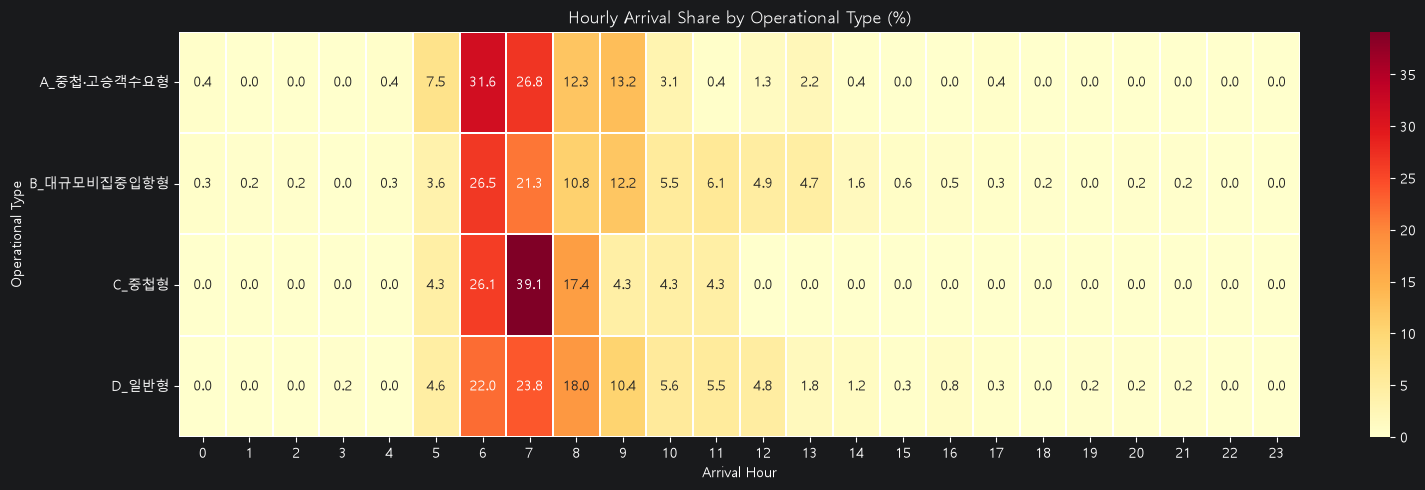

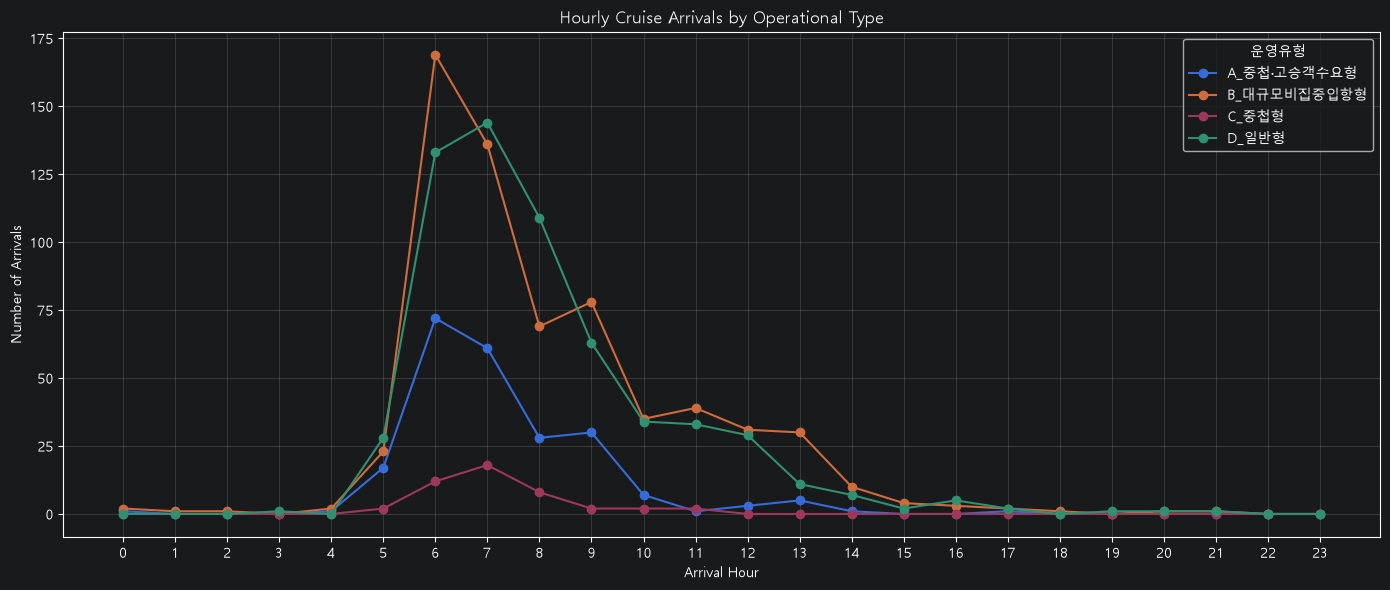

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

type_order = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형",
    "C_중첩형",
    "D_일반형"
]

# 자료 확인 필요 유형은 제외
type_data = inbound[
    inbound["운영유형"].isin(type_order)
].copy()

type_data["입항시간"] = type_data["입항일시"].dt.hour

# 1. 유형별 시간대 입항 척수
hourly_type = pd.crosstab(
    type_data["입항시간"],
    type_data["운영유형"]
).reindex(
    index=range(24),
    columns=type_order,
    fill_value=0
)

# 2. 각 유형 내부의 시간대별 비중(%)
hourly_type_share = (
    hourly_type
    .div(hourly_type.sum(axis=0).replace(0, np.nan), axis=1)
    * 100
)

print("=== 유형별 시간대 입항 척수 ===")
print(hourly_type)

print("\n=== 유형별 시간대 입항 비중(%) ===")
print(hourly_type_share.round(2))

# 3. 유형별 핵심 시간대 요약
morning = hourly_type.loc[6:9].sum()
total = hourly_type.sum()

type_hour_summary = pd.DataFrame({
    "전체입항척수": total,
    "06~09시입항척수": morning,
    "06~09시입항비중(%)": (
        morning.div(total.replace(0, np.nan)) * 100
    ),
    "최다입항시간": hourly_type.idxmax(),
    "최다입항시간척수": hourly_type.max()
})

print("\n=== 유형별 핵심 시간대 요약 ===")
print(type_hour_summary.round(2))

# 4. 히트맵
plt.figure(figsize=(16, 5))
sns.heatmap(
    hourly_type_share.T,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.3
)
plt.title("Hourly Arrival Share by Operational Type (%)")
plt.xlabel("Arrival Hour")
plt.ylabel("Operational Type")
plt.tight_layout()
plt.show()

# 5. 시간대별 입항 척수 비교
hourly_type.plot(
    figsize=(14, 6),
    marker="o"
)
plt.title("Hourly Cruise Arrivals by Operational Type")
plt.xlabel("Arrival Hour")
plt.ylabel("Number of Arrivals")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. 결과 저장
hourly_type.to_csv(
    "운영유형별_시간대_입항척수.csv",
    encoding="utf-8-sig"
)

hourly_type_share.to_csv(
    "운영유형별_시간대_입항비중.csv",
    encoding="utf-8-sig"
)

type_hour_summary.to_csv(
    "운영유형별_핵심시간대요약.csv",
    encoding="utf-8-sig"
)

In [73]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. 날짜별 입항 기록 및 승객 규모 집계
# --------------------------------------------------
data = inbound.copy()

data["입항일시"] = pd.to_datetime(
    data["입항일시"], errors="coerce"
)
data["날짜"] = data["입항일시"].dt.normalize()

data = data.dropna(subset=["입항일시"]).copy()
data["승객"] = pd.to_numeric(data["승객"], errors="coerce")

daily_sens = data.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객합계=("승객", lambda x: x.sum(min_count=1)),
    승객기록항차수=("승객", "count")
)

daily_sens["승객완전기록"] = (
    daily_sens["승객기록항차수"]
    == daily_sens["입항건수"]
)

# --------------------------------------------------
# 2. 날짜별 연속 입항 시각 간격 계산
#    같은 날짜의 연속된 입항 시각 차이를 비교
# --------------------------------------------------
data = data.sort_values(["날짜", "입항일시"])

data["이전입항일시"] = (
    data.groupby("날짜")["입항일시"].shift(1)
)

data["입항간격_분"] = (
    data["입항일시"] - data["이전입항일시"]
).dt.total_seconds() / 60

# 날짜별 최소 연속 입항 간격
min_gap = data.groupby("날짜")["입항간격_분"].min()

daily_sens["최소입항간격_분"] = min_gap

# --------------------------------------------------
# 3. 승객 규모 기준 계산
#    승객 기록이 완전한 날짜만 사용
# --------------------------------------------------
complete_pax = daily_sens.loc[
    daily_sens["승객완전기록"], "승객합계"
].dropna()

thresholds = {
    "P50_중앙값": complete_pax.quantile(0.50),
    "P75_상위25%기준": complete_pax.quantile(0.75)
}

print("=== 승객 규모 기준 ===")
print(f"완전 기록 날짜 수: {len(complete_pax)}")

for name, value in thresholds.items():
    print(f"{name}: {value:.1f}명")

# --------------------------------------------------
# 4. 시간 간격 × 승객 규모 기준별 운영유형 분류
# --------------------------------------------------
gap_thresholds = [30, 60, 90]

type_order = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형",
    "C_중첩형",
    "D_일반형",
    "자료확인필요"
]

results = []
type_assignments = {}

for gap_limit in gap_thresholds:
    # 이 기준에서 날짜별 시간 중첩 여부
    overlap = (
        daily_sens["최소입항간격_분"] <= gap_limit
    )

    # 입항이 한 척뿐인 날짜는 간격이 없으므로 비중첩 처리
    overlap = overlap.fillna(False)

    for pax_name, pax_limit in thresholds.items():
        high_pax = daily_sens["승객합계"] >= pax_limit

        conditions = [
            ~daily_sens["승객완전기록"],
            overlap & high_pax,
            (~overlap) & high_pax,
            overlap & (~high_pax),
            (~overlap) & (~high_pax)
        ]

        choices = [
            "자료확인필요",
            "A_중첩·고승객수요형",
            "B_대규모비집중입항형",
            "C_중첩형",
            "D_일반형"
        ]

        labels = np.select(
            [condition.to_numpy() for condition in conditions],
            choices,
            default="자료확인필요"
        )

        scenario = f"{gap_limit}분_{pax_name}"
        type_assignments[scenario] = pd.Series(
            labels,
            index=daily_sens.index
        )

        counts = pd.Series(labels).value_counts()

        for typ in type_order:
            results.append({
                "입항간격기준_분": gap_limit,
                "승객기준": pax_name,
                "승객임계값": pax_limit,
                "운영유형": typ,
                "날짜수": int(counts.get(typ, 0)),
                "전체날짜대비비율(%)": (
                    counts.get(typ, 0) / len(daily_sens) * 100
                )
            })

sensitivity = pd.DataFrame(results)

# --------------------------------------------------
# 5. 유형별 날짜 수 비교표
# --------------------------------------------------
count_table = sensitivity.pivot_table(
    index=["입항간격기준_분", "승객기준"],
    columns="운영유형",
    values="날짜수",
    aggfunc="sum",
    fill_value=0
).reindex(columns=type_order, fill_value=0)

print("\n=== 기준 조합별 운영유형 날짜 수 ===")
print(count_table)

print("\n=== 기준 조합별 운영유형 비율(%) ===")
share_table = sensitivity.pivot_table(
    index=["입항간격기준_분", "승객기준"],
    columns="운영유형",
    values="전체날짜대비비율(%)",
    aggfunc="sum",
    fill_value=0
).reindex(columns=type_order, fill_value=0)

print(share_table.round(2))

# --------------------------------------------------
# 6. 기준 조합별 A 유형 날짜 수 비교
# --------------------------------------------------
a_comparison = sensitivity[
    sensitivity["운영유형"] == "A_중첩·고승객수요형"
].pivot(
    index="입항간격기준_분",
    columns="승객기준",
    values="날짜수"
)

print("\n=== A 유형 날짜 수 비교 ===")
print(a_comparison)

# --------------------------------------------------
# 7. 결과 저장
# --------------------------------------------------
sensitivity.to_csv(
    "운영유형_민감도분석_상세.csv",
    index=False,
    encoding="utf-8-sig"
)

count_table.to_csv(
    "운영유형_민감도분석_날짜수.csv",
    encoding="utf-8-sig"
)

share_table.to_csv(
    "운영유형_민감도분석_비율.csv",
    encoding="utf-8-sig"
)

a_comparison.to_csv(
    "운영유형_A유형_민감도비교.csv",
    encoding="utf-8-sig"
)

=== 승객 규모 기준 ===
완전 기록 날짜 수: 1187
P50_중앙값: 2234.0명
P75_상위25%기준: 3289.5명

=== 기준 조합별 운영유형 날짜 수 ===
운영유형                  A_중첩·고승객수요형  B_대규모비집중입항형  C_중첩형  D_일반형  자료확인필요
입항간격기준_분 승객기준                                                       
30       P50_중앙값               47          547     12    581       2
         P75_상위25%기준           41          256     18    872       2
60       P50_중앙값               93          501     21    572       2
         P75_상위25%기준           71          226     43    847       2
90       P50_중앙값              114          480     27    566       2
         P75_상위25%기준           81          216     60    830       2

=== 기준 조합별 운영유형 비율(%) ===
운영유형                  A_중첩·고승객수요형  B_대규모비집중입항형  C_중첩형  D_일반형  자료확인필요
입항간격기준_분 승객기준                                                       
30       P50_중앙값             3.95        46.01   1.01  48.86    0.17
         P75_상위25%기준         3.45        21.53   1.51  73.34    0.17
60       P50_중앙값             7.82        42.14 

In [21]:

import pandas as pd
import numpy as np

# ==========================================
# 1. 데이터 불러오기
# ==========================================
df = pd.read_csv("./data/i.csv", encoding="euc-kr")

# 입항 데이터만 추출
inbound = df[
    df["입출"].astype(str).str.strip() == "입항"
].copy()

inbound["입항일시"] = pd.to_datetime(
    inbound["입항일시"], errors="coerce"
)
inbound["승객"] = pd.to_numeric(
    inbound["승객"], errors="coerce"
)

inbound = inbound.dropna(subset=["입항일시"]).copy()
inbound["날짜"] = inbound["입항일시"].dt.normalize()
inbound["연도"] = inbound["입항일시"].dt.year

# 탐색용 승객 수 기준: 기존 분석과 동일
PASSENGER_THRESHOLD = 2234

# ==========================================
# 2. 날짜별 입항 중첩 여부 계산
# 같은 날짜 안에서 연속한 입항 시각의 차이가
# 60분 이하면 집중입항일로 분류
# ==========================================
inbound = inbound.sort_values("입항일시").copy()

inbound["이전입항시각"] = (
    inbound.groupby("날짜")["입항일시"].shift(1)
)

inbound["직전간격_분"] = (
    inbound["입항일시"] - inbound["이전입항시각"]
).dt.total_seconds() / 60

daily = inbound.groupby("날짜").agg(
    입항건수=("입항일시", "size"),
    승객수합계=("승객", lambda x: x.sum(min_count=1)),
    승객수기록항차=("승객", "count")
)

overlap_dates = set(
    inbound.loc[
        inbound["직전간격_분"].le(60),
        "날짜"
    ]
)

daily["집중입항"] = daily.index.isin(overlap_dates)

# ==========================================
# 3. A/B/C/D 유형 분류
# ==========================================
daily["유형"] = "D_일반형"

daily.loc[
    daily["집중입항"]
    & daily["승객수합계"].ge(PASSENGER_THRESHOLD),
    "유형"
] = "A_중첩·고승객수요형"

daily.loc[
    ~daily["집중입항"]
    & daily["승객수합계"].ge(PASSENGER_THRESHOLD),
    "유형"
] = "B_대규모비집중입항형"

daily.loc[
    daily["집중입항"]
    & daily["승객수합계"].lt(PASSENGER_THRESHOLD),
    "유형"
] = "C_중첩형"

daily.loc[
    daily["승객수합계"].isna(),
    "유형"
] = "자료확인필요"

# 유형을 선박별 입항 기록에 결합
inbound = inbound.merge(
    daily[["승객수합계", "집중입항", "유형"]],
    left_on="날짜",
    right_index=True,
    how="left"
)

# ==========================================
# 4. A형/B형 날짜 요약
# ==========================================
target_types = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형"
]

target_days = daily[
    daily["유형"].isin(target_types)
].reset_index()

print("\n===== A형/B형 날짜 요약 =====")
print(
    target_days.sort_values(
        ["유형", "승객수합계"],
        ascending=[True, False]
    ).to_string(index=False)
)

# ==========================================
# 5. 해당 날짜의 선박별 상세 기록
# ==========================================
detail_columns = [
    "날짜", "유형", "입항일시", "선명",
    "호출부호", "승객", "계선장소.2",
    "총톤수", "승객수합계", "직전간격_분"
]

detail_columns = [
    c for c in detail_columns if c in inbound.columns
]

details = inbound[
    inbound["유형"].isin(target_types)
][detail_columns].copy()

details = details.sort_values(
    ["날짜", "입항일시"]
)

print("\n===== A형/B형 선박별 상세 기록 =====")
print(details.to_string(index=False))

# ==========================================
# 6. 유형별 요약 통계
# ==========================================
print("\n===== 유형별 운영 특성 =====")

type_summary = (
    daily[daily["유형"].isin(target_types)]
    .groupby("유형")
    .agg(
        날짜수=("입항건수", "size"),
        평균입항건수=("입항건수", "mean"),
        평균승객수=("승객수합계", "mean"),
        중앙값승객수=("승객수합계", "median"),
        최대승객수=("승객수합계", "max")
    )
    .round(2)
)

print(type_summary.to_string())

# ==========================================
# 7. 2025년과 2026년 동일 기간 비교
# 두 해 모두 1월 1일~10월 16일까지만 비교
# ==========================================
same_period = daily.reset_index()

same_period = same_period[
    (
        (same_period["날짜"] >= "2025-01-01")
        & (same_period["날짜"] <= "2025-10-16")
    )
    |
    (
        (same_period["날짜"] >= "2026-01-01")
        & (same_period["날짜"] <= "2026-10-16")
    )
].copy()

same_period["연도"] = same_period["날짜"].dt.year

comparison = (
    same_period[
        same_period["유형"].isin(target_types)
    ]
    .groupby(["연도", "유형"])
    .agg(
        날짜수=("입항건수", "size"),
        평균입항건수=("입항건수", "mean"),
        평균승객수=("승객수합계", "mean")
    )
    .round(2)
)

print("\n===== 2025년 vs 2026년 동일 기간 비교 =====")
print(comparison.to_string())

# ==========================================
# 8. 엑셀로 저장
# ==========================================
with pd.ExcelWriter(
        "data/크루즈_A_B유형_운영분석.xlsx",
    engine="openpyxl"
) as writer:
    target_days.to_excel(
        writer, sheet_name="유형별_날짜", index=False
    )
    details.to_excel(
        writer, sheet_name="선박별_상세", index=False
    )
    type_summary.to_excel(
        writer, sheet_name="유형별_요약"
    )
    comparison.to_excel(
        writer, sheet_name="동일기간_비교"
    )

print("\n분석 완료: 크루즈_A_B유형_운영분석.xlsx")



===== A형/B형 날짜 요약 =====
        날짜  입항건수  승객수합계  승객수기록항차  집중입항          유형
2016-06-01     3 8385.0        3  True A_중첩·고승객수요형
2026-08-21     2 8277.0        2  True A_중첩·고승객수요형
2026-08-25     3 7832.0        3  True A_중첩·고승객수요형
2025-04-03     3 7761.0        3  True A_중첩·고승객수요형
2026-10-13     4 7731.0        4  True A_중첩·고승객수요형
2016-10-19     2 7708.0        2  True A_중첩·고승객수요형
2016-10-10     2 7575.0        2  True A_중첩·고승객수요형
2016-08-15     2 7490.0        2  True A_중첩·고승객수요형
2026-04-04     3 7286.0        3  True A_중첩·고승객수요형
2016-09-04     2 7262.0        2  True A_중첩·고승객수요형
2026-05-14     2 7221.0        2  True A_중첩·고승객수요형
2014-06-02     3 7074.0        3  True A_중첩·고승객수요형
2016-07-21     2 7045.0        2  True A_중첩·고승객수요형
2026-10-04     2 6836.0        2  True A_중첩·고승객수요형
2016-05-02     3 6791.0        3  True A_중첩·고승객수요형
2026-03-11     3 6539.0        3  True A_중첩·고승객수요형
2015-05-12     2 6425.0        2  True A_중첩·고승객수요형
2016-08-20     2 6419.0        2  True A_중첩·고승객수요형
2016-0

In [24]:

import pandas as pd
import numpy as np

# ==========================================
# 1. 파일 불러오기
# ==========================================
source_file = "./data/i.csv"
analysis_file = "./data/크루즈_A_B유형_운영분석.xlsx"
output_file = "크루즈_A_B유형_심화분석.xlsx"

df = pd.read_csv(source_file, encoding="euc-kr")

inbound = df[
    df["입출"].astype(str).str.strip() == "입항"
].copy()

inbound["입항일시"] = pd.to_datetime(
    inbound["입항일시"], errors="coerce"
)
inbound["승객"] = pd.to_numeric(
    inbound["승객"], errors="coerce"
)
inbound["날짜"] = inbound["입항일시"].dt.normalize()

inbound = inbound.dropna(subset=["입항일시"]).copy()
inbound = inbound.sort_values(
    ["날짜", "입항일시"]
).reset_index(drop=True)

# 기존 분석에서 분류한 A/B 유형을 그대로 사용
daily_types = pd.read_excel(
    analysis_file, sheet_name="유형별_날짜"
)

daily_types["날짜"] = pd.to_datetime(
    daily_types["날짜"], errors="coerce"
).dt.normalize()

daily_types = daily_types[
    ["날짜", "유형", "입항건수", "승객수합계", "집중입항"]
]

inbound = inbound.merge(
    daily_types[["날짜", "유형", "승객수합계"]],
    on="날짜",
    how="left",
    suffixes=("", "_일자")
)

target = inbound[
    inbound["유형"].isin([
        "A_중첩·고승객수요형",
        "B_대규모비집중입항형"
    ])
].copy()

# ==========================================
# 2. 선박 간 입항 간격 분석
# ==========================================
target = target.sort_values(
    ["날짜", "입항일시"]
).copy()

target["이전입항시각"] = (
    target.groupby("날짜")["입항일시"].shift(1)
)

target["입항간격_분"] = (
    target["입항일시"] - target["이전입항시각"]
).dt.total_seconds() / 60

target["간격_15분이내"] = target["입항간격_분"].le(15)
target["간격_30분이내"] = target["입항간격_분"].le(30)
target["간격_60분이내"] = target["입항간격_분"].le(60)

# 날짜별 시간 중첩 정도
interval_summary = target.groupby(
    ["날짜", "유형"]
).agg(
    입항건수=("입항일시", "size"),
    최소입항간격_분=("입항간격_분", "min"),
    십오분이내간격수=("간격_15분이내", "sum"),
    삼십분이내간격수=("간격_30분이내", "sum"),
    육십분이내간격수=("간격_60분이내", "sum")
).reset_index()

# 첫 번째 입항은 이전 입항이 없으므로 간격이 NaN.
# 따라서 위 간격 건수는 실제 선박 간 간격 건수만 셉니다.

# ==========================================
# 3. 같은 날 접안 장소가 몇 곳인지 분석
# ==========================================
berth_col = "계선장소.2"

target["접안장소_정리"] = (
    target[berth_col].astype("string").str.strip()
    if berth_col in target.columns
    else pd.NA
)

berth_summary = target.groupby(
    ["날짜", "유형"]
).agg(
    접안장소수=("접안장소_정리", "nunique"),
    접안장소목록=(
        "접안장소_정리",
        lambda x: " / ".join(
            sorted(x.dropna().unique().tolist())
        )
    )
).reset_index()

# 같은 날 같은 장소에 여러 척이 입항했는지 확인
berth_detail = target.groupby(
    ["날짜", "유형", "접안장소_정리"]
).agg(
    해당장소입항척수=("선명", "size"),
    해당장소승객합계=("승객", lambda x: x.sum(min_count=1))
).reset_index()

# ==========================================
# 4. B형: 승객이 특정 선박에 집중되는지 분석
# ==========================================
target["승객기록여부"] = target["승객"].notna()

ship_concentration = target.groupby(
    ["날짜", "유형"]
).apply(
    lambda g: pd.Series({
        "승객기록항차수": g["승객"].count(),
        "승객수합계_재계산": g["승객"].sum(min_count=1),
        "최대선박승객수": g["승객"].max(),
        "최대선박명": (
            g.loc[g["승객"].idxmax(), "선명"]
            if g["승객"].notna().any()
            else pd.NA
        ),
        "최대선박승객비중_pct": (
            g["승객"].max() / g["승객"].sum() * 100
            if g["승객"].notna().any()
            and g["승객"].sum() > 0
            else np.nan
        )
    }),
    include_groups=False
).reset_index()

# 승객 수 합계가 0이거나 결측인 경우 비중은 NaN 처리

# ==========================================
# 5. 유형별 핵심 지표 요약
# ==========================================
date_metrics = (
    interval_summary
    .merge(berth_summary, on=["날짜", "유형"], how="left")
    .merge(ship_concentration, on=["날짜", "유형"], how="left")
)

type_summary = date_metrics.groupby("유형").agg(
    날짜수=("날짜", "nunique"),
    평균접안장소수=("접안장소수", "mean"),
    복수접안장소날짜수=(
        "접안장소수",
        lambda x: (x >= 2).sum()
    ),
    평균최소입항간격_분=("최소입항간격_분", "mean"),
    평균최대선박승객비중_pct=(
        "최대선박승객비중_pct", "mean"
    ),
    승객기록항차평균=("승객기록항차수", "mean")
).round(2)

print("\n===== 유형별 핵심 지표 =====")
print(type_summary.to_string())

print("\n===== 시간 중첩이 큰 날짜 상위 20개 =====")
print(
    interval_summary.sort_values(
        ["육십분이내간격수", "입항건수"],
        ascending=False
    ).head(20).to_string(index=False)
)

print("\n===== 접안 장소가 여러 곳인 날짜 =====")
print(
    berth_summary[
        berth_summary["접안장소수"] >= 2
    ].sort_values("날짜").to_string(index=False)
)

print("\n===== B형 승객 집중도 상위 날짜 =====")
print(
    ship_concentration[
        ship_concentration["유형"]
        == "B_대규모비집중입항형"
    ].sort_values(
        "최대선박승객비중_pct", ascending=False
    ).head(20).to_string(index=False)
)

# ==========================================
# 6. 새 엑셀 파일 저장
# ==========================================
with pd.ExcelWriter(
    output_file, engine="openpyxl"
) as writer:
    date_metrics.to_excel(
        writer, sheet_name="날짜별_통합지표", index=False
    )
    interval_summary.to_excel(
        writer, sheet_name="시간중첩", index=False
    )
    berth_summary.to_excel(
        writer, sheet_name="접안장소별_날짜", index=False
    )
    berth_detail.to_excel(
        writer, sheet_name="접안장소별_상세", index=False
    )
    ship_concentration.to_excel(
        writer, sheet_name="선박별_승객집중", index=False
    )
    type_summary.to_excel(
        writer, sheet_name="유형별_핵심지표"
    )

print(f"\n분석 완료: {output_file}")



===== 유형별 핵심 지표 =====
             날짜수  평균접안장소수  복수접안장소날짜수  평균최소입항간격_분  평균최대선박승객비중_pct  승객기록항차평균
유형                                                                        
A_중첩·고승객수요형   93     2.44         92       35.82           69.83      2.45
B_대규모비집중입항형  501     1.27        126      203.14           93.98      1.27

===== 시간 중첩이 큰 날짜 상위 20개 =====
        날짜          유형  입항건수  최소입항간격_분  십오분이내간격수  삼십분이내간격수  육십분이내간격수
2026-09-29 A_중첩·고승객수요형     4       0.0         2         2         3
2026-10-13 A_중첩·고승객수요형     4       0.0         1         2         2
2016-06-01 A_중첩·고승객수요형     3       0.0         1         1         2
2023-04-05 A_중첩·고승객수요형     3      30.0         0         1         2
2024-04-02 A_중첩·고승객수요형     3      60.0         0         0         2
2025-04-03 A_중첩·고승객수요형     3      30.0         0         2         2
2025-04-15 A_중첩·고승객수요형     3      54.0         0         0         2
2025-12-02 A_중첩·고승객수요형     3      30.0         0         2         2
2026-01-27 A_중첩·고승객수요형  

In [26]:

import pandas as pd
import numpy as np

# ==========================================
# 1. 원본 데이터 불러오기
# ==========================================
df = pd.read_csv("./data/i.csv", encoding="euc-kr")

inbound = df[
    df["입출"].astype(str).str.strip() == "입항"
].copy()

inbound["입항일시"] = pd.to_datetime(
    inbound["입항일시"], errors="coerce"
)
inbound["승객"] = pd.to_numeric(
    inbound["승객"], errors="coerce"
)

inbound = inbound.dropna(subset=["입항일시"]).copy()
inbound["날짜"] = inbound["입항일시"].dt.normalize()
inbound = inbound.sort_values(
    ["날짜", "입항일시"]
)

# ==========================================
# 2. 날짜별 승객 수 기록 완전성 확인
# ==========================================
daily = inbound.groupby("날짜").agg(
    전체입항척수=("입항일시", "size"),
    승객기록척수=("승객", "count"),
    승객수합계=("승객", lambda x: x.sum(min_count=1))
).reset_index()

daily["승객수누락척수"] = (
    daily["전체입항척수"] - daily["승객기록척수"]
)

daily["승객기록률_pct"] = (
    daily["승객기록척수"] / daily["전체입항척수"] * 100
).round(2)

daily["기록완전성"] = np.select(
    [
        daily["승객기록척수"] == 0,
        daily["승객기록척수"] < daily["전체입항척수"]
    ],
    [
        "승객수 전부 누락",
        "일부 누락"
    ],
    default="전체 기록"
)

print("\n===== 승객 수 기록 완전성 =====")
print(
    daily["기록완전성"]
    .value_counts()
    .to_string()
)

print("\n===== 승객 수 일부 누락 날짜 =====")
print(
    daily[daily["승객수누락척수"] > 0]
    .sort_values(
        ["승객수누락척수", "날짜"],
        ascending=[False, True]
    )
    .to_string(index=False)
)

# ==========================================
# 3. 기존 A/B 유형 불러오기
# ==========================================
types = pd.read_excel(
    "./data/크루즈_A_B유형_운영분석.xlsx",
    sheet_name="유형별_날짜"
)

types["날짜"] = pd.to_datetime(
    types["날짜"], errors="coerce"
).dt.normalize()

daily = daily.merge(
    types[["날짜", "유형"]],
    on="날짜",
    how="left"
)

target_types = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형"
]

ab = daily[daily["유형"].isin(target_types)].copy()

print("\n===== A/B 유형별 승객 수 기록 완전성 =====")
print(
    pd.crosstab(
        ab["유형"],
        ab["기록완전성"],
        margins=True
    ).to_string()
)

# ==========================================
# 4. 모든 선박의 승객 수가 기록된 날짜만 분석
# ==========================================
complete = ab[
    ab["승객기록척수"] == ab["전체입항척수"]
].copy()

complete_summary = complete.groupby("유형").agg(
    완전기록날짜수=("날짜", "nunique"),
    평균입항척수=("전체입항척수", "mean"),
    평균승객수합계=("승객수합계", "mean"),
    중앙값승객수합계=("승객수합계", "median"),
    최대승객수합계=("승객수합계", "max")
).round(2)

print("\n===== 완전기록 날짜의 A/B 비교 =====")
print(complete_summary.to_string())

# ==========================================
# 5. 완전기록 날짜의 선박별 승객 집중도
# ==========================================
complete_dates = set(complete["날짜"])

complete_ships = inbound[
    inbound["날짜"].isin(complete_dates)
].copy()

complete_ships = complete_ships.merge(
    daily[["날짜", "유형"]],
    on="날짜",
    how="left"
)

complete_ships = complete_ships[
    complete_ships["유형"].isin(target_types)
].copy()

ship_summary = complete_ships.groupby(
    ["날짜", "유형"]
).agg(
    입항척수=("선명", "size"),
    승객수합계=("승객", "sum"),
    최대선박승객수=("승객", "max"),
    최대선박명=(
        "선명",
        lambda x: x.iloc[
            complete_ships.loc[x.index, "승객"].to_numpy().argmax()
        ]
    )
).reset_index()

ship_summary["최대선박승객비중_pct"] = (
    ship_summary["최대선박승객수"]
    / ship_summary["승객수합계"] * 100
).round(2)

print("\n===== 완전기록 날짜의 승객 집중도 상위 20일 =====")
print(
    ship_summary.sort_values(
        "최대선박승객비중_pct",
        ascending=False
    ).head(20).to_string(index=False)
)

print("\n===== 완전기록 날짜의 유형별 평균 집중도 =====")
print(
    ship_summary.groupby("유형").agg(
        분석날짜수=("날짜", "nunique"),
        평균최대선박승객비중_pct=(
            "최대선박승객비중_pct", "mean"
        ),
        중앙값최대선박승객비중_pct=(
            "최대선박승객비중_pct", "median"
        )
    ).round(2).to_string()
)

# ==========================================
# 6. 결과 저장
# ==========================================
with pd.ExcelWriter(
    "크루즈_승객기록완전성_검증.xlsx",
    engine="openpyxl"
) as writer:
    daily.to_excel(
        writer, sheet_name="날짜별_기록완전성", index=False
    )
    ab.to_excel(
        writer, sheet_name="A_B_완전성비교", index=False
    )
    complete_summary.to_excel(
        writer, sheet_name="완전기록_A_B비교"
    )
    ship_summary.to_excel(
        writer, sheet_name="완전기록_승객집중도", index=False
    )

print("\n저장 완료: 크루즈_승객기록완전성_검증.xlsx")



===== 승객 수 기록 완전성 =====
기록완전성
전체 기록        1187
승객수 전부 누락       2

===== 승객 수 일부 누락 날짜 =====
        날짜  전체입항척수  승객기록척수  승객수합계  승객수누락척수  승객기록률_pct     기록완전성
2025-03-06       1       0    NaN        1        0.0 승객수 전부 누락
2025-12-13       1       0    NaN        1        0.0 승객수 전부 누락

===== A/B 유형별 승객 수 기록 완전성 =====
기록완전성        전체 기록  All
유형                     
A_중첩·고승객수요형     93   93
B_대규모비집중입항형    501  501
All            594  594

===== 완전기록 날짜의 A/B 비교 =====
             완전기록날짜수  평균입항척수  평균승객수합계  중앙값승객수합계  최대승객수합계
유형                                                      
A_중첩·고승객수요형       93    2.45  4714.58    4467.0   8385.0
B_대규모비집중입항형      501    1.27  3532.49    3066.0   8205.0

===== 완전기록 날짜의 승객 집중도 상위 20일 =====
        날짜          유형  입항척수  승객수합계  최대선박승객수                최대선박명  최대선박승객비중_pct
2026-08-29 B_대규모비집중입항형     1 5129.0   5129.0       MSC BELLISSIMA         100.0
2026-08-26 B_대규모비집중입항형     1 5325.0   5325.0 SPECTRUM OF THE SEAS         100.0
2026-08-19 B_대규모비집중입항형     1

In [28]:

import pandas as pd
import numpy as np

# ==========================================
# 1. 설정 및 데이터 불러오기
# ==========================================
INPUT_FILE = "./data/i.csv"
OUTPUT_FILE = "크루즈_A_B_시간대_접안장소_분석.xlsx"

PASSENGER_THRESHOLD = 2234
OVERLAP_MINUTES = 60

df = pd.read_csv("./data/i.csv", encoding="euc-kr")

inbound = df[
    df["입출"].astype(str).str.strip().eq("입항")
].copy()

inbound["입항일시"] = pd.to_datetime(
    inbound["입항일시"], errors="coerce"
)
inbound["승객"] = pd.to_numeric(
    inbound["승객"], errors="coerce"
)

inbound = inbound.dropna(subset=["입항일시"]).copy()
inbound["날짜"] = inbound["입항일시"].dt.normalize()
inbound["연도"] = inbound["입항일시"].dt.year
inbound["월"] = inbound["입항일시"].dt.month
inbound["요일번호"] = inbound["입항일시"].dt.dayofweek
inbound["요일"] = inbound["요일번호"].map({
    0: "월요일", 1: "화요일", 2: "수요일",
    3: "목요일", 4: "금요일", 5: "토요일",
    6: "일요일"
})
inbound["시간"] = inbound["입항일시"].dt.hour
inbound = inbound.sort_values(["날짜", "입항일시"])

# ==========================================
# 2. 날짜별 입항 및 승객 지표 계산
# ==========================================
daily = inbound.groupby("날짜").agg(
    입항척수=("입항일시", "size"),
    승객기록척수=("승객", "count"),
    승객수합계=("승객", lambda x: x.sum(min_count=1)),
    접안장소수=("계선장소.2", "nunique")
).reset_index()

daily["승객기록완전"] = (
    daily["승객기록척수"] == daily["입항척수"]
)

# ==========================================
# 3. 날짜별 입항 간격 계산
# ==========================================
inbound["이전입항일시"] = (
    inbound.groupby("날짜")["입항일시"].shift(1)
)

inbound["입항간격_분"] = (
    inbound["입항일시"] - inbound["이전입항일시"]
).dt.total_seconds() / 60

intervals = inbound.groupby("날짜").agg(
    최소입항간격_분=("입항간격_분", "min"),
    십오분이내간격수=(
        "입항간격_분",
        lambda x: (x <= 15).sum()
    ),
    삼십분이내간격수=(
        "입항간격_분",
        lambda x: (x <= 30).sum()
    ),
    육십분이내간격수=(
        "입항간격_분",
        lambda x: (x <= OVERLAP_MINUTES).sum()
    )
).reset_index()

daily = daily.merge(intervals, on="날짜", how="left")

daily["집중입항"] = (
    daily["육십분이내간격수"].fillna(0) > 0
)

# ==========================================
# 4. A/B/C/D 유형 분류
# ==========================================
daily["유형"] = np.select(
    [
        (~daily["승객기록완전"]),
        (
            daily["집중입항"]
            & (daily["승객수합계"] >= PASSENGER_THRESHOLD)
        ),
        (
            ~daily["집중입항"]
            & (daily["승객수합계"] >= PASSENGER_THRESHOLD)
        ),
        (
            daily["집중입항"]
            & (daily["승객수합계"] < PASSENGER_THRESHOLD)
        )
    ],
    [
        "자료확인필요",
        "A_중첩·고승객수요형",
        "B_대규모비집중입항형",
        "C_중첩형"
    ],
    default="D_일반형"
)

# 원본 날짜별 유형을 각 입항 기록에 결합
inbound = inbound.merge(
    daily[["날짜", "유형", "승객기록완전", "접안장소수"]],
    on="날짜",
    how="left"
)

ab_types = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형"
]

ab = inbound[inbound["유형"].isin(ab_types)].copy()
ab_daily = daily[daily["유형"].isin(ab_types)].copy()

# ==========================================
# 5. A/B 유형별 핵심 지표
# ==========================================
type_summary = ab_daily.groupby("유형").agg(
    날짜수=("날짜", "nunique"),
    평균입항척수=("입항척수", "mean"),
    평균승객수=("승객수합계", "mean"),
    평균접안장소수=("접안장소수", "mean"),
    복수접안장소날짜수=(
        "접안장소수", lambda x: (x >= 2).sum()
    ),
    평균최소입항간격_분=("최소입항간격_분", "mean"),
    십오분이내간격수=("십오분이내간격수", "sum"),
    삼십분이내간격수=("삼십분이내간격수", "sum"),
    육십분이내간격수=("육십분이내간격수", "sum")
).round(2).reset_index()

print("\n===== A/B 유형별 핵심 지표 =====")
print(type_summary.to_string(index=False))

# ==========================================
# 6. 시간대별 입항 척수 및 승객 수
# ==========================================
hourly = ab.groupby(
    ["유형", "시간"]
).agg(
    입항척수=("선명", "size"),
    승객기록척수=("승객", "count"),
    기록승객수합계=("승객", lambda x: x.sum(min_count=1))
).reset_index()

# 연도별 데이터 기간이 다르므로 시간대별 건수는
# 관측된 입항 횟수라는 점에 유의
hourly_pivot = hourly.pivot(
    index="시간", columns="유형", values="입항척수"
).fillna(0)

print("\n===== 시간대별 입항 척수 =====")
print(hourly_pivot.to_string())

# ==========================================
# 7. 월별 및 요일별 패턴
# ==========================================
month_summary = ab_daily.assign(
    월=ab_daily["날짜"].dt.month
).groupby(["유형", "월"]).agg(
    날짜수=("날짜", "nunique"),
    평균입항척수=("입항척수", "mean"),
    평균승객수=("승객수합계", "mean")
).round(2).reset_index()

weekday_order = [
    "월요일", "화요일", "수요일", "목요일",
    "금요일", "토요일", "일요일"
]

daily["요일번호"] = daily["날짜"].dt.dayofweek
daily["요일"] = daily["요일번호"].map({
    0: "월요일", 1: "화요일", 2: "수요일",
    3: "목요일", 4: "금요일", 5: "토요일",
    6: "일요일"
})

weekday_summary = (
    daily[daily["유형"].isin(ab_types)]
    .groupby(["유형", "요일"])
    .agg(
        날짜수=("날짜", "nunique"),
        평균입항척수=("입항척수", "mean"),
        평균승객수=("승객수합계", "mean")
    )
    .round(2)
    .reset_index()
)

weekday_summary["요일순서"] = (
    weekday_summary["요일"].map(
        {day: i for i, day in enumerate(weekday_order)}
    )
)

weekday_summary = weekday_summary.sort_values(
    ["유형", "요일순서"]
).drop(columns="요일순서")

print("\n===== 월별 A/B 패턴 =====")
print(month_summary.to_string(index=False))

print("\n===== 요일별 A/B 패턴 =====")
print(weekday_summary.to_string(index=False))

# ==========================================
# 8. 접안 장소별 날짜 분산
# ==========================================
berth_daily = ab.groupby(
    ["날짜", "유형", "계선장소.2"]
).agg(
    입항척수=("선명", "size"),
    기록승객수=("승객", lambda x: x.sum(min_count=1))
).reset_index()

berth_summary = berth_daily.groupby(
    ["유형", "계선장소.2"]
).agg(
    입항척수=("입항척수", "sum"),
    출현날짜수=("날짜", "nunique"),
    기록승객수합계=("기록승객수", "sum")
).reset_index()

print("\n===== 유형별 접안 장소 현황 =====")
print(
    berth_summary.sort_values(
        ["유형", "입항척수"], ascending=[True, False]
    ).to_string(index=False)
)

# 날짜별 접안 장소 조합
berth_combinations = (
    ab.groupby(["날짜", "유형"])["계선장소.2"]
    .agg(lambda x: " + ".join(sorted(set(x.dropna().astype(str)))))
    .reset_index(name="접안장소조합")
)

# ==========================================
# 9. 2026년 부분 연도 주의
# ==========================================
# 2026년은 10월 16일까지의 자료이므로 월별·요일별
# 발생 건수를 다른 연도의 완전한 연간 건수와 직접 비교하지 않음.
# 시간대·월·요일 패턴을 연도별로 비교할 때는
# 동일 기간으로 제한하는 것이 더 타당함.

year_month_hour = ab.groupby(
    ["연도", "월", "시간"]
).size().reset_index(name="입항척수")

# ==========================================
# 10. 엑셀 저장
# ==========================================
with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    daily.to_excel(
        writer, sheet_name="날짜별_통합지표", index=False
    )
    type_summary.to_excel(
        writer, sheet_name="A_B_핵심지표", index=False
    )
    hourly.to_excel(
        writer, sheet_name="시간대별_입항", index=False
    )
    month_summary.to_excel(
        writer, sheet_name="월별_패턴", index=False
    )
    weekday_summary.to_excel(
        writer, sheet_name="요일별_패턴", index=False
    )
    berth_daily.to_excel(
        writer, sheet_name="날짜별_접안장소", index=False
    )
    berth_summary.to_excel(
        writer, sheet_name="접안장소별_요약", index=False
    )
    berth_combinations.to_excel(
        writer, sheet_name="접안장소_조합", index=False
    )
    year_month_hour.to_excel(
        writer, sheet_name="연도월시간별_입항", index=False
    )

print(f"\n분석 완료: {OUTPUT_FILE}")



===== A/B 유형별 핵심 지표 =====
         유형  날짜수  평균입항척수   평균승객수  평균접안장소수  복수접안장소날짜수  평균최소입항간격_분  십오분이내간격수  삼십분이내간격수  육십분이내간격수
A_중첩·고승객수요형   93    2.45 4714.58     2.44         92       35.82        24        51       107
B_대규모비집중입항형  501    1.27 3532.49     1.27        126      203.14         0         0         0

===== 시간대별 입항 척수 =====
유형  A_중첩·고승객수요형  B_대규모비집중입항형
시간                          
0           1.0          2.0
1           0.0          1.0
2           0.0          1.0
4           1.0          2.0
5          17.0         23.0
6          72.0        169.0
7          61.0        136.0
8          28.0         69.0
9          30.0         78.0
10          7.0         35.0
11          1.0         39.0
12          3.0         31.0
13          5.0         30.0
14          1.0         10.0
15          0.0          4.0
16          0.0          3.0
17          1.0          2.0
18          0.0          1.0
20          0.0          1.0
21          0.0          1.0

===== 월별 A/B 패턴 =====
   

In [29]:

# ==========================================
# 월별·요일별 A/B 유형 발생률
# ==========================================

# 날짜별 데이터에는 입항이 한 번 이상 있었던 날짜가 들어 있음
daily_rate = daily.copy()

daily_rate["월"] = daily_rate["날짜"].dt.month
daily_rate["요일번호"] = daily_rate["날짜"].dt.dayofweek

weekday_names = {
    0: "월요일", 1: "화요일", 2: "수요일",
    3: "목요일", 4: "금요일", 5: "토요일",
    6: "일요일"
}
daily_rate["요일"] = daily_rate["요일번호"].map(weekday_names)

# 월별 발생률
month_rate = daily_rate.groupby("월").agg(
    전체입항일수=("날짜", "nunique")
)

for typ in ab_types:
    counts = (
        daily_rate[daily_rate["유형"] == typ]
        .groupby("월")["날짜"]
        .nunique()
    )
    month_rate[typ] = counts

month_rate = month_rate.fillna(0)

for typ in ab_types:
    month_rate[typ + "_발생률_pct"] = (
        month_rate[typ] / month_rate["전체입항일수"] * 100
    ).round(2)

print("\n===== 월별 A/B 발생률 =====")
print(month_rate.to_string())

# 요일별 발생률
weekday_rate = daily_rate.groupby("요일").agg(
    전체입항일수=("날짜", "nunique")
)

for typ in ab_types:
    counts = (
        daily_rate[daily_rate["유형"] == typ]
        .groupby("요일")["날짜"]
        .nunique()
    )
    weekday_rate[typ] = counts

weekday_rate = weekday_rate.fillna(0)

for typ in ab_types:
    weekday_rate[typ + "_발생률_pct"] = (
        weekday_rate[typ] / weekday_rate["전체입항일수"] * 100
    ).round(2)

weekday_order = [
    "월요일", "화요일", "수요일", "목요일",
    "금요일", "토요일", "일요일"
]

weekday_rate = weekday_rate.reindex(weekday_order)

print("\n===== 요일별 A/B 발생률 =====")
print(weekday_rate.to_string())

# 엑셀에 추가 저장
with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    month_rate.to_excel(writer, sheet_name="월별_A_B_발생률")
    weekday_rate.to_excel(writer, sheet_name="요일별_A_B_발생률")

print("\n월별·요일별 발생률 저장 완료")



===== 월별 A/B 발생률 =====
    전체입항일수  A_중첩·고승객수요형  B_대규모비집중입항형  A_중첩·고승객수요형_발생률_pct  B_대규모비집중입항형_발생률_pct
월                                                                             
1       51            2           17                 3.92                33.33
2       45            2           22                 4.44                48.89
3       99            9           25                 9.09                25.25
4      153           18           43                11.76                28.10
5      154           15           57                 9.74                37.01
6      117           12           61                10.26                52.14
7      102            8           57                 7.84                55.88
8      114           13           61                11.40                53.51
9      124            6           68                 4.84                54.84
10     130            5           49                 3.85                37.69
11      61            2     

In [30]:

# ==========================================
# 최종 검증: 연도별 월별 A/B 발생률
# ==========================================

daily_check = daily.copy()

daily_check["날짜"] = pd.to_datetime(daily_check["날짜"])
daily_check["연도"] = daily_check["날짜"].dt.year
daily_check["월"] = daily_check["날짜"].dt.month

# 완전한 월만 비교하기 위해 1~9월을 공통 분석 기간으로 사용
# 2026년은 10월 자료가 일부만 존재하므로 제외
period = daily_check[
    daily_check["연도"].ne(2026)
    & daily_check["월"].between(1, 9)
].copy()

types_to_check = [
    "A_중첩·고승객수요형",
    "B_대규모비집중입항형"
]

# 연도별·월별 전체 입항일 수
denominator = (
    period.groupby(["연도", "월"])["날짜"]
    .nunique()
    .rename("전체입항일수")
)

# 연도별·월별 A/B 유형 날짜 수
numerator = (
    period[period["유형"].isin(types_to_check)]
    .groupby(["연도", "월", "유형"])["날짜"]
    .nunique()
    .unstack("유형", fill_value=0)
)

result = denominator.to_frame().join(numerator).fillna(0)

for typ in types_to_check:
    if typ not in result.columns:
        result[typ] = 0

    result[typ + "_발생률_pct"] = (
        result[typ] / result["전체입항일수"] * 100
    ).round(2)

result = result.reset_index()

print("\n===== 연도별·월별 A/B 발생률 (1~9월) =====")
print(result.to_string(index=False))

# 월별로 연도 간 변동 요약
monthly_variation = result.groupby("월").agg(
    비교가능연도수=("연도", "nunique"),
    A형발생률평균=("A_중첩·고승객수요형_발생률_pct", "mean"),
    A형발생률표준편차=("A_중첩·고승객수요형_발생률_pct", "std"),
    B형발생률평균=("B_대규모비집중입항형_발생률_pct", "mean"),
    B형발생률표준편차=("B_대규모비집중입항형_발생률_pct", "std")
).round(2)

print("\n===== 월별 발생률의 연도 간 변동 =====")
print(monthly_variation.to_string())

# 결과 저장
with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    result.to_excel(
        writer, sheet_name="연도별_월별_발생률", index=False
    )
    monthly_variation.to_excel(
        writer, sheet_name="월별_연도간_변동"
    )

print("\n최종 검증 결과 저장 완료")



===== 연도별·월별 A/B 발생률 (1~9월) =====
  연도  월  전체입항일수  A_중첩·고승객수요형  B_대규모비집중입항형  A_중첩·고승객수요형_발생률_pct  B_대규모비집중입항형_발생률_pct
2013  1      10          0.0          0.0                 0.00                 0.00
2013  3       6          0.0          1.0                 0.00                16.67
2013  4      11          1.0          5.0                 9.09                45.45
2013  5      11          0.0          5.0                 0.00                45.45
2013  6      12          0.0          9.0                 0.00                75.00
2013  7      12          0.0          9.0                 0.00                75.00
2013  8      11          1.0          9.0                 9.09                81.82
2013  9       9          0.0          3.0                 0.00                33.33
2014  1       1          0.0          0.0                 0.00                 0.00
2014  2       4          0.0          2.0                 0.00                50.00
2014  3       6          1.0          1.0

 # 다시 돌아가쟈 ~

===== 분석 대상 =====
입항 데이터 건수: 1518
분석 시작일: 2013-01-01 08:00:00
분석 종료일: 2026-10-16 10:00:00

===== 시간대별 입항 및 승객 규모 =====
      입항척수  승객기록건수    기록승객합계   기록승객평균  기록승객중앙값
입항시간                                          
0        3       3    8102.0  2700.67   2696.0
1        1       1    4347.0  4347.00   4347.0
2        1       1    1793.0  1793.00   1793.0
3        1       1      85.0    85.00     85.0
4        3       3    3133.0  1044.33    179.0
5       70      70  110381.0  1576.87   1884.5
6      386     386  847533.0  2195.68   2154.5
7      359     359  642485.0  1789.65   1902.0
8      214     214  291534.0  1362.31    723.5
9      173     173  331762.0  1917.70   1833.0
10      79      78  114605.0  1469.29   1194.5
11      75      75  128500.0  1713.33   1916.0
12      63      63  116497.0  1849.16   1710.0
13      46      46  101743.0  2211.80   2747.5
14      19      18   34484.0  1915.78   2166.5
15       6       6   11469.0  1911.50   2101.0
16       8       8   13626.0  1703.

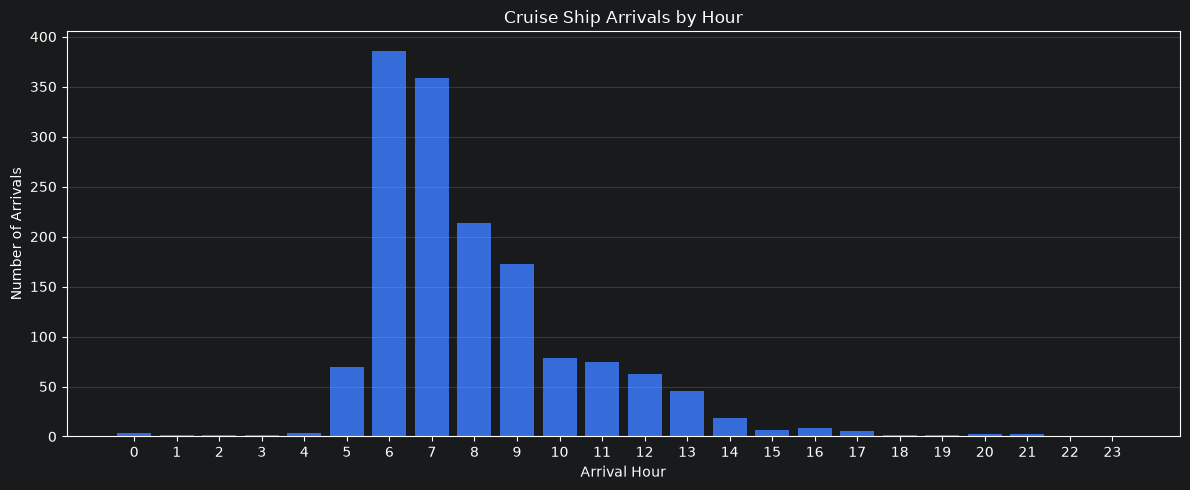

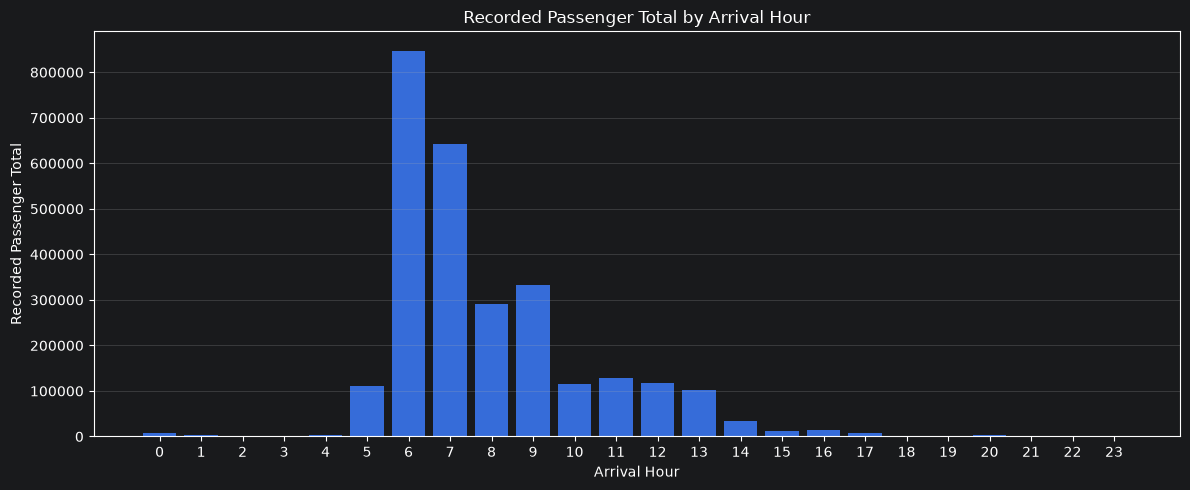

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
file_path = "./data/i.csv"
df = pd.read_csv(file_path, encoding="euc-kr")


# 2. 입항 데이터만 추출
df["입항일시"] = pd.to_datetime(
    df["입항일시"],
    errors="coerce"
)

df["승객"] = pd.to_numeric(
    df["승객"],
    errors="coerce"
)

inbound = df[
    (df["입출"].astype(str).str.strip() == "입항")
    & (df["입항일시"].notna())
].copy()

# 3. 분석 기간 확인
print("===== 분석 대상 =====")
print("입항 데이터 건수:", len(inbound))
print("분석 시작일:", inbound["입항일시"].min())
print("분석 종료일:", inbound["입항일시"].max())

# 4. 시간대별 입항 척수
inbound["입항시간"] = inbound["입항일시"].dt.hour

hourly = (
    inbound.groupby("입항시간")
    .agg(
        입항척수=("입항일시", "size"),
        승객기록건수=("승객", "count"),
        기록승객합계=("승객", "sum"),
        기록승객평균=("승객", "mean"),
        기록승객중앙값=("승객", "median")
    )
    .reindex(range(24), fill_value=0)
)

print("\n===== 시간대별 입항 및 승객 규모 =====")
print(hourly.round(2).to_string())

# 5. 시간대별 입항 척수 그래프
plt.figure(figsize=(12, 5))
plt.bar(hourly.index, hourly["입항척수"])
plt.xticks(range(24))
plt.xlabel("Arrival Hour")
plt.ylabel("Number of Arrivals")
plt.title("Cruise Ship Arrivals by Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. 시간대별 기록 승객 합계 그래프
plt.figure(figsize=(12, 5))
plt.bar(hourly.index, hourly["기록승객합계"])
plt.xticks(range(24))
plt.xlabel("Arrival Hour")
plt.ylabel("Recorded Passenger Total")
plt.title("Recorded Passenger Total by Arrival Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

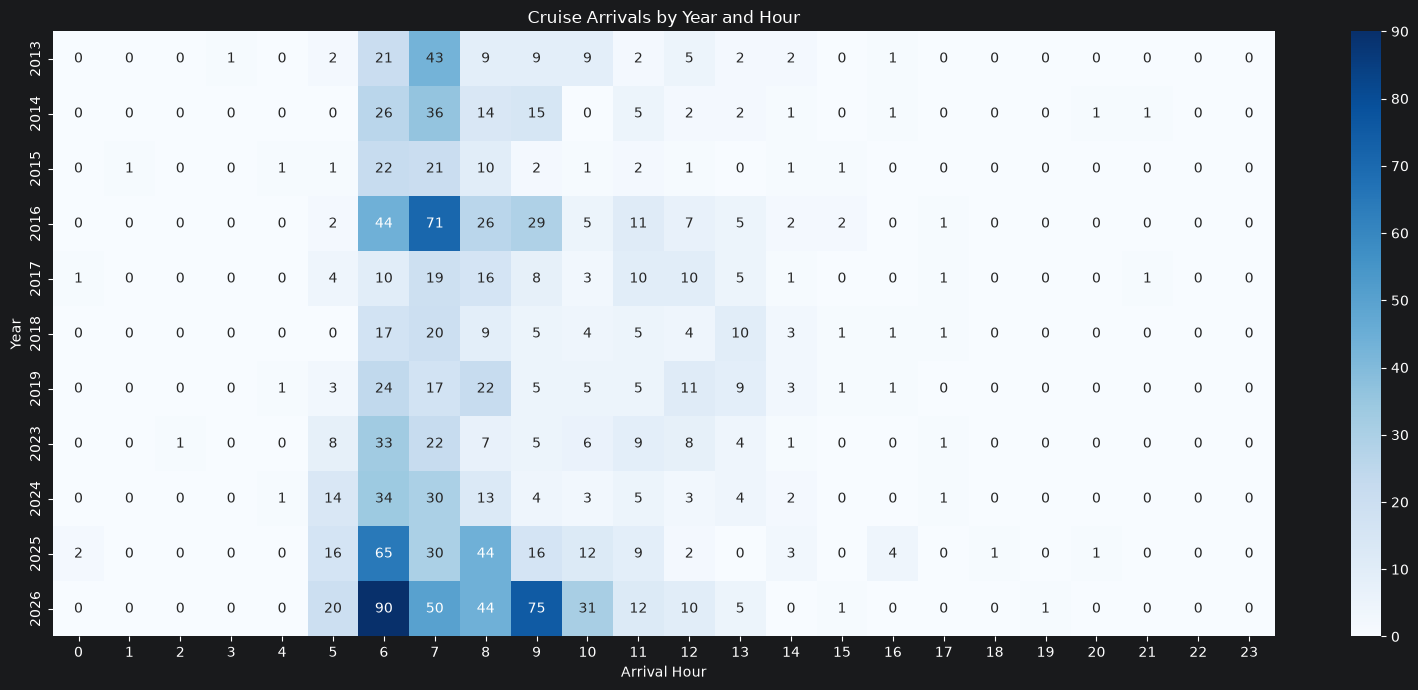

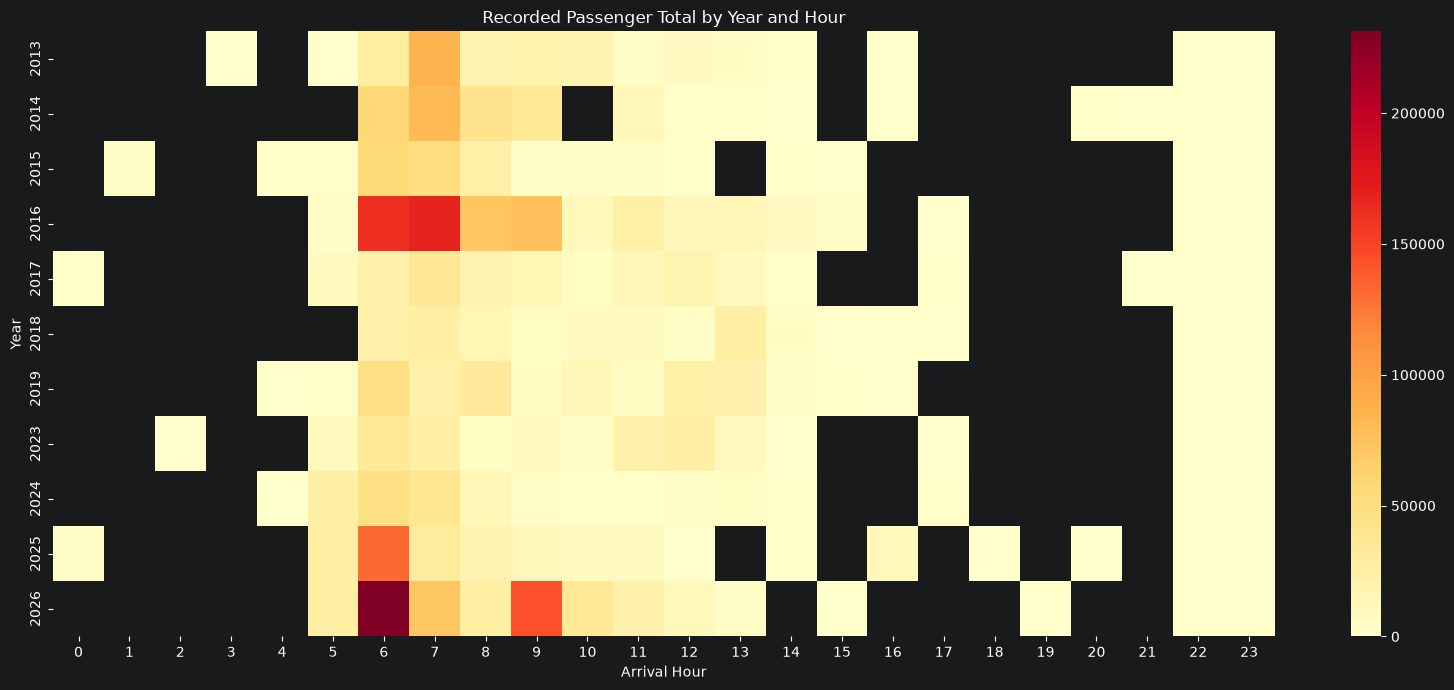

===== 연도별 시간대 승객 결측 항차 수 =====
시간    0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
연도                                                                                                  
2013   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2014   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2015   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2016   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2017   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2018   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2019   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2023   0   0   0   0   0   0   0   0   0   0   0   0   0   0

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 df가 없다면 먼저 CSV를 불러오세요.
# df = pd.read_csv("i(3).csv", encoding="cp949")

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)
df["승객"] = pd.to_numeric(df["승객"], errors="coerce")

inbound = df[
    (df["입출"].astype(str).str.strip() == "입항")
    & df["입항일시"].notna()
].copy()

inbound["연도"] = inbound["입항일시"].dt.year
inbound["시간"] = inbound["입항일시"].dt.hour

# 연도 × 시간대별 입항 척수
arrival_pivot = inbound.pivot_table(
    index="연도",
    columns="시간",
    values="입항일시",
    aggfunc="count",
    fill_value=0
).reindex(columns=range(24), fill_value=0)

# 연도 × 시간대별 기록 승객 합계
passenger_pivot = inbound.pivot_table(
    index="연도",
    columns="시간",
    values="승객",
    aggfunc="sum"
).reindex(columns=range(24), fill_value=0)

# 연도 × 시간대별 승객 결측 항차 수
missing_pivot = inbound.assign(
    승객결측=inbound["승객"].isna().astype(int)
).pivot_table(
    index="연도",
    columns="시간",
    values="승객결측",
    aggfunc="sum",
    fill_value=0
).reindex(columns=range(24), fill_value=0)

# 1. 연도별 시간대 입항 척수
plt.figure(figsize=(16, 7))
sns.heatmap(
    arrival_pivot,
    cmap="Blues",
    annot=True,
    fmt=".0f"
)
plt.title("Cruise Arrivals by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 2. 연도별 시간대 기록 승객 합계
plt.figure(figsize=(16, 7))
sns.heatmap(
    passenger_pivot,
    cmap="YlOrRd",
    annot=False,
    fmt=".0f"
)
plt.title("Recorded Passenger Total by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 3. 연도별 시간대 승객 결측 항차 수
print("===== 연도별 시간대 승객 결측 항차 수 =====")
print(missing_pivot.to_string())

# 4. 연도별 입항 척수 및 승객 기록 현황
year_summary = inbound.groupby("연도").agg(
    입항척수=("입항일시", "size"),
    승객기록건수=("승객", "count"),
    승객결측건수=("승객", lambda s: s.isna().sum()),
    기록승객합계=("승객", "sum")
)

print("\n===== 연도별 데이터 현황 =====")
print(year_summary.to_string())

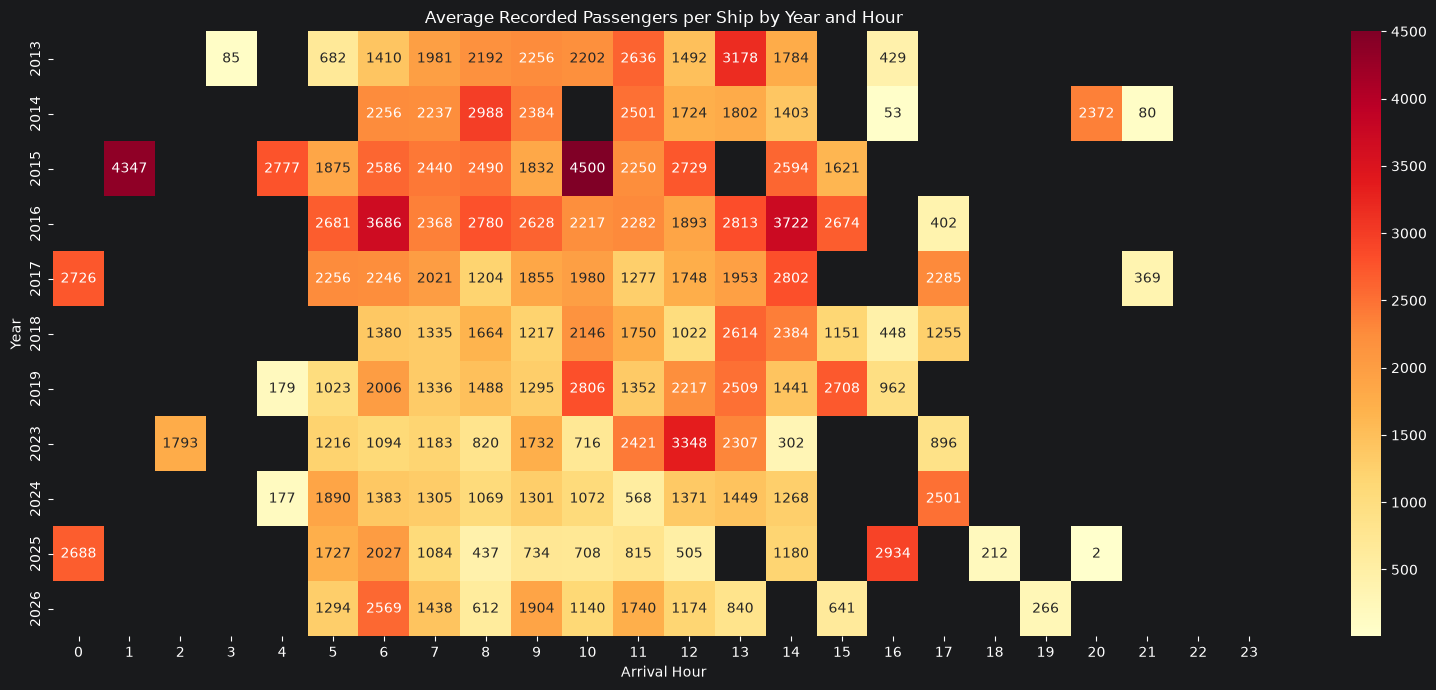

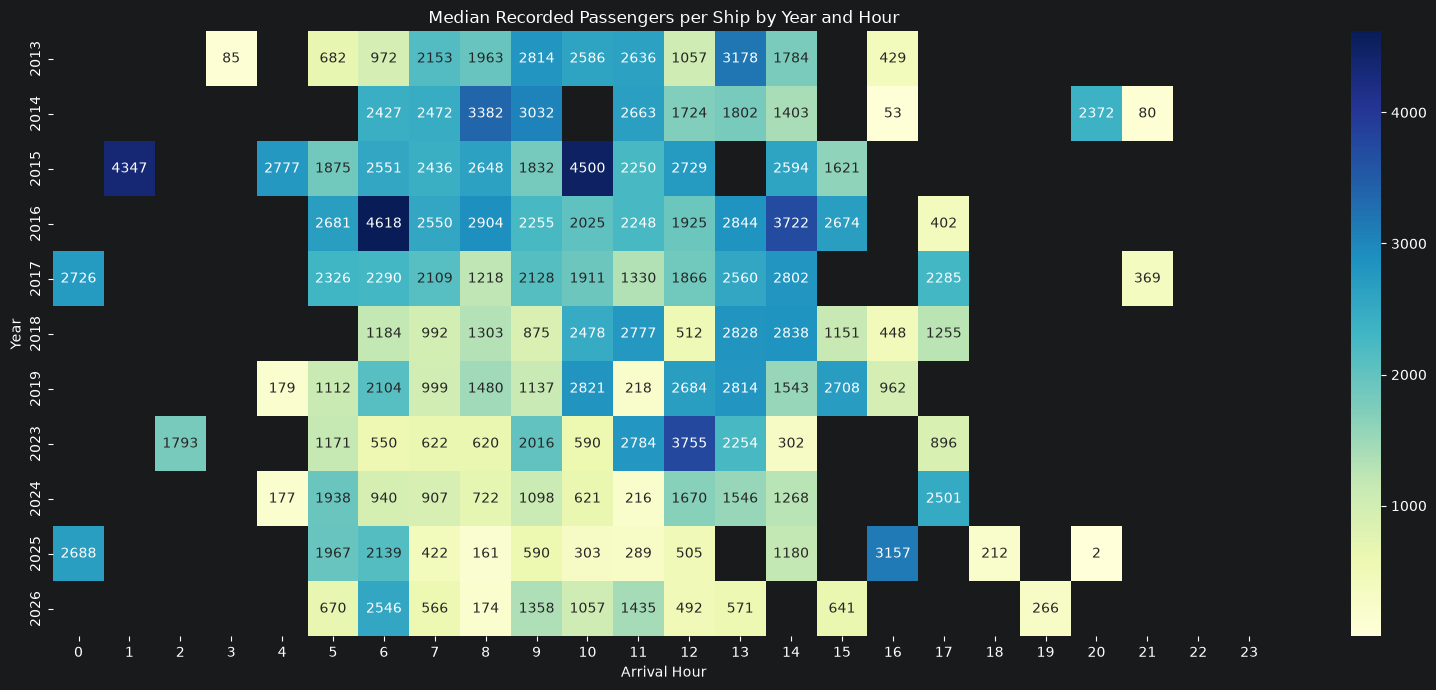

===== 연도별·시간대별 입항 척수 =====
시간     0    1    2    3    4     5     6     7     8     9     10    11    12    13   14   15   16   17   18   19   20   21  22  23
연도                                                                                                                                 
2013  NaN  NaN  NaN  1.0  NaN   2.0  21.0  43.0   9.0   9.0   9.0   2.0   5.0   2.0  2.0  NaN  1.0  NaN  NaN  NaN  NaN  NaN   0   0
2014  NaN  NaN  NaN  NaN  NaN   NaN  26.0  36.0  14.0  15.0   NaN   5.0   2.0   2.0  1.0  NaN  1.0  NaN  NaN  NaN  1.0  1.0   0   0
2015  NaN  1.0  NaN  NaN  1.0   1.0  22.0  21.0  10.0   2.0   1.0   2.0   1.0   NaN  1.0  1.0  NaN  NaN  NaN  NaN  NaN  NaN   0   0
2016  NaN  NaN  NaN  NaN  NaN   2.0  44.0  71.0  26.0  29.0   5.0  11.0   7.0   5.0  2.0  2.0  NaN  1.0  NaN  NaN  NaN  NaN   0   0
2017  1.0  NaN  NaN  NaN  NaN   4.0  10.0  19.0  16.0   8.0   3.0  10.0  10.0   5.0  1.0  NaN  NaN  1.0  NaN  NaN  NaN  1.0   0   0
2018  NaN  NaN  NaN  NaN  NaN   NaN  17.0  20.0  

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 데이터 준비
# ==========================================

# 기존 df가 없다면 아래 줄의 주석을 해제하세요.
# df = pd.read_csv("i(3).csv", encoding="cp949")

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)
df["승객"] = pd.to_numeric(
    df["승객"], errors="coerce"
)

inbound = df[
    (df["입출"].astype(str).str.strip() == "입항")
    & df["입항일시"].notna()
].copy()

inbound["연도"] = inbound["입항일시"].dt.year
inbound["시간"] = inbound["입항일시"].dt.hour

# 승객 기록이 있는 항차만 평균과 중앙값 계산에 사용
valid = inbound.dropna(subset=["승객"]).copy()

# ==========================================
# 2. 연도별·시간대별 통계
# ==========================================

hourly_stats = valid.groupby(
    ["연도", "시간"]
).agg(
    입항척수=("입항일시", "size"),
    기록승객평균=("승객", "mean"),
    기록승객중앙값=("승객", "median"),
    기록승객합계=("승객", "sum")
).reset_index()

# 0~23시 전체 시간대를 표시
years = sorted(inbound["연도"].unique())

def make_pivot(column):
    return (
        hourly_stats.pivot(
            index="연도",
            columns="시간",
            values=column
        )
        .reindex(index=years, columns=range(24))
    )

mean_pivot = make_pivot("기록승객평균")
median_pivot = make_pivot("기록승객중앙값")

# ==========================================
# 3. 시간대별 선박 1척당 기록 승객 평균
# ==========================================

plt.figure(figsize=(16, 7))
sns.heatmap(
    mean_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    mask=mean_pivot.isna()
)
plt.title("Average Recorded Passengers per Ship by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# ==========================================
# 4. 시간대별 선박 1척당 기록 승객 중앙값
# ==========================================

plt.figure(figsize=(16, 7))
sns.heatmap(
    median_pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    mask=median_pivot.isna()
)
plt.title("Median Recorded Passengers per Ship by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# ==========================================
# 5. 시간대별 표본 수 확인
# ==========================================

count_pivot = (
    inbound.pivot_table(
        index="연도",
        columns="시간",
        values="입항일시",
        aggfunc="count"
    )
    .reindex(index=years, columns=range(24), fill_value=0)
)

print("===== 연도별·시간대별 입항 척수 =====")
print(count_pivot.to_string())

print("\n===== 연도별·시간대별 기록 승객 평균 =====")
print(mean_pivot.round(1).to_string())

print("\n===== 연도별·시간대별 기록 승객 중앙값 =====")
print(median_pivot.round(1).to_string())

# ==========================================
# 6. 오전 5~10시 핵심 시간대 요약
# ==========================================

core = hourly_stats[
    hourly_stats["시간"].between(5, 10)
].copy()

print("\n===== 오전 5~10시 요약 =====")
print(
    core.sort_values(["시간", "연도"]).to_string(
        index=False,
        formatters={
            "기록승객평균": "{:.1f}".format,
            "기록승객중앙값": "{:.1f}".format,
            "기록승객합계": "{:.0f}".format
        }
    )
)


In [35]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

===== 2025년·2026년 동일 기간 시간대별 비교 =====
  기간  시간  입항척수  승객기록건수   기록승객합계  기록승객평균  기록승객중앙값
2025   0     2       2   5376.0  2688.0   2688.0
2025   5    16      16  27626.0  1726.6   1967.0
2025   6    65      65 131778.0  2027.4   2139.0
2025   7    30      30  32509.0  1083.6    422.0
2025   8    44      44  19216.0   436.7    161.0
2025   9    16      16  11749.0   734.3    590.0
2025  10    12      11   7792.0   708.4    303.0
2025  11     9       9   7333.0   814.8    289.0
2025  12     2       2   1010.0   505.0    505.0
2025  14     3       2   2360.0  1180.0   1180.0
2025  16     4       4  11734.0  2933.5   3157.0
2025  18     1       1    212.0   212.0    212.0
2025  20     1       1      2.0     2.0      2.0
2026   5    20      20  25873.0  1293.6    670.5
2026   6    90      90 231240.0  2569.3   2545.5
2026   7    50      50  71906.0  1438.1    565.5
2026   8    44      44  26944.0   612.4    173.5
2026   9    75      75 142803.0  1904.0   1358.0
2026  10    31      31  35349.0

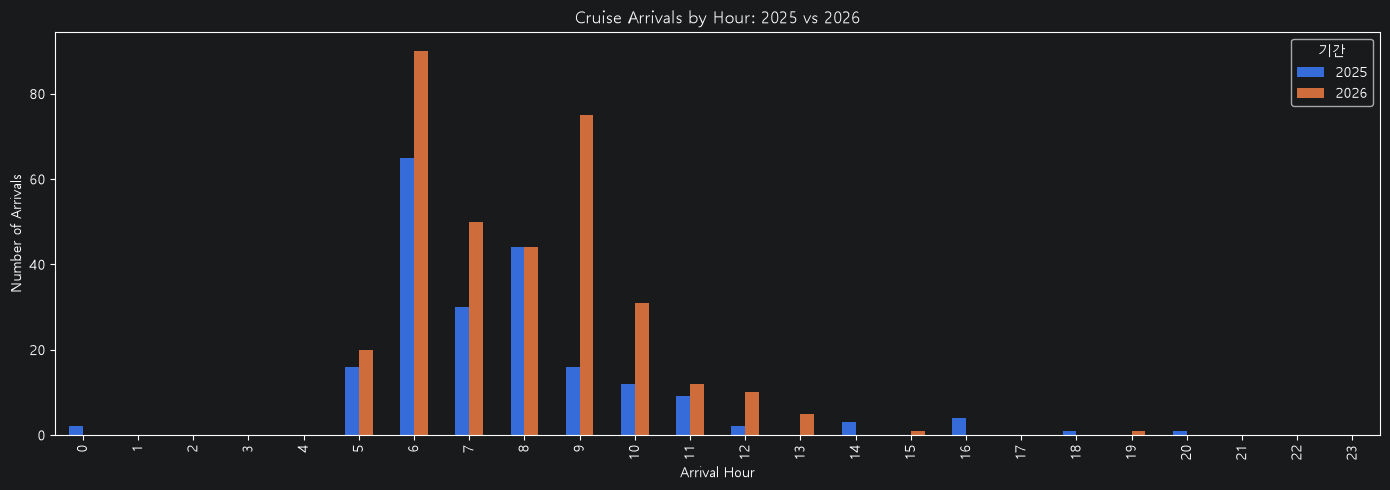

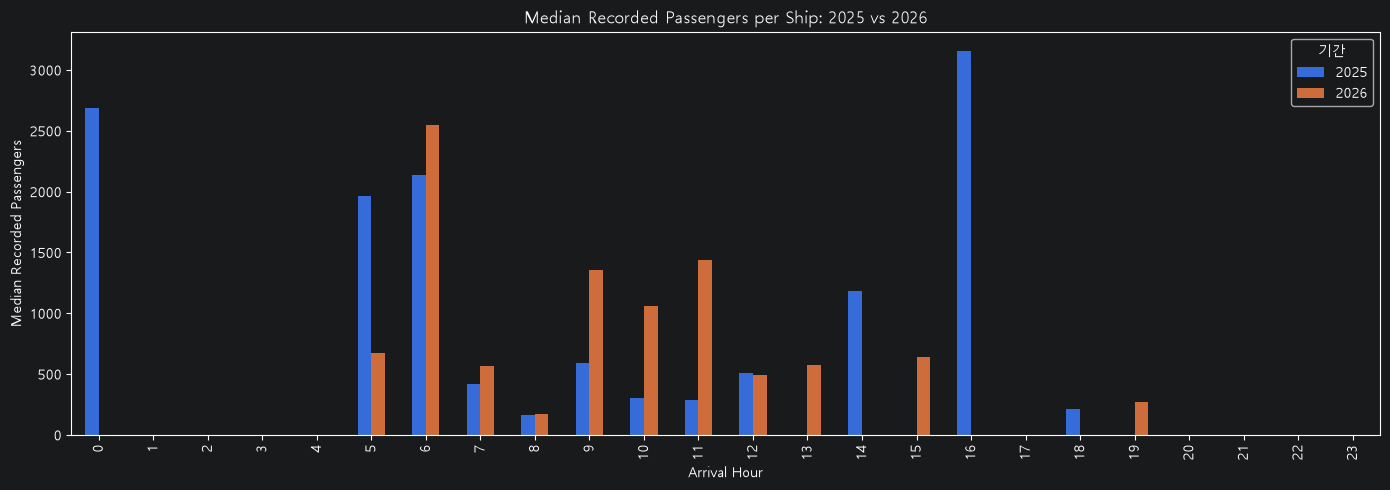

In [36]:
# 2025년과 2026년 동일 기간 비교
start_date = pd.Timestamp("2025-01-01")
end_date = pd.Timestamp("2026-10-16 23:59:59")

recent = inbound[
    inbound["입항일시"].between(start_date, end_date)
    & inbound["연도"].isin([2025, 2026])
].copy()

recent["기간"] = recent["연도"].astype(str)

# 시간대별 통계
recent_hourly = recent.groupby(
    ["기간", "시간"]
).agg(
    입항척수=("입항일시", "size"),
    승객기록건수=("승객", "count"),
    기록승객합계=("승객", "sum"),
    기록승객평균=("승객", "mean"),
    기록승객중앙값=("승객", "median")
).reset_index()

print("===== 2025년·2026년 동일 기간 시간대별 비교 =====")
print(
    recent_hourly.round(1).to_string(index=False)
)

# 입항 척수 비교
arrival_compare = recent_hourly.pivot(
    index="시간",
    columns="기간",
    values="입항척수"
).reindex(range(24), fill_value=0)

arrival_compare.plot(
    kind="bar",
    figsize=(14, 5)
)
plt.title("Cruise Arrivals by Hour: 2025 vs 2026")
plt.xlabel("Arrival Hour")
plt.ylabel("Number of Arrivals")
plt.tight_layout()
plt.show()

# 선박당 기록 승객 중앙값 비교
median_compare = recent_hourly.pivot(
    index="시간",
    columns="기간",
    values="기록승객중앙값"
).reindex(range(24))

median_compare.plot(
    kind="bar",
    figsize=(14, 5)
)
plt.title("Median Recorded Passengers per Ship: 2025 vs 2026")
plt.xlabel("Arrival Hour")
plt.ylabel("Median Recorded Passengers")
plt.tight_layout()
plt.show()

In [37]:

import pandas as pd
import numpy as np

# 최근 연도별 시간대 통계
# recent_hourly가 이미 생성되어 있다는 전제입니다.

comparison = recent_hourly.copy()

# 시간대별로 2025년·2026년 지표를 나란히 배치
metrics = [
    "입항척수",
    "승객기록건수",
    "기록승객합계",
    "기록승객평균",
    "기록승객중앙값"
]

wide = comparison.pivot(
    index="시간",
    columns="기간",
    values=metrics
)

# 보기 편하게 열 이름 정리
wide.columns = [
    f"{year}_{metric}" for metric, year in wide.columns
]

wide = wide.reindex(range(24))

# 핵심 시간대만 별도 확인
core = wide.loc[5:12].copy()

print("===== 오전 5~12시 운영계획 검토표 =====")
print(core.round(1).to_string())

# 시간대별 차이 계산
for metric in ["입항척수", "기록승객평균", "기록승객중앙값"]:
    col_2025 = f"2025_{metric}"
    col_2026 = f"2026_{metric}"

    if col_2025 in wide.columns and col_2026 in wide.columns:
        wide[f"차이_{metric}"] = wide[col_2026] - wide[col_2025]

print("\n===== 2025년 대비 2026년 변화 =====")
print(
    wide.loc[5:12, [
        "2025_입항척수",
        "2026_입항척수",
        "차이_입항척수",
        "2025_기록승객중앙값",
        "2026_기록승객중앙값",
        "차이_기록승객중앙값"
    ]].round(1).to_string()
)


===== 오전 5~12시 운영계획 검토표 =====
    2025_입항척수  2026_입항척수  2025_승객기록건수  2026_승객기록건수  2025_기록승객합계  2026_기록승객합계  2025_기록승객평균  2026_기록승객평균  2025_기록승객중앙값  2026_기록승객중앙값
시간                                                                                                                                
5        16.0       20.0         16.0         20.0      27626.0      25873.0       1726.6       1293.6        1967.0         670.5
6        65.0       90.0         65.0         90.0     131778.0     231240.0       2027.4       2569.3        2139.0        2545.5
7        30.0       50.0         30.0         50.0      32509.0      71906.0       1083.6       1438.1         422.0         565.5
8        44.0       44.0         44.0         44.0      19216.0      26944.0        436.7        612.4         161.0         173.5
9        16.0       75.0         16.0         75.0      11749.0     142803.0        734.3       1904.0         590.0        1358.0
10       12.0       31.0         11.0         31.0   

===== 연도별 시간대 입항 비중(%) =====
시간     0    1    2    3    4     5     6     7     8     9    10    11    12    13   14   15   16   17   18   19   20   21   22   23
연도                                                                                                                                  
2013  0.0  0.0  0.0  0.9  0.0   1.9  19.8  40.6   8.5   8.5  8.5   1.9   4.7   1.9  1.9  0.0  0.9  0.0  0.0  0.0  0.0  0.0  0.0  0.0
2014  0.0  0.0  0.0  0.0  0.0   0.0  25.0  34.6  13.5  14.4  0.0   4.8   1.9   1.9  1.0  0.0  1.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0
2015  0.0  1.6  0.0  0.0  1.6   1.6  34.4  32.8  15.6   3.1  1.6   3.1   1.6   0.0  1.6  1.6  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
2016  0.0  0.0  0.0  0.0  0.0   1.0  21.5  34.6  12.7  14.1  2.4   5.4   3.4   2.4  1.0  1.0  0.0  0.5  0.0  0.0  0.0  0.0  0.0  0.0
2017  1.1  0.0  0.0  0.0  0.0   4.5  11.2  21.3  18.0   9.0  3.4  11.2  11.2   5.6  1.1  0.0  0.0  1.1  0.0  0.0  0.0  1.1  0.0  0.0
2018  0.0  0.0  0.0  0.0  0.0   0.0  21.

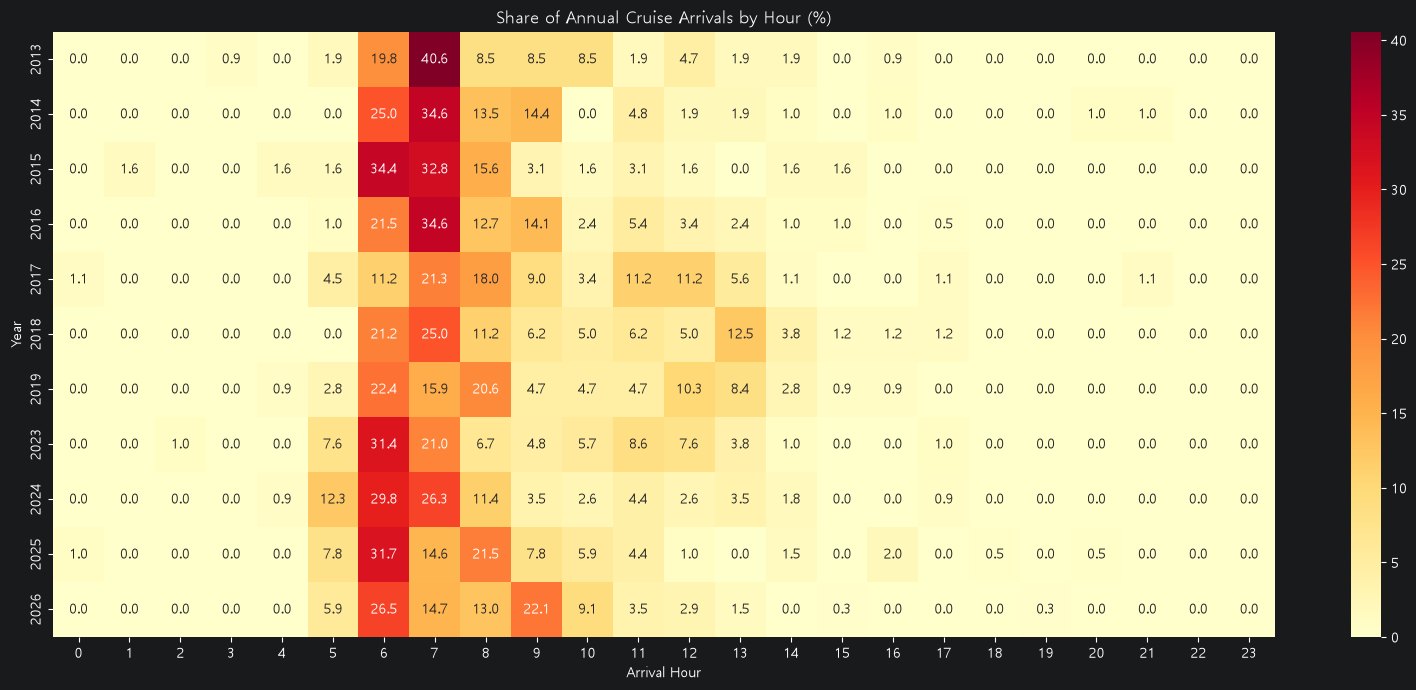


===== 전체 기간 시간대별 입항 비중 =====
    입항척수  전체입항중비중(%)
시간                  
0      3        0.20
1      1        0.07
2      1        0.07
3      1        0.07
4      3        0.20
5     70        4.61
6    386       25.43
7    359       23.65
8    214       14.10
9    173       11.40
10    79        5.20
11    75        4.94
12    63        4.15
13    46        3.03
14    19        1.25
15     6        0.40
16     8        0.53
17     5        0.33
18     1        0.07
19     1        0.07
20     2        0.13
21     2        0.13
22     0        0.00
23     0        0.00

===== 연도별 전체 입항 척수 =====
      연간입항척수
연도          
2013     106
2014     104
2015      64
2016     205
2017      89
2018      80
2019     107
2023     105
2024     114
2025     205
2026     339

===== 연도별 오전 5~12시 입항 비중 =====
연도
2013    94.34
2014    94.23
2015    93.75
2016    95.12
2017    89.89
2018    80.00
2019    85.98
2023    93.33
2024    92.98
2025    94.63
2026    97.94


In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 분석 데이터 준비
# ==========================================

# 기존 inbound가 없다면 원본 데이터에서 생성하세요.
# df = pd.read_csv("i(3).csv", encoding="cp949")
# df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")
# inbound = df[
#     (df["입출"].astype(str).str.strip() == "입항")
#     & df["입항일시"].notna()
# ].copy()

inbound["연도"] = inbound["입항일시"].dt.year
inbound["시간"] = inbound["입항일시"].dt.hour

# 시간대별 입항 척수
year_hour_count = (
    inbound.groupby(["연도", "시간"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

# ==========================================
# 2. 연도별 시간대 비중(%)
# ==========================================

year_hour_share = (
    year_hour_count
    .div(year_hour_count.sum(axis=1), axis=0)
    * 100
)

print("===== 연도별 시간대 입항 비중(%) =====")
print(year_hour_share.round(1).to_string())

# ==========================================
# 3. 연도별 시간대 비중 히트맵
# ==========================================

plt.figure(figsize=(16, 7))

sns.heatmap(
    year_hour_share,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f"
)

plt.title("Share of Annual Cruise Arrivals by Hour (%)")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# ==========================================
# 4. 전체 기간 시간대별 입항 비중
# ==========================================

overall_hour_count = (
    inbound["시간"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

overall_hour_share = (
    overall_hour_count / overall_hour_count.sum() * 100
)

overall_summary = pd.DataFrame({
    "입항척수": overall_hour_count,
    "전체입항중비중(%)": overall_hour_share
})

print("\n===== 전체 기간 시간대별 입항 비중 =====")
print(overall_summary.round(2).to_string())

# ==========================================
# 5. 연도별 입항 규모 확인
# ==========================================

year_summary = year_hour_count.sum(axis=1).to_frame("연간입항척수")

print("\n===== 연도별 전체 입항 척수 =====")
print(year_summary.to_string())

# ==========================================
# 6. 오전 5~12시 비중 비교
# ==========================================

morning_hours = list(range(5, 13))

morning_share = year_hour_share[morning_hours].sum(axis=1)

print("\n===== 연도별 오전 5~12시 입항 비중 =====")
print(morning_share.round(2).to_string())

# 2026년은 10월 16일까지의 부분 자료이므로
# 다른 연도와 비교할 때 별도로 해석하세요.



===== 시간대별 입항 척수 및 승객 규모 =====
     입항척수  승객기록항차수     승객수합계    평균승객수  중앙값승객수   최대승객수  승객기록비율(%)
시간                                                              
0     3.0      3.0    8102.0  2700.67  2696.0  2726.0     100.00
1     1.0      1.0    4347.0  4347.00  4347.0  4347.0     100.00
2     1.0      1.0    1793.0  1793.00  1793.0  1793.0     100.00
3     1.0      1.0      85.0    85.00    85.0    85.0     100.00
4     3.0      3.0    3133.0  1044.33   179.0  2777.0     100.00
5    70.0     70.0  110381.0  1576.87  1884.5  5309.0     100.00
6   386.0    386.0  847533.0  2195.68  2154.5  5431.0     100.00
7   359.0    359.0  642485.0  1789.65  1902.0  4910.0     100.00
8   214.0    214.0  291534.0  1362.31   723.5  5152.0     100.00
9   173.0    173.0  331762.0  1917.70  1833.0  5464.0     100.00
10   79.0     78.0  114605.0  1469.29  1194.5  4788.0      98.73
11   75.0     75.0  128500.0  1713.33  1916.0  4913.0     100.00
12   63.0     63.0  116497.0  1849.16  1710.0  4373.0     

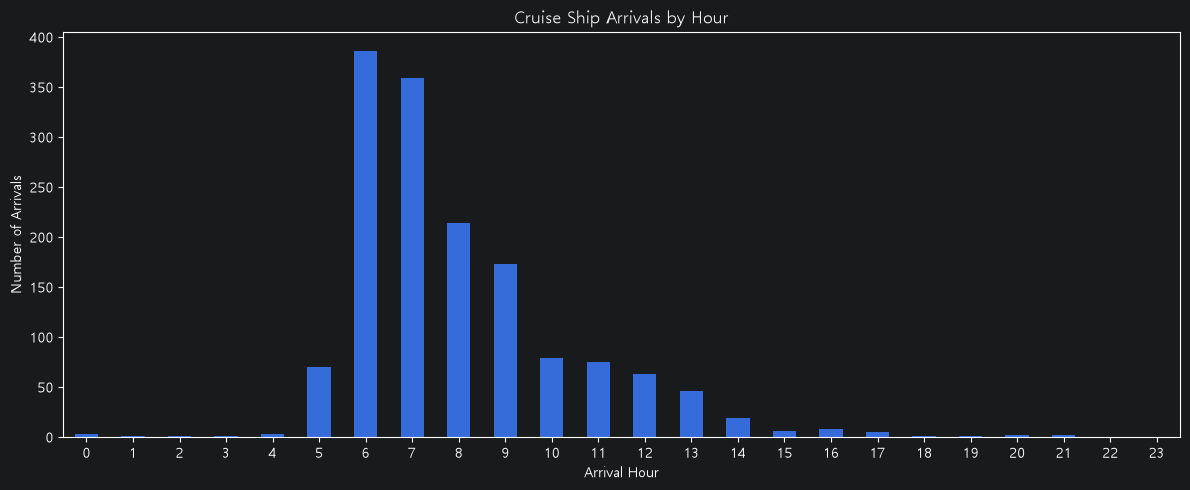

<Figure size 1200x500 with 0 Axes>

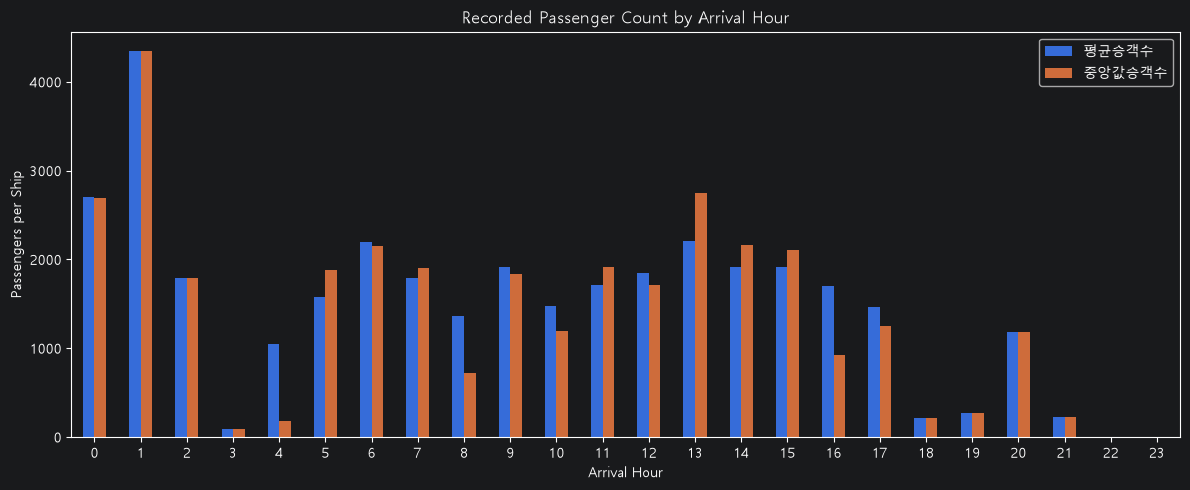

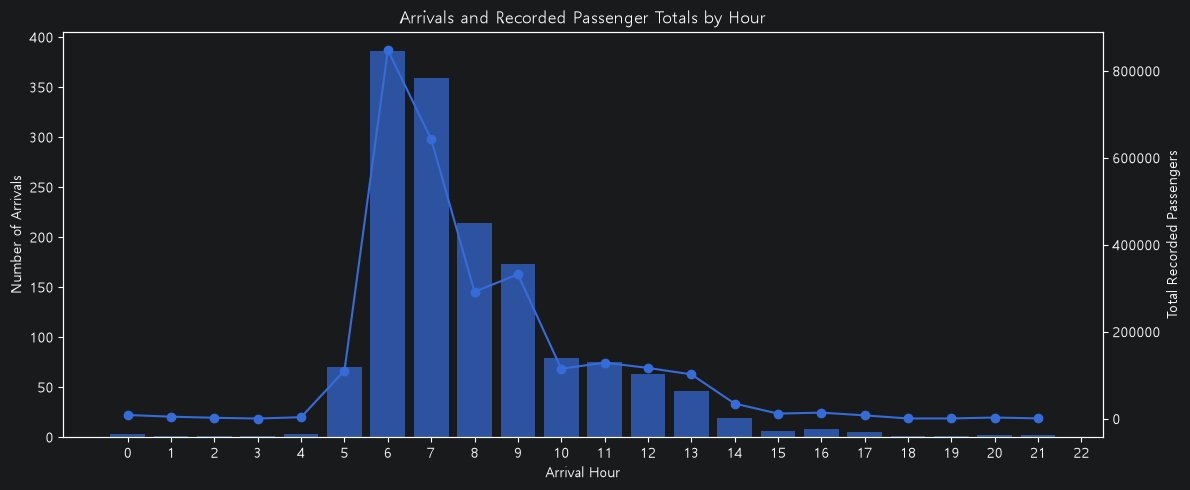

In [39]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 inbound 데이터프레임 사용
# inbound: 입항 자료만 필터링한 데이터
# 입항일시: datetime 형식

df = inbound.copy()

# 입항일시 및 승객 데이터 정리
df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["승객"] = pd.to_numeric(df["승객"], errors="coerce")

df = df.dropna(subset=["입항일시"]).copy()
df["시간"] = df["입항일시"].dt.hour

# 시간대별 입항 척수
hourly_calls = (
    df.groupby("시간")
    .size()
    .rename("입항척수")
)

# 승객 수가 기록된 항차만으로 승객 규모 계산
passenger_df = df.dropna(subset=["승객"]).copy()

hourly_passengers = (
    passenger_df.groupby("시간")["승객"]
    .agg(
        승객기록항차수="count",
        승객수합계="sum",
        평균승객수="mean",
        중앙값승객수="median",
        최대승객수="max"
    )
)

# 두 결과 결합
hourly_summary = pd.concat(
    [hourly_calls, hourly_passengers],
    axis=1
).fillna({
    "입항척수": 0,
    "승객기록항차수": 0
})

hourly_summary["승객기록비율(%)"] = (
    hourly_summary["승객기록항차수"]
    / hourly_summary["입항척수"].replace(0, float("nan"))
    * 100
)

hourly_summary = hourly_summary.reindex(range(24))
hourly_summary.index.name = "시간"

print("\n===== 시간대별 입항 척수 및 승객 규모 =====")
print(hourly_summary.round(2).to_string())

# 전체 입항 중 시간대별 입항 비중
hourly_summary["입항비중(%)"] = (
    hourly_summary["입항척수"]
    / hourly_summary["입항척수"].sum()
    * 100
)

# 승객 수 합계의 시간대별 비중
total_passengers = hourly_summary["승객수합계"].sum()

hourly_summary["승객합계비중(%)"] = (
    hourly_summary["승객수합계"]
    / total_passengers
    * 100
)

print("\n===== 입항 비중과 승객 규모 비중 비교 =====")
print(
    hourly_summary[
        [
            "입항척수",
            "입항비중(%)",
            "승객기록항차수",
            "승객수합계",
            "승객합계비중(%)",
            "평균승객수",
            "중앙값승객수"
        ]
    ].round(2).to_string()
)

# 그래프 1: 시간대별 입항 척수
plt.figure(figsize=(12, 5))
hourly_summary["입항척수"].plot(kind="bar")
plt.title("Cruise Ship Arrivals by Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Number of Arrivals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 그래프 2: 시간대별 평균 및 중앙값 승객 수
plt.figure(figsize=(12, 5))
hourly_summary[
    ["평균승객수", "중앙값승객수"]
].plot(kind="bar", figsize=(12, 5))
plt.title("Recorded Passenger Count by Arrival Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Passengers per Ship")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 그래프 3: 시간대별 입항 척수와 승객 합계
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(
    hourly_summary.index,
    hourly_summary["입항척수"],
    alpha=0.7
)
ax1.set_xlabel("Arrival Hour")
ax1.set_ylabel("Number of Arrivals")
ax1.set_xticks(range(24))

ax2 = ax1.twinx()
ax2.plot(
    hourly_summary.index,
    hourly_summary["승객수합계"],
    marker="o"
)
ax2.set_ylabel("Total Recorded Passengers")

plt.title("Arrivals and Recorded Passenger Totals by Hour")
fig.tight_layout()
plt.show()



===== 동일 기간 연도별 입항·승객 기록 현황 =====
      입항척수  승객기록항차수  승객기록률(%)
연도                           
2013   102      102    100.00
2014    95       95    100.00
2015    48       48    100.00
2016   172      172    100.00
2017    87       87    100.00
2018    71       71    100.00
2019    94       94    100.00
2023    89       89    100.00
2024    94       94    100.00
2025   158      157     99.37
2026   339      339    100.00

===== 연도별 시간대 입항 척수 =====
시간    0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
연도                                                                                                  
2013   0   0   0   1   0   2  19  43   9   9   9   2   4   2   2   0   0   0   0   0   0   0   0   0
2014   0   0   0   0   0   0  24  32  14  15   0   3   2   2   1   0   0   0   0   0   1   1   0   0
2015   0   0   0   0   1   1  15  18   9   1   0   1   1   0   1   0   0   0   0   0   0   0   0   0
2016   0   0   0   0   0   2  34  60  23  2

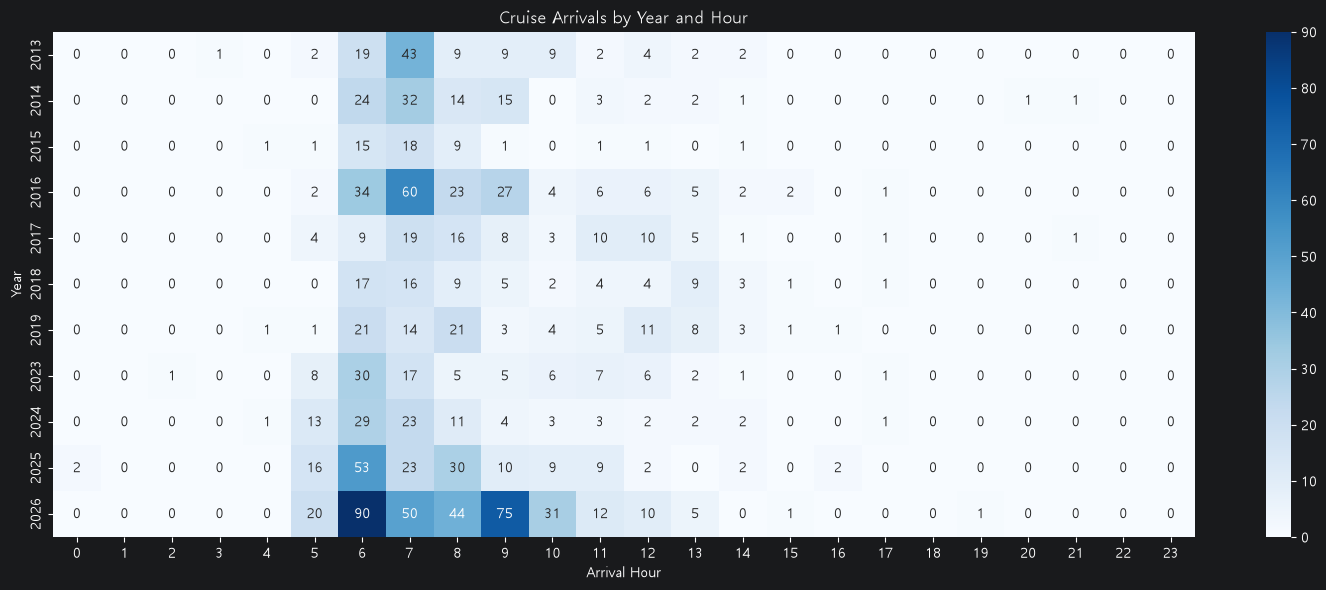

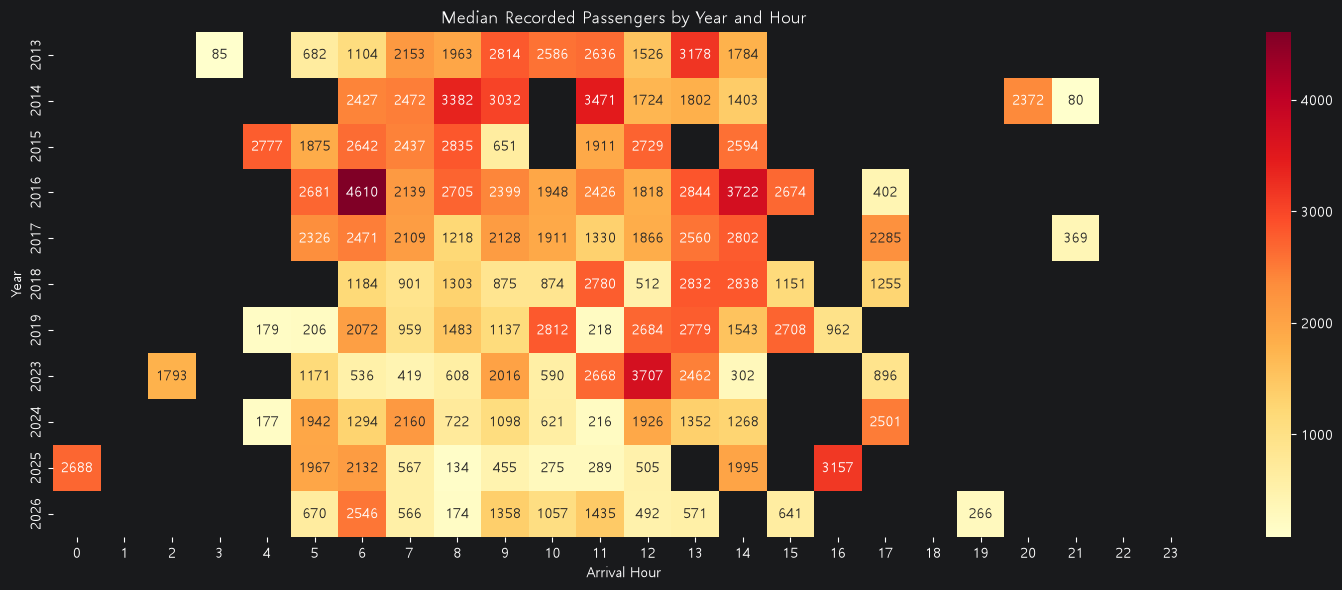

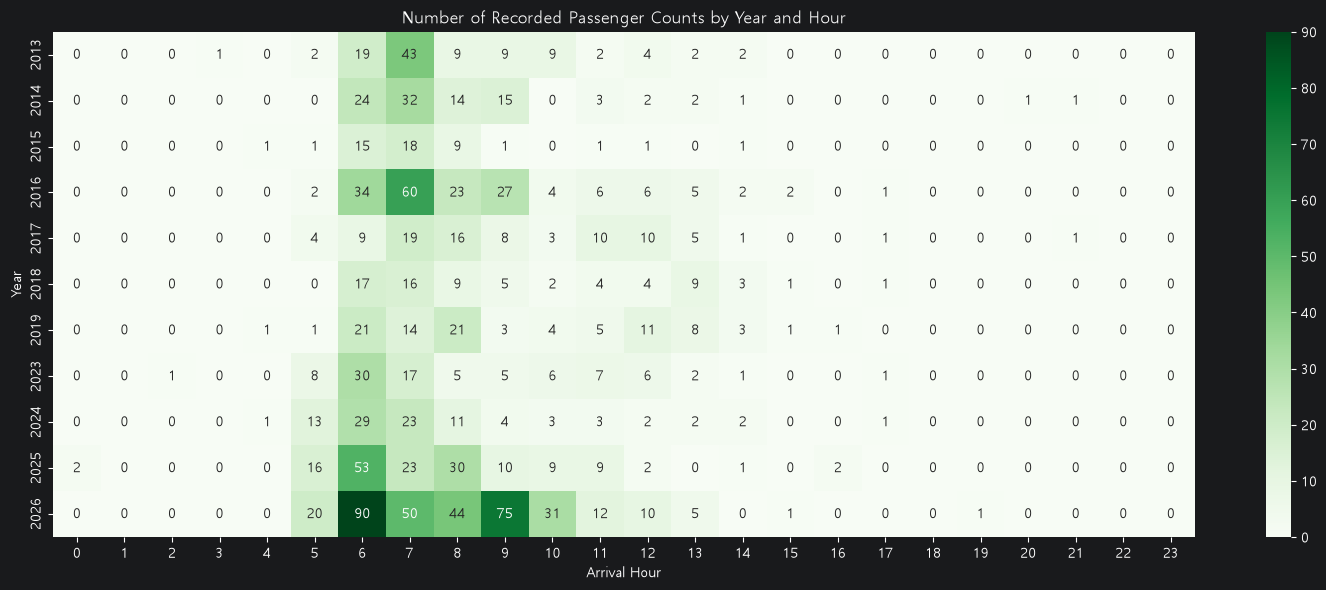

In [40]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 inbound 데이터 사용
df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)
df["승객"] = pd.to_numeric(
    df["승객"], errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

# 연도별 비교 기간 통일: 1월 1일~10월 16일
df = df[
    (df["입항일시"].dt.month < 10)
    | (
        (df["입항일시"].dt.month == 10)
        & (df["입항일시"].dt.day <= 16)
    )
].copy()

df["연도"] = df["입항일시"].dt.year
df["시간"] = df["입항일시"].dt.hour

# 승객 기록이 있는 항차만 별도로 집계
passenger_df = df.dropna(subset=["승객"]).copy()

# 1. 연도별·시간대별 입항 척수
calls = (
    df.groupby(["연도", "시간"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

# 2. 연도별·시간대별 승객 중앙값
passenger_median = (
    passenger_df.groupby(["연도", "시간"])["승객"]
    .median()
    .unstack()
    .reindex(columns=range(24))
)

# 3. 연도별·시간대별 평균 승객 수
passenger_mean = (
    passenger_df.groupby(["연도", "시간"])["승객"]
    .mean()
    .unstack()
    .reindex(columns=range(24))
)

# 4. 연도별·시간대별 승객 기록 항차 수
passenger_count = (
    passenger_df.groupby(["연도", "시간"])["승객"]
    .count()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

# 연도별 총 입항 척수 및 승객 기록률
year_summary = pd.DataFrame({
    "입항척수": df.groupby("연도").size(),
    "승객기록항차수": passenger_df.groupby("연도").size()
})

year_summary["승객기록률(%)"] = (
    year_summary["승객기록항차수"]
    / year_summary["입항척수"]
    * 100
)

print("\n===== 동일 기간 연도별 입항·승객 기록 현황 =====")
print(year_summary.round(2).to_string())

print("\n===== 연도별 시간대 입항 척수 =====")
print(calls.to_string())

print("\n===== 연도별 시간대 승객 중앙값 =====")
print(passenger_median.round(1).to_string())

print("\n===== 연도별 시간대 승객 기록 항차 수 =====")
print(passenger_count.to_string())

# 그래프 1: 연도별·시간대별 입항 척수
plt.figure(figsize=(15, 6))
sns.heatmap(
    calls,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Cruise Arrivals by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 그래프 2: 연도별·시간대별 승객 중앙값
plt.figure(figsize=(15, 6))
sns.heatmap(
    passenger_median,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)
plt.title("Median Recorded Passengers by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 그래프 3: 연도별·시간대별 승객 기록 항차 수
plt.figure(figsize=(15, 6))
sns.heatmap(
    passenger_count,
    annot=True,
    fmt="d",
    cmap="Greens"
)
plt.title("Number of Recorded Passenger Counts by Year and Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Year")
plt.tight_layout()
plt.show()



===== 연도별·월별 입항 척수 =====
월     1   2   3   4   5   6   7   8   9   10  11  12
연도                                                  
2013  10   0   7  13  13  15  14  12   9  12   1   0
2014   1   4   7  10  13  22  14   9  10   9   3   2
2015   0   1   3   7  11   8   2   6   5  10   9   2
2016   7   5   7  12  25  17  23  32  30  23  15   9
2017   9  11   9  12  10   1   7  11  12   7   0   0
2018   0   2   4  15  13   8   6   9   9  11   3   0
2019   2   1   6  23  18   7   9  12  11  11   4   3
2023   0   0  10  23  13  12   4   6  10  20   7   0
2024   0   2  15  23  17  14   3   5   9   9   4  13
2025   9   5  17  35  28  13  10  14  17  19  23  15

===== 월별 입항 척수 =====
월
1      38
2      31
3      85
4     173
5     161
6     117
7      92
8     116
9     122
10    131
11     69
12     44

===== 월별·시간대별 입항 척수 =====
시간  0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
월                                                                   

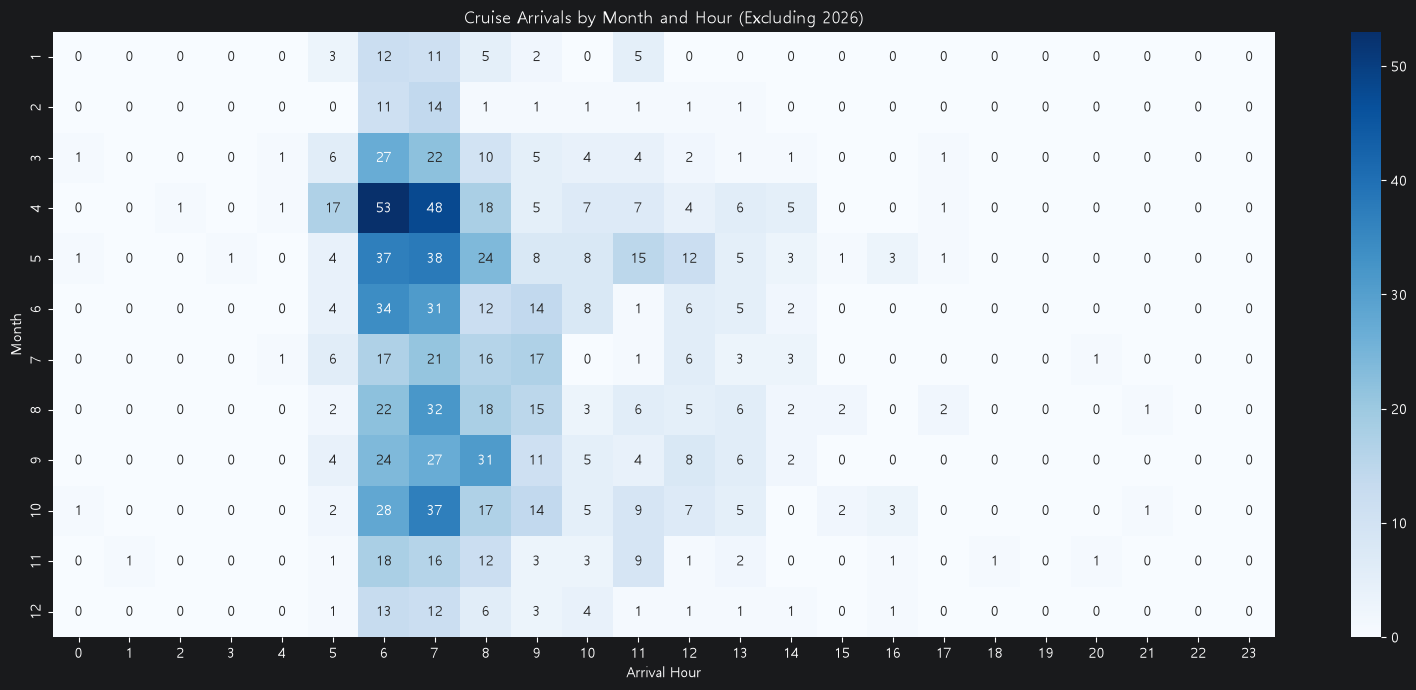


===== 월별·시간대별 승객 중앙값 =====
시간  0   1   2   3   4       5       6       7       8       9       10      11      12      13     14  15  16  17  18  19  20  21  22  23
월                                                                                                                                        
1  NaN NaN NaN NaN NaN     NaN  3453.5   754.0   933.0     NaN     NaN  1659.0     NaN     NaN    NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN
2  NaN NaN NaN NaN NaN     NaN  1890.0  2515.5     NaN     NaN     NaN     NaN     NaN     NaN    NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN
3  NaN NaN NaN NaN NaN  1874.5  1899.0  1512.5   880.0   730.0     NaN     NaN     NaN     NaN    NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN
4  NaN NaN NaN NaN NaN  1950.0  1218.0   802.5   802.0   619.0   301.0   407.0     NaN  2796.0  558.0 NaN NaN NaN NaN NaN NaN NaN NaN NaN
5  NaN NaN NaN NaN NaN     NaN  1945.0  1826.5  1777.5  2003.5   979.5   218.0  2775.5  2844.0    NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN
6  NaN

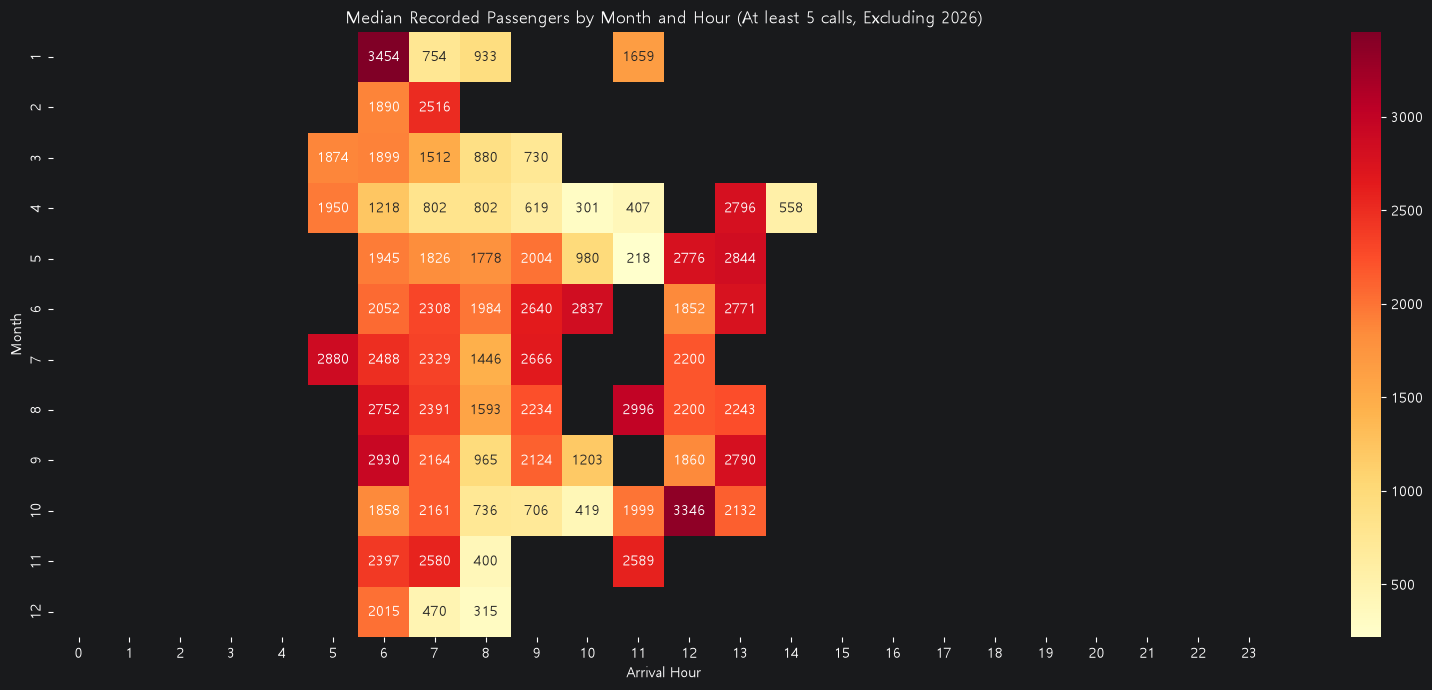


===== 월별 시간대 입항 비중(%) =====
시간   0    1    2    3    4    5     6     7     8     9    10    11   12   13   14   15   16   17   18   19   20   21   22   23
월                                                                                                                              
1   0.0  0.0  0.0  0.0  0.0  7.9  31.6  28.9  13.2   5.3  0.0  13.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
2   0.0  0.0  0.0  0.0  0.0  0.0  35.5  45.2   3.2   3.2  3.2   3.2  3.2  3.2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
3   1.2  0.0  0.0  0.0  1.2  7.1  31.8  25.9  11.8   5.9  4.7   4.7  2.4  1.2  1.2  0.0  0.0  1.2  0.0  0.0  0.0  0.0  0.0  0.0
4   0.0  0.0  0.6  0.0  0.6  9.8  30.6  27.7  10.4   2.9  4.0   4.0  2.3  3.5  2.9  0.0  0.0  0.6  0.0  0.0  0.0  0.0  0.0  0.0
5   0.6  0.0  0.0  0.6  0.0  2.5  23.0  23.6  14.9   5.0  5.0   9.3  7.5  3.1  1.9  0.6  1.9  0.6  0.0  0.0  0.0  0.0  0.0  0.0
6   0.0  0.0  0.0  0.0  0.0  3.4  29.1  26.5  10.3  12.0  6.8   0.9  5.1  4

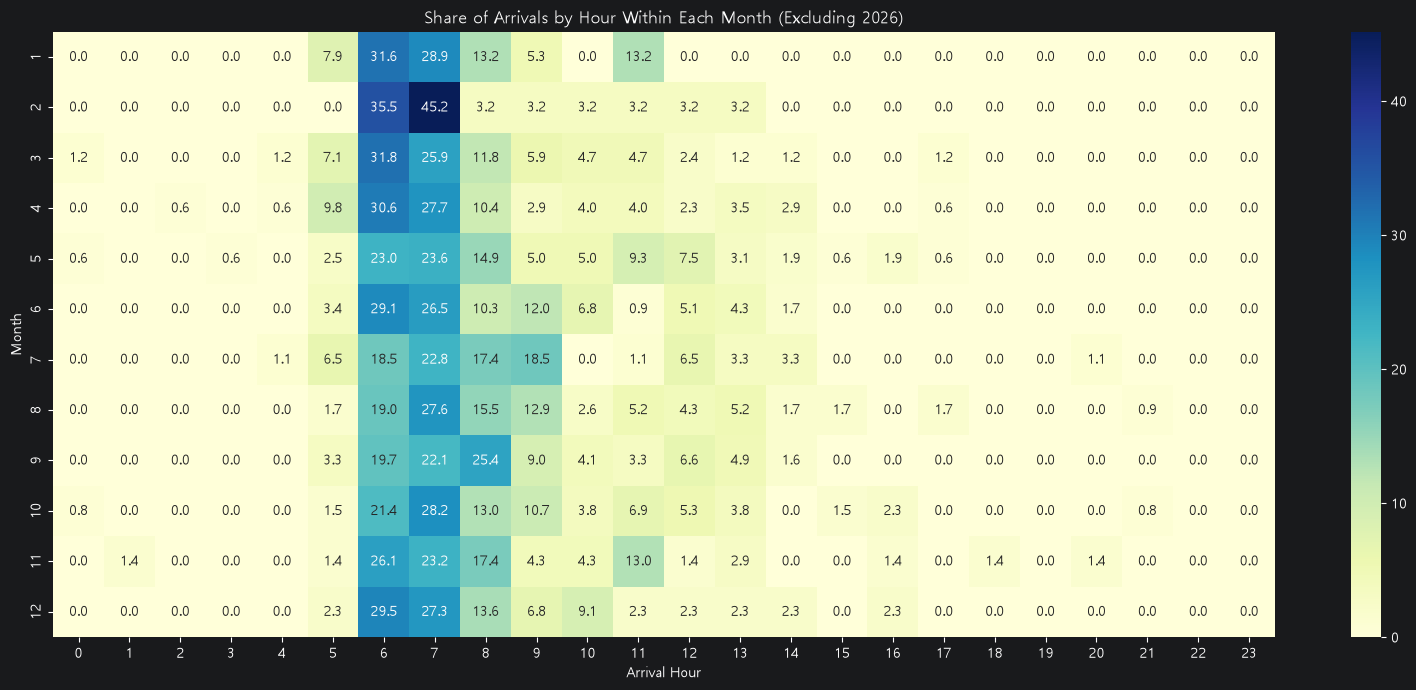

In [41]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 inbound 데이터 사용
df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)
df["승객"] = pd.to_numeric(
    df["승객"], errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month
df["시간"] = df["입항일시"].dt.hour

# 2026년은 10월 16일까지이므로
# 월별·시간대별 패턴 비교에서는 2026년을 제외
# 2013~2019, 2023~2025년 자료 사용
df_compare = df[df["연도"] != 2026].copy()

# ----------------------------------
# 1. 연도별·월별 입항 척수
# ----------------------------------
year_month_calls = (
    df_compare.groupby(["연도", "월"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

print("\n===== 연도별·월별 입항 척수 =====")
print(year_month_calls.to_string())

# ----------------------------------
# 2. 월별 전체 입항 척수
# ----------------------------------
monthly_calls = (
    df_compare.groupby("월")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

print("\n===== 월별 입항 척수 =====")
print(monthly_calls.to_string())

# ----------------------------------
# 3. 월별·시간대별 입항 척수
# ----------------------------------
month_hour_calls = (
    df_compare.groupby(["월", "시간"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(1, 13),
             columns=range(24),
             fill_value=0)
)

print("\n===== 월별·시간대별 입항 척수 =====")
print(month_hour_calls.to_string())

# 히트맵: 월별·시간대별 입항 척수
plt.figure(figsize=(16, 7))
sns.heatmap(
    month_hour_calls,
    cmap="Blues",
    annot=True,
    fmt="d"
)
plt.title("Cruise Arrivals by Month and Hour (Excluding 2026)")
plt.xlabel("Arrival Hour")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

# ----------------------------------
# 4. 월별·시간대별 승객 중앙값
# ----------------------------------
passenger_df = df_compare.dropna(subset=["승객"]).copy()

month_hour_median = (
    passenger_df.groupby(["월", "시간"])["승객"]
    .median()
    .unstack()
    .reindex(index=range(1, 13),
             columns=range(24))
)

# 각 조합의 승객 기록 항차 수
month_hour_n = (
    passenger_df.groupby(["월", "시간"])["승객"]
    .count()
    .unstack(fill_value=0)
    .reindex(index=range(1, 13),
             columns=range(24),
             fill_value=0)
)

# 표본이 5척 미만인 조합은 중앙값을 숨겨
# 소수 항차로 인한 과도한 해석을 방지
month_hour_median_masked = month_hour_median.where(
    month_hour_n >= 5
)

print("\n===== 월별·시간대별 승객 중앙값 =====")
print(month_hour_median_masked.round(1).to_string())

print("\n===== 월별·시간대별 승객 기록 항차 수 =====")
print(month_hour_n.to_string())

plt.figure(figsize=(16, 7))
sns.heatmap(
    month_hour_median_masked,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)
plt.title(
    "Median Recorded Passengers by Month and Hour "
    "(At least 5 calls, Excluding 2026)"
)
plt.xlabel("Arrival Hour")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

# ----------------------------------
# 5. 월별 입항 시간대 비중(%)
# ----------------------------------
month_hour_share = (
    month_hour_calls
    .div(month_hour_calls.sum(axis=1).replace(0, float("nan")),
         axis=0)
    * 100
)

print("\n===== 월별 시간대 입항 비중(%) =====")
print(month_hour_share.round(1).to_string())

plt.figure(figsize=(16, 7))
sns.heatmap(
    month_hour_share,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f"
)
plt.title(
    "Share of Arrivals by Hour Within Each Month "
    "(Excluding 2026)"
)
plt.xlabel("Arrival Hour")
plt.ylabel("Month")
plt.tight_layout()
plt.show()



===== 연도별 월 입항 척수 =====
월     1   2   3   4   5   6   7   8   9   10
연도                                          
2013  10   0   7  13  13  15  14  12   9   9
2014   1   4   7  10  13  22  14   9  10   5
2015   0   1   3   7  11   8   2   6   5   5
2016   7   5   7  12  25  17  23  32  30  14
2017   9  11   9  12  10   1   7  11  12   5
2018   0   2   4  15  13   8   6   9   9   5
2019   2   1   6  23  18   7   9  12  11   5
2023   0   0  10  23  13  12   4   6  10  11
2024   0   2  15  23  17  14   3   5   9   6
2025   9   5  17  35  28  13  10  14  17  10

===== 연도별 월 입항 비중(%) =====
월       1     2     3     4     5     6     7     8     9     10
연도                                                              
2013   9.8   0.0   6.9  12.7  12.7  14.7  13.7  11.8   8.8   8.8
2014   1.1   4.2   7.4  10.5  13.7  23.2  14.7   9.5  10.5   5.3
2015   0.0   2.1   6.2  14.6  22.9  16.7   4.2  12.5  10.4  10.4
2016   4.1   2.9   4.1   7.0  14.5   9.9  13.4  18.6  17.4   8.1
2017  10.3  12.6 

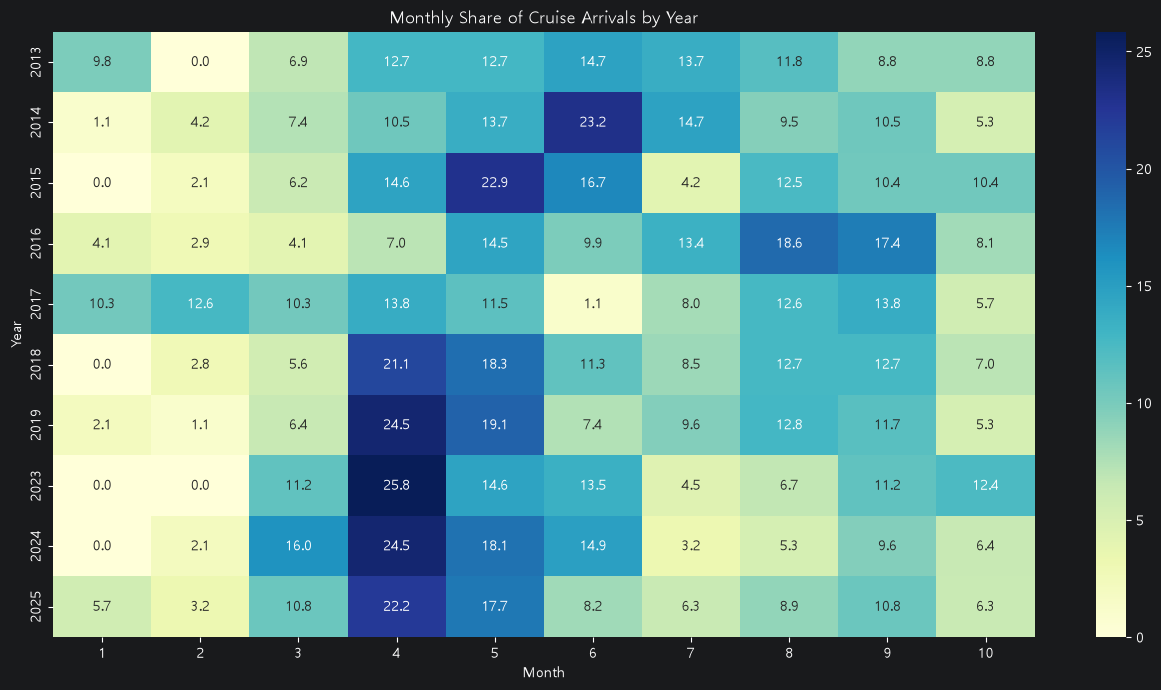


===== 연도별 월 입항 비중의 평균 =====
월
1      3.31
2      3.10
3      8.49
4     17.67
5     16.32
6     12.09
7      8.61
8     11.14
9     11.69
10     7.58


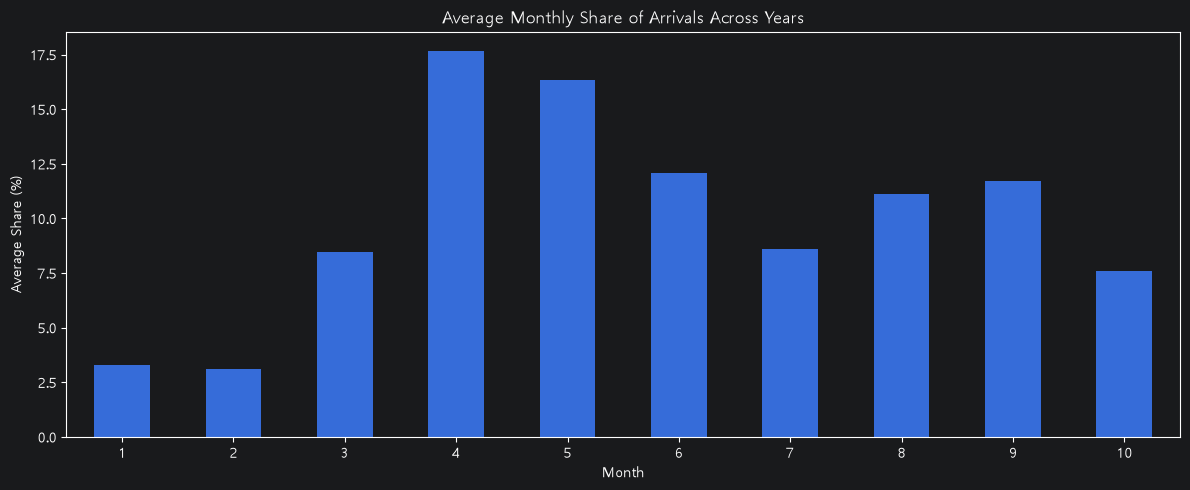


===== 연도별 입항 비중 최다 월 =====
      입항비중이_가장_높은_월  해당월_입항비중(%)
연도                              
2013              6        14.71
2014              6        23.16
2015              5        22.92
2016              8        18.60
2017              4        13.79
2018              4        21.13
2019              4        24.47
2023              4        25.84
2024              4        24.47
2025              4        22.15


In [42]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

# 비교 기간 통일: 매년 1월 1일~10월 16일
df = df[
    (df["입항일시"].dt.month < 10)
    | (
        (df["입항일시"].dt.month == 10)
        & (df["입항일시"].dt.day <= 16)
    )
].copy()

# 2026년 제외
df = df[df["입항일시"].dt.year != 2026].copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 1. 연도별 월 입항 척수
year_month_calls = (
    df.groupby(["연도", "월"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 11), fill_value=0)
)

# 2. 각 연도 안에서 월별 입항 비중(%)
year_month_share = (
    year_month_calls
    .div(year_month_calls.sum(axis=1), axis=0)
    * 100
)

print("\n===== 연도별 월 입항 척수 =====")
print(year_month_calls.to_string())

print("\n===== 연도별 월 입항 비중(%) =====")
print(year_month_share.round(1).to_string())

# 3. 연도별 월 입항 비중 히트맵
plt.figure(figsize=(13, 7))
sns.heatmap(
    year_month_share,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)
plt.title("Monthly Share of Cruise Arrivals by Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 4. 월별 입항 비중의 연도 간 평균
# 각 연도의 월별 비중을 동일한 가중치로 평균
monthly_share_mean = year_month_share.mean(axis=0)

print("\n===== 연도별 월 입항 비중의 평균 =====")
print(monthly_share_mean.round(2).to_string())

plt.figure(figsize=(12, 5))
monthly_share_mean.plot(kind="bar")
plt.title("Average Monthly Share of Arrivals Across Years")
plt.xlabel("Month")
plt.ylabel("Average Share (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 5. 각 연도에서 입항 비중이 가장 높았던 달
peak_month = year_month_share.idxmax(axis=1)
peak_share = year_month_share.max(axis=1)

peak_summary = pd.DataFrame({
    "입항비중이_가장_높은_월": peak_month,
    "해당월_입항비중(%)": peak_share
})

print("\n===== 연도별 입항 비중 최다 월 =====")
print(peak_summary.round(2).to_string())


===== 연도별 월 입항 척수 =====
월     1   2   3   4   5   6   7   8   9   10  11  12
연도                                                  
2013  10   0   7  13  13  15  14  12   9  12   1   0
2014   1   4   7  10  13  22  14   9  10   9   3   2
2015   0   1   3   7  11   8   2   6   5  10   9   2
2016   7   5   7  12  25  17  23  32  30  23  15   9
2017   9  11   9  12  10   1   7  11  12   7   0   0
2018   0   2   4  15  13   8   6   9   9  11   3   0
2019   2   1   6  23  18   7   9  12  11  11   4   3
2023   0   0  10  23  13  12   4   6  10  20   7   0
2024   0   2  15  23  17  14   3   5   9   9   4  13
2025   9   5  17  35  28  13  10  14  17  19  23  15

===== 연도별 월 입항 비중(%) =====
월       1     2     3     4     5     6     7     8     9     10    11    12
연도                                                                          
2013   9.4   0.0   6.6  12.3  12.3  14.2  13.2  11.3   8.5  11.3   0.9   0.0
2014   1.0   3.8   6.7   9.6  12.5  21.2  13.5   8.7   9.6   8.7   2.9   1.9
2015

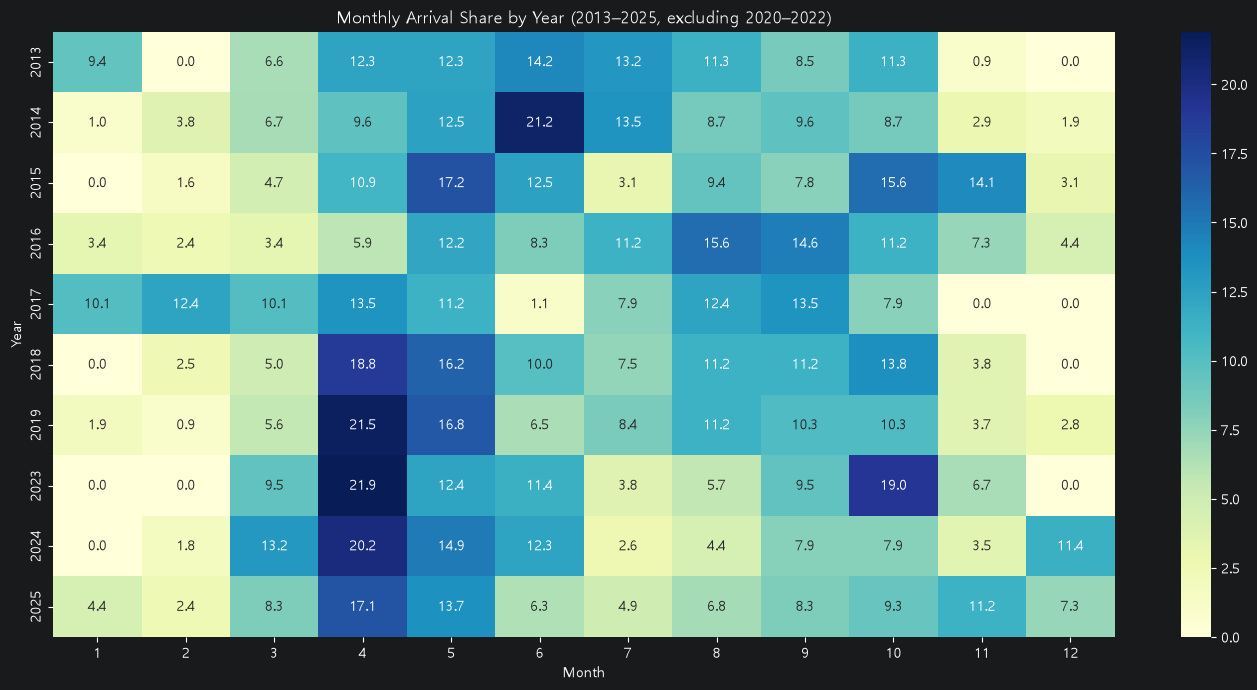

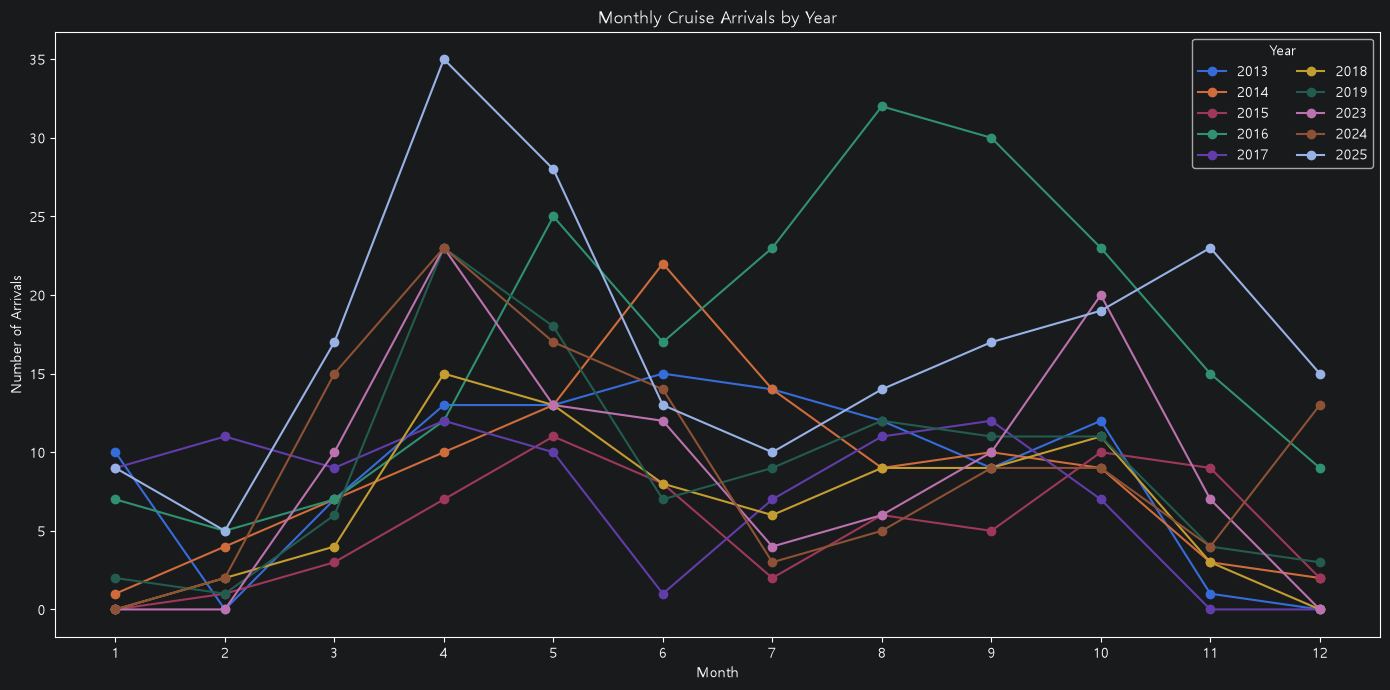

In [43]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 inbound 데이터 사용
df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 2026년은 부분 연도이므로 장기 패턴 분석에서 제외
complete_years = df[df["연도"].isin(
    [2013, 2014, 2015, 2016, 2017,
     2018, 2019, 2023, 2024, 2025]
)].copy()

# 연도별 월 입항 척수
monthly_calls = (
    complete_years
    .groupby(["연도", "월"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

# 연도별 월 입항 비중(%)
monthly_share = (
    monthly_calls
    .div(monthly_calls.sum(axis=1), axis=0)
    * 100
)

# 1. 연도별 월 입항 척수
print("===== 연도별 월 입항 척수 =====")
print(monthly_calls.to_string())

# 2. 연도별 월 입항 비중
print("\n===== 연도별 월 입항 비중(%) =====")
print(monthly_share.round(1).to_string())

# 3. 월별 입항 척수의 연도 간 변동성
monthly_stats = pd.DataFrame({
    "평균입항척수": monthly_calls.mean(axis=0),
    "표준편차": monthly_calls.std(axis=0),
    "최소입항척수": monthly_calls.min(axis=0),
    "최대입항척수": monthly_calls.max(axis=0)
})

print("\n===== 월별 입항 척수 변동성 =====")
print(monthly_stats.round(2).to_string())

# 4. 월별 입항 비중의 연도 간 변동성
share_stats = pd.DataFrame({
    "평균비중(%)": monthly_share.mean(axis=0),
    "비중표준편차(%p)": monthly_share.std(axis=0),
    "최소비중(%)": monthly_share.min(axis=0),
    "최대비중(%)": monthly_share.max(axis=0)
})

print("\n===== 월별 입항 비중 변동성 =====")
print(share_stats.round(2).to_string())

# 5. 월별 입항 비중 히트맵
plt.figure(figsize=(14, 7))
sns.heatmap(
    monthly_share,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)
plt.title("Monthly Arrival Share by Year (2013–2025, excluding 2020–2022)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# 6. 월별 입항 척수의 연도별 추이
plt.figure(figsize=(14, 7))

for year in monthly_calls.index:
    plt.plot(
        monthly_calls.columns,
        monthly_calls.loc[year],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Cruise Arrivals by Year")
plt.xlabel("Month")
plt.ylabel("Number of Arrivals")
plt.xticks(range(1, 13))
plt.legend(title="Year", ncol=2)
plt.tight_layout()
plt.show()


In [44]:

import pandas as pd
import numpy as np

# 기존 inbound 데이터 사용
df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)
df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 완전한 연도만 사용
years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

df = df[df["연도"].isin(years)].copy()

# 연도 × 월 입항 척수표
monthly_calls = (
    df.groupby(["연도", "월"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=years, columns=range(1, 13), fill_value=0)
)

# 과거 연도만 이용해 다음 관측 연도를 예측
results = []

for i in range(3, len(years)):
    test_year = years[i]
    previous_years = years[:i]

    # 기준모델: 과거 자료에서 해당 월의 평균 입항 척수
    forecast = monthly_calls.loc[previous_years].mean(axis=0)
    actual = monthly_calls.loc[test_year]

    for month in range(1, 13):
        results.append({
            "예측연도": test_year,
            "월": month,
            "과거평균예측": forecast.loc[month],
            "실제입항척수": actual.loc[month],
            "절대오차": abs(
                forecast.loc[month] - actual.loc[month]
            )
        })

result_df = pd.DataFrame(results)

# 연도별 예측 성능
year_performance = (
    result_df.groupby("예측연도")
    .agg(
        월평균절대오차=("절대오차", "mean"),
        실제월평균입항=("실제입항척수", "mean")
    )
)

print("===== 연도별 예측 성능 =====")
print(year_performance.round(2))

# 전체 월별 예측 성능
print("\n===== 전체 월별 예측 성능 =====")
print(
    "월평균 절대오차(MAE):",
    round(result_df["절대오차"].mean(), 2),
    "척"
)

# 월별로 어느 달의 예측이 어려웠는지 확인
month_performance = (
    result_df.groupby("월")["절대오차"]
    .mean()
    .rename("월평균절대오차")
)

print("\n===== 월별 예측 오차 =====")
print(month_performance.round(2))

# 예측값과 실제값 비교
comparison = result_df.pivot(
    index=["예측연도", "월"],
    columns=None,
    values="실제입항척수"
) if False else result_df[
    ["예측연도", "월", "과거평균예측", "실제입항척수", "절대오차"]
]

print("\n===== 예측값과 실제값 비교 =====")
print(comparison.round(2).to_string(index=False))


===== 연도별 예측 성능 =====
      월평균절대오차  실제월평균입항
예측연도                  
2016     9.47    17.08
2017     5.48     7.42
2018     3.50     6.67
2019     2.78     8.92
2023     4.36     8.75
2024     5.00     9.50
2025     8.06    17.08

===== 전체 월별 예측 성능 =====
월평균 절대오차(MAE): 5.52 척

===== 월별 예측 오차 =====
월
1     4.18
2     3.34
3     4.11
4     8.19
5     5.83
6     4.43
7     5.96
8     7.10
9     5.69
10    5.71
11    6.08
12    5.63
Name: 월평균절대오차, dtype: float64

===== 예측값과 실제값 비교 =====
 예측연도  월  과거평균예측  실제입항척수  절대오차
 2016  1    3.67       7  3.33
 2016  2    1.67       5  3.33
 2016  3    5.67       7  1.33
 2016  4   10.00      12  2.00
 2016  5   12.33      25 12.67
 2016  6   15.00      17  2.00
 2016  7   10.00      23 13.00
 2016  8    9.00      32 23.00
 2016  9    8.00      30 22.00
 2016 10   10.33      23 12.67
 2016 11    4.33      15 10.67
 2016 12    1.33       9  7.67
 2017  1    4.50       9  4.50
 2017  2    2.50      11  8.50
 2017  3    6.00       9  3.00
 2017  4   10.50 

In [45]:

import pandas as pd

# 앞에서 만든 monthly_calls 데이터프레임 사용
# 행: 연도, 열: 월, 값: 입항 척수

years = monthly_calls.index.tolist()
results = []

for i in range(3, len(years)):
    test_year = years[i]
    train_years = years[:i]

    actual = monthly_calls.loc[test_year]
    historical_mean = monthly_calls.loc[train_years].mean(axis=0)
    previous_observed = monthly_calls.loc[years[i - 1]]

    for month in range(1, 13):
        results.append({
            "예측연도": test_year,
            "월": month,
            "실제": actual.loc[month],
            "모델A_과거평균": historical_mean.loc[month],
            "모델B_직전관측연도": previous_observed.loc[month],
        })

comparison = pd.DataFrame(results)

comparison["모델A_절대오차"] = (
    comparison["실제"] - comparison["모델A_과거평균"]
).abs()

comparison["모델B_절대오차"] = (
    comparison["실제"] - comparison["모델B_직전관측연도"]
).abs()

print("===== 모델별 전체 성능 비교 =====")
print(
    comparison[
        ["모델A_절대오차", "모델B_절대오차"]
    ].mean().round(2)
)

print("\n===== 연도별 성능 비교 =====")
for year, group in comparison.groupby("예측연도"):
    print(
        year,
        "모델 A MAE:", round(group["모델A_절대오차"].mean(), 2),
        "모델 B MAE:", round(group["모델B_절대오차"].mean(), 2)
    )

print("\n===== 월별 성능 비교 =====")
print(
    comparison.groupby("월")[
        ["모델A_절대오차", "모델B_절대오차"]
    ].mean().round(2)
)


===== 모델별 전체 성능 비교 =====
모델A_절대오차    5.52
모델B_절대오차    6.39
dtype: float64

===== 연도별 성능 비교 =====
2016 모델 A MAE: 9.47 모델 B MAE: 11.75
2017 모델 A MAE: 5.48 모델 B MAE: 11.33
2018 모델 A MAE: 3.5 모델 B MAE: 4.08
2019 모델 A MAE: 2.78 모델 B MAE: 2.58
2023 모델 A MAE: 4.36 모델 B MAE: 3.67
2024 모델 A MAE: 5.0 모델 B MAE: 3.58
2025 모델 A MAE: 8.06 모델 B MAE: 7.75

===== 월별 성능 비교 =====
    모델A_절대오차  모델B_절대오차
월                     
1       4.18      4.43
2       3.34      3.71
3       4.11      3.43
4       8.19      4.00
5       5.83      8.14
6       4.43      5.86
7       5.96      7.71
8       7.10      9.71
9       5.69      8.29
10      5.71      9.00
11      6.08      7.14
12      5.63      5.29


=== 연도별 입항 건수 ===
  연도  입항건수
2013   106
2014   104
2015    64
2016   205
2017    89
2018    80
2019   107
2023   105
2024   114
2025   205
2026   339

=== 연도별 입항 규모 및 전년 대비 증감률 ===
  연도  입항건수  전년대비증감  전년대비증감률(%)
2013   106     NaN         NaN
2014   104    -2.0       -1.89
2015    64   -40.0      -38.46
2016   205   141.0      220.31
2017    89  -116.0      -56.59
2018    80    -9.0      -10.11
2019   107    27.0       33.75
2023   105     NaN         NaN
2024   114     9.0        8.57
2025   205    91.0       79.82
2026   339   134.0       65.37


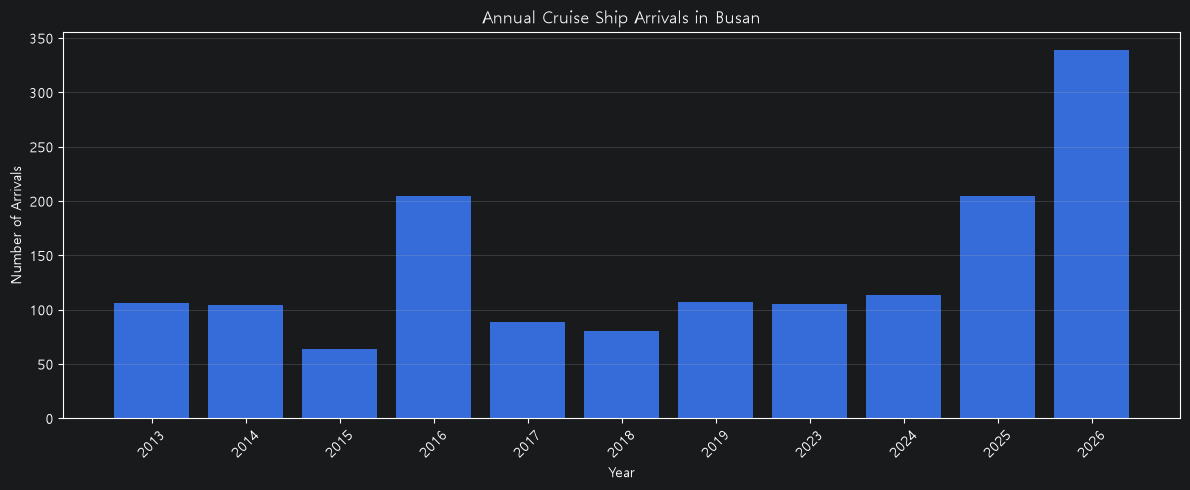

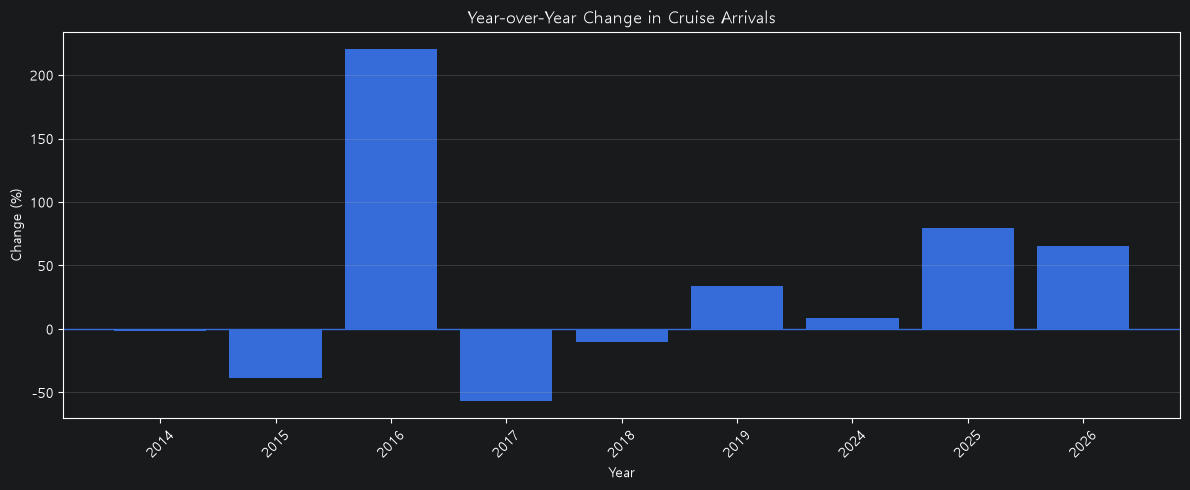

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 데이터 전처리
# ==========================================

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"],
    errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year

# 입항 데이터만 사용
# 이미 inbound가 입항 데이터만 담고 있다면 그대로 사용
yearly_calls = (
    df.groupby("연도")
      .size()
      .rename("입항건수")
      .reset_index()
)

# ==========================================
# 2. 연도별 입항 건수
# ==========================================

print("=== 연도별 입항 건수 ===")
print(yearly_calls.to_string(index=False))

# ==========================================
# 3. 전년 대비 증감률
# ==========================================

yearly_calls["전년대비증감"] = (
    yearly_calls["입항건수"].diff()
)

yearly_calls["전년대비증감률(%)"] = (
    yearly_calls["입항건수"].pct_change() * 100
)

# 실제로 연속된 연도끼리만 전년 대비 증감률 계산
yearly_calls["연도차이"] = yearly_calls["연도"].diff()

yearly_calls.loc[
    yearly_calls["연도차이"] != 1,
    ["전년대비증감", "전년대비증감률(%)"]
] = np.nan

print("\n=== 연도별 입항 규모 및 전년 대비 증감률 ===")
print(
    yearly_calls[
        [
            "연도",
            "입항건수",
            "전년대비증감",
            "전년대비증감률(%)"
        ]
    ].round(2).to_string(index=False)
)

# ==========================================
# 4. 연도별 입항 건수 시각화
# ==========================================

plt.figure(figsize=(12, 5))

plt.bar(
    yearly_calls["연도"].astype(str),
    yearly_calls["입항건수"]
)

plt.title("Annual Cruise Ship Arrivals in Busan")
plt.xlabel("Year")
plt.ylabel("Number of Arrivals")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 5. 전년 대비 증감률 시각화
# ==========================================

valid_growth = yearly_calls.dropna(
    subset=["전년대비증감률(%)"]
)

plt.figure(figsize=(12, 5))

plt.bar(
    valid_growth["연도"].astype(str),
    valid_growth["전년대비증감률(%)"]
)

plt.axhline(0, linewidth=1)

plt.title("Year-over-Year Change in Cruise Arrivals")
plt.xlabel("Year")
plt.ylabel("Change (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
import pandas as pd
import numpy as np

# 완전한 연간 데이터만 사용
# 2026년은 10월 16일까지의 부분 집계이므로 제외
annual = (
    yearly_calls[
        yearly_calls["연도"].isin([
            2013, 2014, 2015, 2016, 2017,
            2018, 2019, 2023, 2024, 2025
        ])
    ][["연도", "입항건수"]]
    .sort_values("연도")
    .reset_index(drop=True)
)

# 연속된 연도끼리만 예측 검증
results = []

for i in range(3, len(annual)):
    current_year = annual.loc[i, "연도"]
    previous_year = annual.loc[i - 1, "연도"]

    # 연도가 연속되지 않으면 건너뜀
    if current_year - previous_year != 1:
        continue

    train = annual.iloc[:i]
    actual = annual.loc[i, "입항건수"]

    # 모델 A: 과거 연간 입항 건수의 평균
    pred_mean = train["입항건수"].mean()

    # 모델 B: 직전 관측 연도의 입항 건수
    pred_last = annual.loc[i - 1, "입항건수"]

    results.append({
        "예측연도": current_year,
        "실제입항건수": actual,
        "과거평균예측": round(pred_mean, 1),
        "직전연도예측": pred_last,
        "과거평균절대오차": abs(actual - pred_mean),
        "직전연도절대오차": abs(actual - pred_last)
    })

result_df = pd.DataFrame(results)

print("=== 연간 입항 건수 예측 검증 ===")
print(result_df.to_string(index=False))

if not result_df.empty:
    print("\n=== 모델별 평균 절대 오차(MAE) ===")
    print(
        "과거 평균 모델:",
        round(result_df["과거평균절대오차"].mean(), 2)
    )
    print(
        "직전 연도 모델:",
        round(result_df["직전연도절대오차"].mean(), 2)
    )

=== 연간 입항 건수 예측 검증 ===
 예측연도  실제입항건수  과거평균예측  직전연도예측   과거평균절대오차  직전연도절대오차
 2016     205    91.3      64 113.666667       141
 2017      89   119.8     205  30.750000       116
 2018      80   113.6      89  33.600000         9
 2019     107   108.0      80   1.000000        27
 2024     114   107.5     105   6.500000         9
 2025     205   108.2     114  96.777778        91

=== 모델별 평균 절대 오차(MAE) ===
과거 평균 모델: 47.05
직전 연도 모델: 65.5


=== 연도별 월별 입항 건수 ===
월     1   2   3   4   5   6   7   8   9   10  11  12
연도                                                  
2013  10   0   7  13  13  15  14  12   9  12   1   0
2014   1   4   7  10  13  22  14   9  10   9   3   2
2015   0   1   3   7  11   8   2   6   5  10   9   2
2016   7   5   7  12  25  17  23  32  30  23  15   9
2017   9  11   9  12  10   1   7  11  12   7   0   0
2018   0   2   4  15  13   8   6   9   9  11   3   0
2019   2   1   6  23  18   7   9  12  11  11   4   3
2023   0   0  10  23  13  12   4   6  10  20   7   0
2024   0   2  15  23  17  14   3   5   9   9   4  13
2025   9   5  17  35  28  13  10  14  17  19  23  15

=== 2025년 월별 예측 결과 ===
    실제_2025  모델A_과거평균  모델B_직전관측연도  모델C_최근3개관측연도평균  모델A_절대오차  모델B_절대오차  모델C_절대오차
월                                                                              
1         9      3.22           0            0.67      5.78         9      8.33
2         5      2.89           2            1.00      2.11         3      4.00

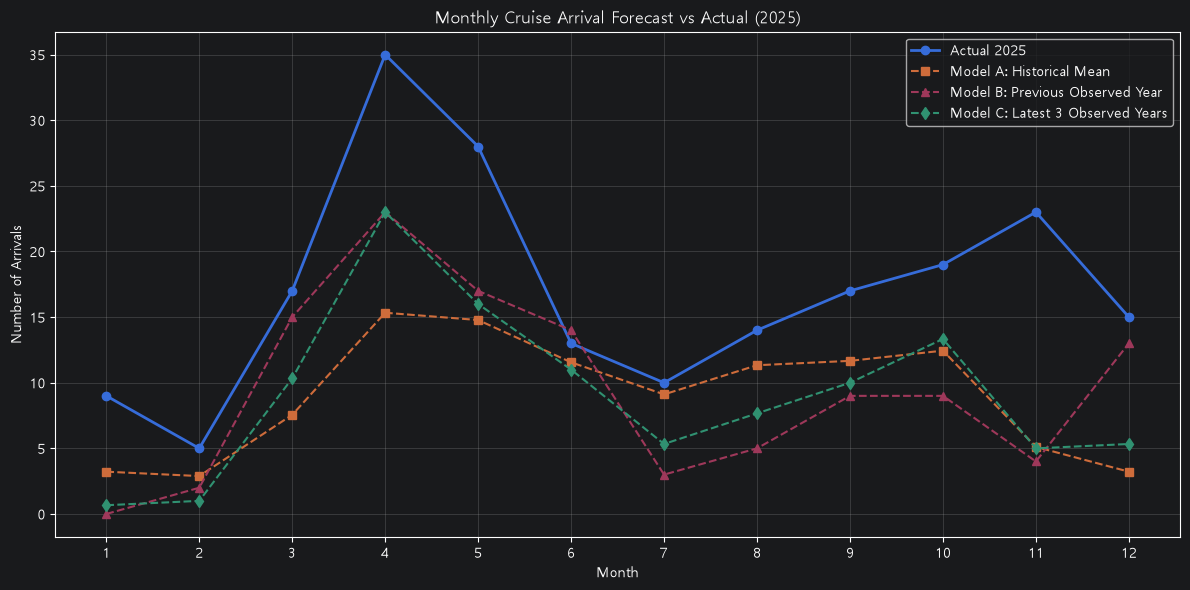

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 입항 데이터 전처리
# ==========================================

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"],
    errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 완전한 연간 데이터만 사용
# 2026년은 10월 16일까지이므로 제외
complete_years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

df = df[df["연도"].isin(complete_years)].copy()

# ==========================================
# 2. 연도별 월별 입항 건수 표 생성
# ==========================================

monthly_calls = (
    df.groupby(["연도", "월"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=complete_years, columns=range(1, 13), fill_value=0)
)

print("=== 연도별 월별 입항 건수 ===")
print(monthly_calls)

# ==========================================
# 3. 2025년 예측
#    2025년 데이터는 모델 학습에서 제외
# ==========================================

target_year = 2025

train_years = [
    year for year in complete_years
    if year < target_year
]

train = monthly_calls.loc[train_years]
actual = monthly_calls.loc[target_year]

# 모델 A: 과거 관측 연도 전체의 월별 평균
pred_A = train.mean(axis=0)

# 모델 B: 직전 관측 연도의 월별 건수
pred_B = train.iloc[-1]

# 모델 C: 최근 3개 관측 연도의 월별 평균
pred_C = train.iloc[-3:].mean(axis=0)

# ==========================================
# 4. 예측값과 실제값 비교
# ==========================================

comparison = pd.DataFrame({
    "실제_2025": actual,
    "모델A_과거평균": pred_A,
    "모델B_직전관측연도": pred_B,
    "모델C_최근3개관측연도평균": pred_C
})

comparison.index.name = "월"

comparison["모델A_절대오차"] = (
    comparison["실제_2025"] - comparison["모델A_과거평균"]
).abs()

comparison["모델B_절대오차"] = (
    comparison["실제_2025"] - comparison["모델B_직전관측연도"]
).abs()

comparison["모델C_절대오차"] = (
    comparison["실제_2025"] - comparison["모델C_최근3개관측연도평균"]
).abs()

print("\n=== 2025년 월별 예측 결과 ===")
print(comparison.round(2).to_string())

# ==========================================
# 5. 모델별 MAE 비교
# ==========================================

mae = pd.Series({
    "모델A_과거평균": comparison["모델A_절대오차"].mean(),
    "모델B_직전관측연도": comparison["모델B_절대오차"].mean(),
    "모델C_최근3개관측연도평균": comparison["모델C_절대오차"].mean()
}, name="MAE")

print("\n=== 모델별 평균 절대 오차(MAE) ===")
print(mae.round(2))

# ==========================================
# 6. 실제값과 예측값 시각화
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    comparison.index,
    comparison["실제_2025"],
    marker="o",
    linewidth=2,
    label="Actual 2025"
)

plt.plot(
    comparison.index,
    comparison["모델A_과거평균"],
    marker="s",
    linestyle="--",
    label="Model A: Historical Mean"
)

plt.plot(
    comparison.index,
    comparison["모델B_직전관측연도"],
    marker="^",
    linestyle="--",
    label="Model B: Previous Observed Year"
)

plt.plot(
    comparison.index,
    comparison["모델C_최근3개관측연도평균"],
    marker="d",
    linestyle="--",
    label="Model C: Latest 3 Observed Years"
)

plt.title("Monthly Cruise Arrival Forecast vs Actual (2025)")
plt.xlabel("Month")
plt.ylabel("Number of Arrivals")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

=== 연도별 월별 입항 건수 ===
월     1   2   3   4   5   6   7   8   9   10  11  12
연도                                                  
2013  10   0   7  13  13  15  14  12   9  12   1   0
2014   1   4   7  10  13  22  14   9  10   9   3   2
2015   0   1   3   7  11   8   2   6   5  10   9   2
2016   7   5   7  12  25  17  23  32  30  23  15   9
2017   9  11   9  12  10   1   7  11  12   7   0   0
2018   0   2   4  15  13   8   6   9   9  11   3   0
2019   2   1   6  23  18   7   9  12  11  11   4   3
2023   0   0  10  23  13  12   4   6  10  20   7   0
2024   0   2  15  23  17  14   3   5   9   9   4  13
2025   9   5  17  35  28  13  10  14  17  19  23  15

=== 전체 순차 검증 성능 ===
          모델  MAE  평균오차  검증월수
      A_과거평균 5.52  1.77    84
    B_직전관측연도 6.39  1.68    84
C_최근3개관측연도평균 5.61  1.75    84

=== 연도별 모델 성능 ===
 예측연도           모델   MAE  평균오차
 2016       A_과거평균  9.47  9.47
 2016     B_직전관측연도 11.75 11.75
 2016 C_최근3개관측연도평균  9.47  9.47
 2017       A_과거평균  5.48 -2.56
 2017     B_직전관측연도 11.33 -9.

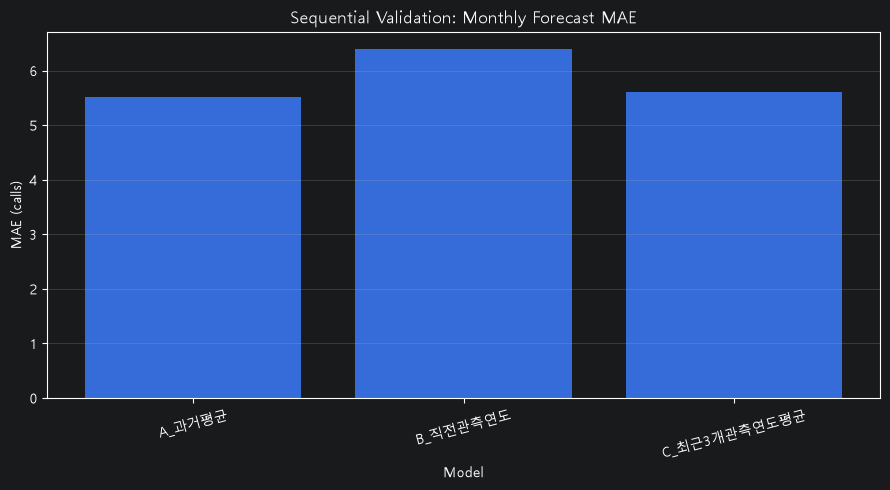

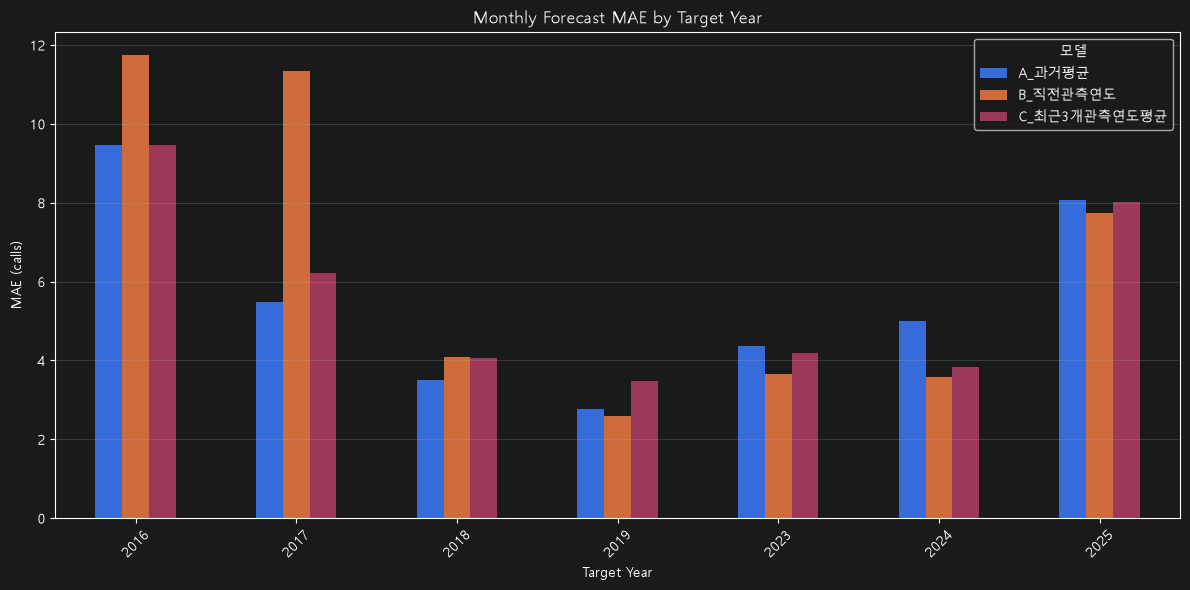

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 데이터 전처리
# ==========================================

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"],
    errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 완전한 연간 데이터가 있는 연도만 사용
years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

df = df[df["연도"].isin(years)].copy()

# 연도별 월별 입항 건수
monthly_calls = (
    df.groupby(["연도", "월"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=years, columns=range(1, 13), fill_value=0)
)

print("=== 연도별 월별 입항 건수 ===")
print(monthly_calls)

# ==========================================
# 2. 순차 검증
# ==========================================

results = []

# 최소 3개 관측 연도를 학습에 사용
for i in range(3, len(years)):

    target_year = years[i]
    previous_year = years[i - 1]

    # 연도 공백을 건너뛴 경우 별도로 표시
    consecutive = target_year - previous_year == 1

    train = monthly_calls.iloc[:i]
    actual = monthly_calls.loc[target_year]

    # 모델 A: 과거 전체 관측 연도의 월별 평균
    pred_A = train.mean(axis=0)

    # 모델 B: 직전 관측 연도의 월별 입항 건수
    pred_B = train.iloc[-1]

    # 모델 C: 최근 3개 관측 연도의 월별 평균
    pred_C = train.iloc[-3:].mean(axis=0)

    for month in range(1, 13):

        actual_value = actual.loc[month]

        for model_name, prediction in [
            ("A_과거평균", pred_A.loc[month]),
            ("B_직전관측연도", pred_B.loc[month]),
            ("C_최근3개관측연도평균", pred_C.loc[month])
        ]:
            results.append({
                "예측연도": target_year,
                "월": month,
                "모델": model_name,
                "실제": actual_value,
                "예측": prediction,
                "오차_실제-예측": actual_value - prediction,
                "절대오차": abs(actual_value - prediction),
                "연속연도검증": consecutive
            })

result_df = pd.DataFrame(results)

# ==========================================
# 3. 전체 검증 성능
# ==========================================

summary = (
    result_df.groupby("모델")
    .agg(
        MAE=("절대오차", "mean"),
        평균오차=("오차_실제-예측", "mean"),
        검증월수=("월", "count")
    )
    .reset_index()
)

# 평균오차 해석:
# 양수 = 실제값이 예측값보다 큼 (과소예측 경향)
# 음수 = 실제값이 예측값보다 작음 (과대예측 경향)

print("\n=== 전체 순차 검증 성능 ===")
print(summary.round(2).to_string(index=False))

# ==========================================
# 4. 연도별 모델 성능
# ==========================================

year_summary = (
    result_df.groupby(["예측연도", "모델"])
    .agg(
        MAE=("절대오차", "mean"),
        평균오차=("오차_실제-예측", "mean")
    )
    .reset_index()
)

print("\n=== 연도별 모델 성능 ===")
print(year_summary.round(2).to_string(index=False))

# ==========================================
# 5. 월별 모델 성능
# ==========================================

month_summary = (
    result_df.groupby(["월", "모델"])
    .agg(
        MAE=("절대오차", "mean"),
        평균오차=("오차_실제-예측", "mean")
    )
    .reset_index()
)

print("\n=== 월별 모델 성능 ===")
print(month_summary.round(2).to_string(index=False))

# ==========================================
# 6. 연속된 연도 검증만 별도 확인
# ==========================================

continuous_df = result_df[
    result_df["연속연도검증"]
].copy()

continuous_summary = (
    continuous_df.groupby("모델")
    .agg(
        MAE=("절대오차", "mean"),
        평균오차=("오차_실제-예측", "mean"),
        검증월수=("월", "count")
    )
    .reset_index()
)

print("\n=== 연속된 연도 검증 성능 ===")
print(continuous_summary.round(2).to_string(index=False))

# ==========================================
# 7. 모델별 전체 MAE 시각화
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(summary["모델"], summary["MAE"])

plt.title("Sequential Validation: Monthly Forecast MAE")
plt.xlabel("Model")
plt.ylabel("MAE (calls)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 8. 연도별 MAE 시각화
# ==========================================

year_pivot = year_summary.pivot(
    index="예측연도",
    columns="모델",
    values="MAE"
)

year_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Monthly Forecast MAE by Target Year")
plt.xlabel("Target Year")
plt.ylabel("MAE (calls)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

=== 연도별 월별 입항 비중(%) ===
월        1      2      3      4      5      6      7      8      9      10     11     12
연도                                                                                      
2013   9.43   0.00   6.60  12.26  12.26  14.15  13.21  11.32   8.49  11.32   0.94   0.00
2014   0.96   3.85   6.73   9.62  12.50  21.15  13.46   8.65   9.62   8.65   2.88   1.92
2015   0.00   1.56   4.69  10.94  17.19  12.50   3.12   9.38   7.81  15.62  14.06   3.12
2016   3.41   2.44   3.41   5.85  12.20   8.29  11.22  15.61  14.63  11.22   7.32   4.39
2017  10.11  12.36  10.11  13.48  11.24   1.12   7.87  12.36  13.48   7.87   0.00   0.00
2018   0.00   2.50   5.00  18.75  16.25  10.00   7.50  11.25  11.25  13.75   3.75   0.00
2019   1.87   0.93   5.61  21.50  16.82   6.54   8.41  11.21  10.28  10.28   3.74   2.80
2023   0.00   0.00   9.52  21.90  12.38  11.43   3.81   5.71   9.52  19.05   6.67   0.00
2024   0.00   1.75  13.16  20.18  14.91  12.28   2.63   4.39   7.89   7.89   3.51  11.

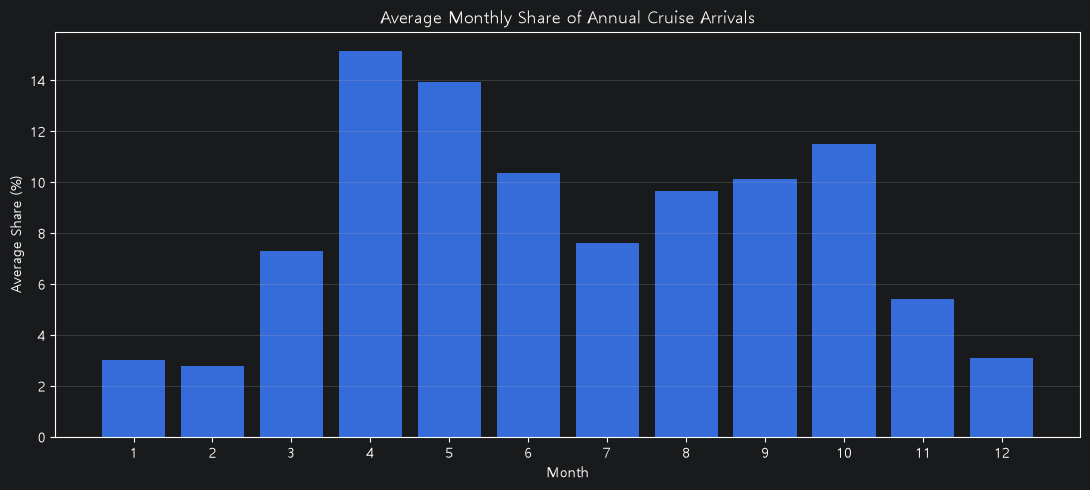

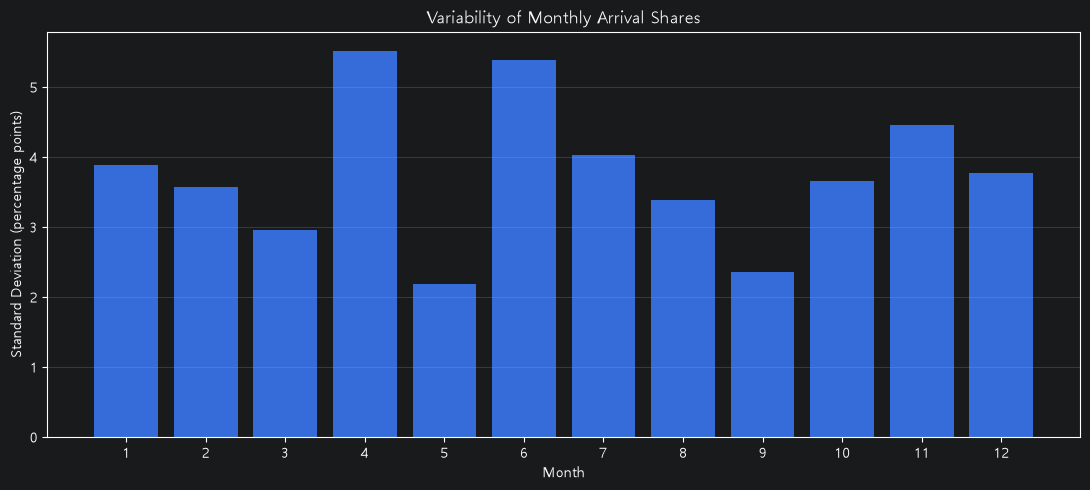

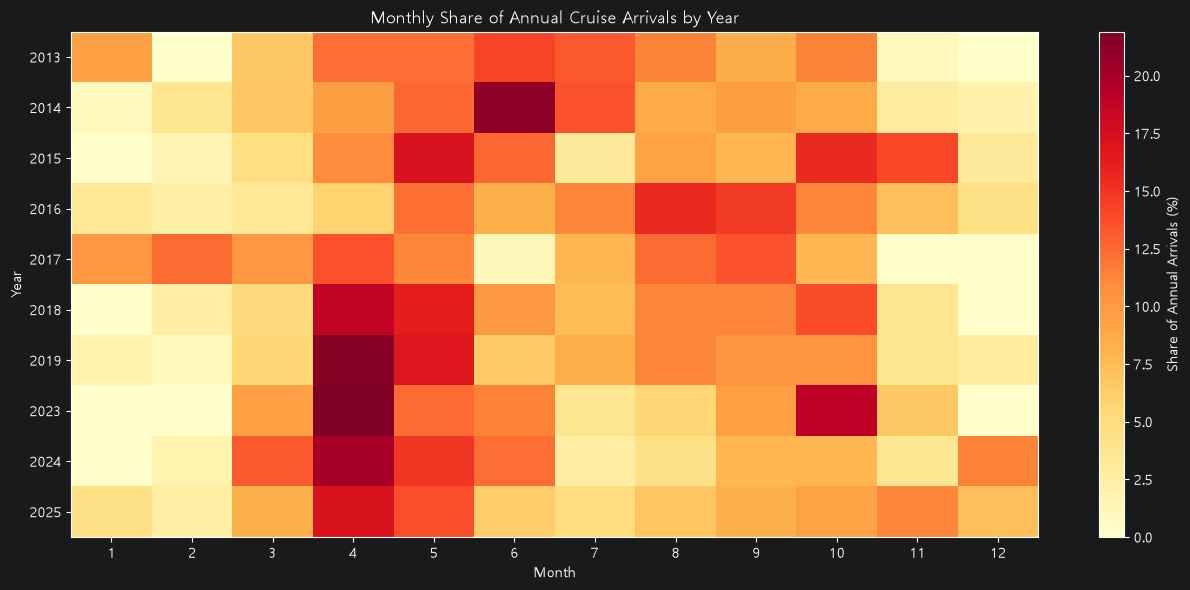

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 데이터 전처리
# ==========================================

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"],
    errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

df["연도"] = df["입항일시"].dt.year
df["월"] = df["입항일시"].dt.month

# 완전한 연간 데이터가 있는 연도만 사용
years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

df = df[df["연도"].isin(years)].copy()

# ==========================================
# 2. 연도별 월별 입항 건수
# ==========================================

monthly_calls = (
    df.groupby(["연도", "월"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=years, columns=range(1, 13), fill_value=0)
)

# 연도별 총입항 건수
annual_totals = monthly_calls.sum(axis=1)

# 월별 입항 비중(%)
monthly_share = (
    monthly_calls.div(annual_totals, axis=0) * 100
)

print("=== 연도별 월별 입항 비중(%) ===")
print(monthly_share.round(2).to_string())

# ==========================================
# 3. 월별 평균 비중과 변동성
# ==========================================

monthly_stats = pd.DataFrame({
    "평균입항건수": monthly_calls.mean(axis=0),
    "평균비중(%)": monthly_share.mean(axis=0),
    "비중표준편차(%p)": monthly_share.std(axis=0),
    "최소비중(%)": monthly_share.min(axis=0),
    "최대비중(%)": monthly_share.max(axis=0),
    "최소입항건수": monthly_calls.min(axis=0),
    "최대입항건수": monthly_calls.max(axis=0)
})

monthly_stats.index.name = "월"

print("\n=== 월별 입항 비중 및 변동성 ===")
print(monthly_stats.round(2).to_string())

# ==========================================
# 4. 평균 비중이 높은 달
# ==========================================

print("\n=== 평균 입항 비중 상위 5개월 ===")
print(
    monthly_stats.sort_values(
        "평균비중(%)", ascending=False
    ).head(5).round(2)
)

# ==========================================
# 5. 비중 변동성이 큰 달
# ==========================================

print("\n=== 월별 비중 표준편차 상위 5개월 ===")
print(
    monthly_stats.sort_values(
        "비중표준편차(%p)", ascending=False
    ).head(5).round(2)
)

# ==========================================
# 6. 월별 평균 비중 시각화
# ==========================================

plt.figure(figsize=(11, 5))

plt.bar(
    monthly_stats.index,
    monthly_stats["평균비중(%)"]
)

plt.title("Average Monthly Share of Annual Cruise Arrivals")
plt.xlabel("Month")
plt.ylabel("Average Share (%)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 7. 월별 비중 변동성 시각화
# ==========================================

plt.figure(figsize=(11, 5))

plt.bar(
    monthly_stats.index,
    monthly_stats["비중표준편차(%p)"]
)

plt.title("Variability of Monthly Arrival Shares")
plt.xlabel("Month")
plt.ylabel("Standard Deviation (percentage points)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 8. 연도별 월별 비중 히트맵
# ==========================================

plt.figure(figsize=(13, 6))

plt.imshow(
    monthly_share.values,
    aspect="auto",
    cmap="YlOrRd"
)

plt.colorbar(label="Share of Annual Arrivals (%)")

plt.xticks(
    ticks=np.arange(12),
    labels=range(1, 13)
)

plt.yticks(
    ticks=np.arange(len(years)),
    labels=years
)

plt.title("Monthly Share of Annual Cruise Arrivals by Year")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

=== 날짜별 집계 데이터 미리보기 ===
        입항일자  입항척수  승객수합계  승객정보보유척수              최초입항시각              최종입항시각  \
0 2013-01-01     1  933.0         1 2013-01-01 08:00:00 2013-01-01 08:00:00   
1 2013-01-06     1  754.0         1 2013-01-06 07:25:00 2013-01-06 07:25:00   
2 2013-01-10     1  177.0         1 2013-01-10 05:40:00 2013-01-10 05:40:00   
3 2013-01-13     1  481.0         1 2013-01-13 06:30:00 2013-01-13 06:30:00   
4 2013-01-15     1  180.0         1 2013-01-15 06:30:00 2013-01-15 06:30:00   
5 2013-01-17     1  145.0         1 2013-01-17 07:00:00 2013-01-17 07:00:00   
6 2013-01-20     1  400.0         1 2013-01-20 07:30:00 2013-01-20 07:30:00   
7 2013-01-24     1  222.0         1 2013-01-24 06:30:00 2013-01-24 06:30:00   
8 2013-01-27     1  472.0         1 2013-01-27 07:50:00 2013-01-27 07:50:00   
9 2013-01-31     1  296.0         1 2013-01-31 06:45:00 2013-01-31 06:45:00   

   승객정보누락  입항연도        요일  
0   False  2013   Tuesday  
1   False  2013    Sunday  
2   False  2013  Thurs

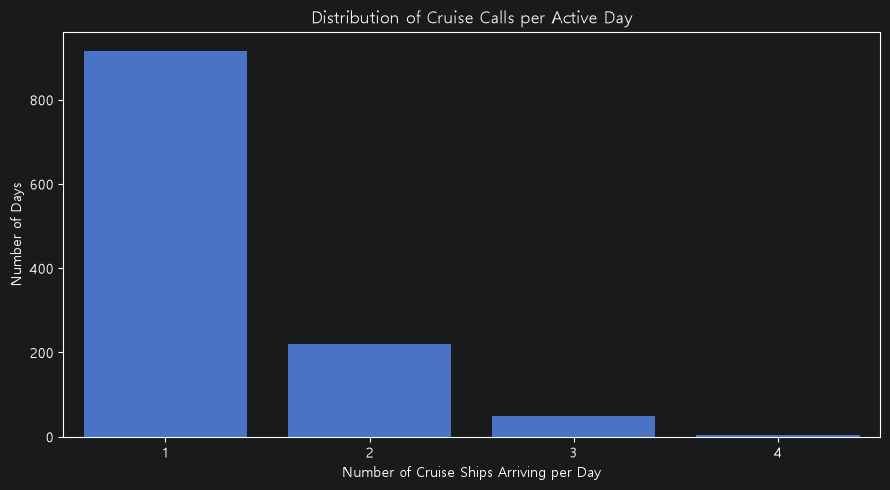

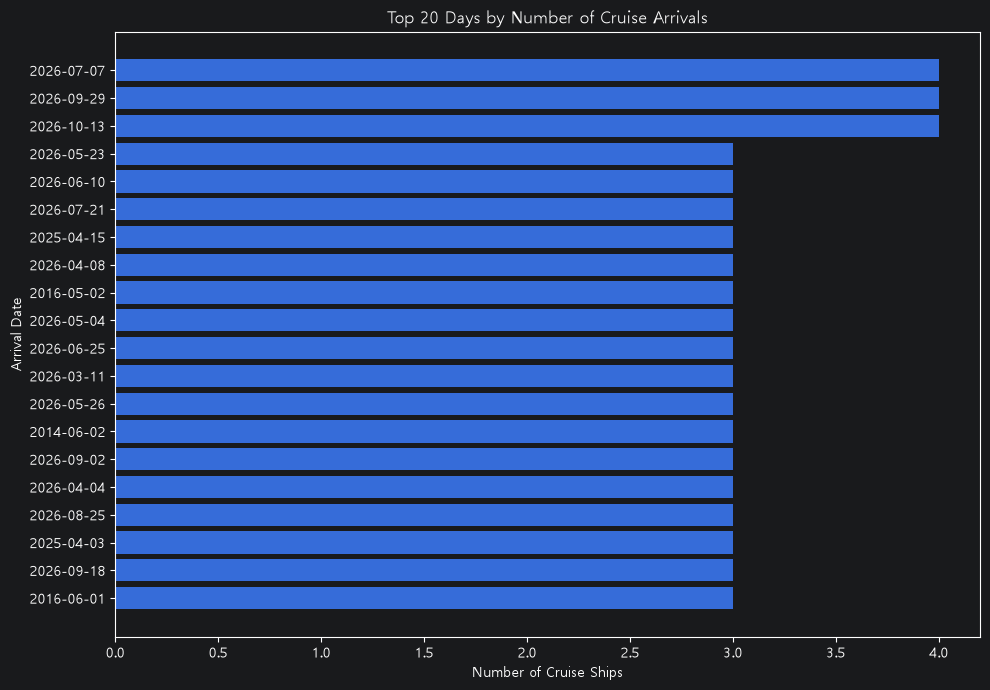

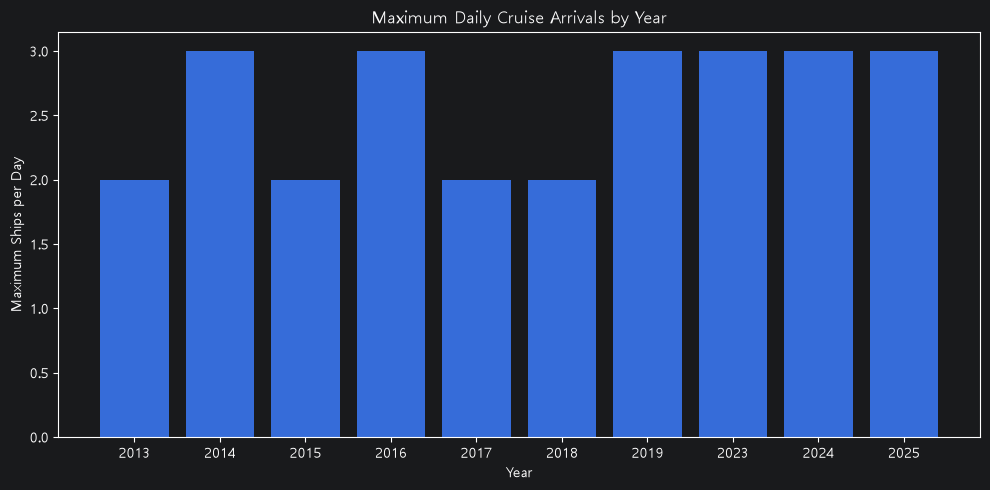

In [52]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==================================================
# 1. 데이터 전처리
# ==================================================

df = inbound.copy()

df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

df["승객"] = pd.to_numeric(
    df["승객"], errors="coerce"
)

df = df.dropna(subset=["입항일시"]).copy()

# 날짜 및 시간 변수 생성
df["입항일자"] = df["입항일시"].dt.date
df["입항연도"] = df["입항일시"].dt.year
df["입항시간"] = df["입항일시"].dt.hour

# ==================================================
# 2. 날짜별 입항 척수 및 승객 수 집계
# ==================================================

daily = (
    df.groupby("입항일자")
    .agg(
        입항척수=("입항일시", "size"),
        승객수합계=("승객", "sum"),
        승객정보보유척수=("승객", "count"),
        최초입항시각=("입항일시", "min"),
        최종입항시각=("입항일시", "max")
    )
    .reset_index()
)

daily["입항일자"] = pd.to_datetime(daily["입항일자"])

# 승객 수 결측값이 있는 날짜는 합계가 실제보다
# 작을 수 있으므로 결측 여부를 별도 표시
daily["승객정보누락"] = (
    daily["승객정보보유척수"] < daily["입항척수"]
)

daily["입항연도"] = daily["입항일자"].dt.year
daily["요일"] = daily["입항일자"].dt.day_name()

print("=== 날짜별 집계 데이터 미리보기 ===")
print(daily.head(10))

print("\n=== 날짜별 입항 척수 요약 ===")
print(daily["입항척수"].describe())

print("\n=== 날짜별 승객 수 합계 요약 ===")
print(daily["승객수합계"].describe())

# ==================================================
# 3. 하루 입항 척수별 날짜 수
# ==================================================

# 실제 입항이 있었던 날짜만 대상으로 계산
ship_count_distribution = (
    daily["입항척수"]
    .value_counts()
    .sort_index()
    .rename_axis("하루입항척수")
    .reset_index(name="날짜수")
)

print("\n=== 하루 입항 척수별 날짜 수 ===")
print(ship_count_distribution)

for threshold in [2, 3, 4]:
    n_days = (daily["입항척수"] >= threshold).sum()
    print(f"\n하루 {threshold}척 이상 입항한 날짜: {n_days}일")

# ==================================================
# 4. 입항 척수가 많았던 날짜 TOP 20
# ==================================================

top_ship_days = (
    daily.sort_values(
        ["입항척수", "승객수합계"],
        ascending=[False, False]
    )
    .head(20)
)

print("\n=== 날짜별 입항 척수 TOP 20 ===")
print(
    top_ship_days[
        [
            "입항일자", "입항척수", "승객수합계",
            "승객정보보유척수", "승객정보누락",
            "최초입항시각", "최종입항시각"
        ]
    ].to_string(index=False)
)

# ==================================================
# 5. 승객 수가 많았던 날짜 TOP 20
# 결측 승객 정보가 있는 날짜는 제외
# ==================================================

complete_passenger_days = daily[
    ~daily["승객정보누락"]
].copy()

top_passenger_days = (
    complete_passenger_days
    .sort_values("승객수합계", ascending=False)
    .head(20)
)

print("\n=== 날짜별 승객 수 합계 TOP 20 ===")
print(
    top_passenger_days[
        [
            "입항일자", "입항척수", "승객수합계",
            "최초입항시각", "최종입항시각"
        ]
    ].to_string(index=False)
)

# ==================================================
# 6. 입항 시각이 얼마나 겹쳤는지 확인
# 같은 날짜에 입항한 선박들의 시간 범위
# ==================================================

df["입항일자_dt"] = df["입항일시"].dt.normalize()

daily_time = (
    df.groupby("입항일자_dt")
    .agg(
        입항척수=("입항일시", "size"),
        최초입항시각=("입항일시", "min"),
        최종입항시각=("입항일시", "max")
    )
)

daily_time["최초최종간격_시간"] = (
    daily_time["최종입항시각"]
    - daily_time["최초입항시각"]
).dt.total_seconds() / 3600

daily_time = daily_time.reset_index()

print("\n=== 동일 날짜 입항 시각 범위 TOP 20 ===")
print(
    daily_time.sort_values(
        ["입항척수", "최초최종간격_시간"],
        ascending=[False, True]
    ).head(20).to_string(index=False)
)

# 주의: 최초·최종 입항 시각의 간격은
# 실제 하선 시간이나 관광시설 도착 시간과 다름.

# ==================================================
# 7. 연도별 하루 입항 집중도 비교
# 2026년은 부분 연도이므로 제외
# ==================================================

complete_years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

daily_complete = daily[
    daily["입항연도"].isin(complete_years)
].copy()

annual_daily_stats = (
    daily_complete.groupby("입항연도")
    .agg(
        입항일수=("입항척수", "size"),
        총입항척수=("입항척수", "sum"),
        하루평균입항척수=("입항척수", "mean"),
        하루최대입항척수=("입항척수", "max"),
        두척이상입항일수=(
            "입항척수", lambda x: (x >= 2).sum()
        ),
        세척이상입항일수=(
            "입항척수", lambda x: (x >= 3).sum()
        )
    )
)

print("\n=== 연도별 날짜 입항 집중도 ===")
print(annual_daily_stats.round(2))

# ==================================================
# 8. 시각화 1: 하루 입항 척수 분포
# ==================================================

plt.figure(figsize=(9, 5))

sns.countplot(
    data=daily,
    x="입항척수",
    order=sorted(daily["입항척수"].unique())
)

plt.title("Distribution of Cruise Calls per Active Day")
plt.xlabel("Number of Cruise Ships Arriving per Day")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()

# ==================================================
# 9. 시각화 2: 날짜별 입항 척수 TOP 20
# ==================================================

plot_data = top_ship_days.sort_values("입항척수")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["입항일자"].dt.strftime("%Y-%m-%d"),
    plot_data["입항척수"]
)

plt.title("Top 20 Days by Number of Cruise Arrivals")
plt.xlabel("Number of Cruise Ships")
plt.ylabel("Arrival Date")
plt.tight_layout()
plt.show()

# ==================================================
# 10. 시각화 3: 연도별 하루 최대 입항 척수
# ==================================================

plt.figure(figsize=(10, 5))

plt.bar(
    annual_daily_stats.index.astype(str),
    annual_daily_stats["하루최대입항척수"]
)

plt.title("Maximum Daily Cruise Arrivals by Year")
plt.xlabel("Year")
plt.ylabel("Maximum Ships per Day")
plt.tight_layout()
plt.show()


=== 동일 시간대 2척 이상 입항 사례 ===
사례 수: 45
      입항일자  입항시간  입항척수  승객수합계  승객정보보유척수  승객정보누락
2026-09-29     9     4 4761.0         4   False
2026-08-21     6     2 8277.0         2   False
2016-09-04     7     2 7262.0         2   False
2026-05-14     6     2 7221.0         2   False
2025-04-03     6     2 5811.0         2   False
2016-05-05     6     2 5654.0         2   False
2026-05-04     6     2 5638.0         2   False
2026-08-25     9     2 5508.0         2   False
2016-06-01     8     2 5424.0         2   False
2026-07-31     6     2 5402.0         2   False
2026-07-19     9     2 5367.0         2   False
2016-06-11     7     2 4995.0         2   False
2025-04-08     5     2 4870.0         2   False
2016-08-11     9     2 4732.0         2   False
2018-08-19    13     2 4506.0         2   False
2016-09-07     7     2 4423.0         2   False
2026-10-13     9     2 4294.0         2   False
2026-10-03     6     2 4101.0         2   False
2018-02-28     6     2 4023.0         2   False
2016

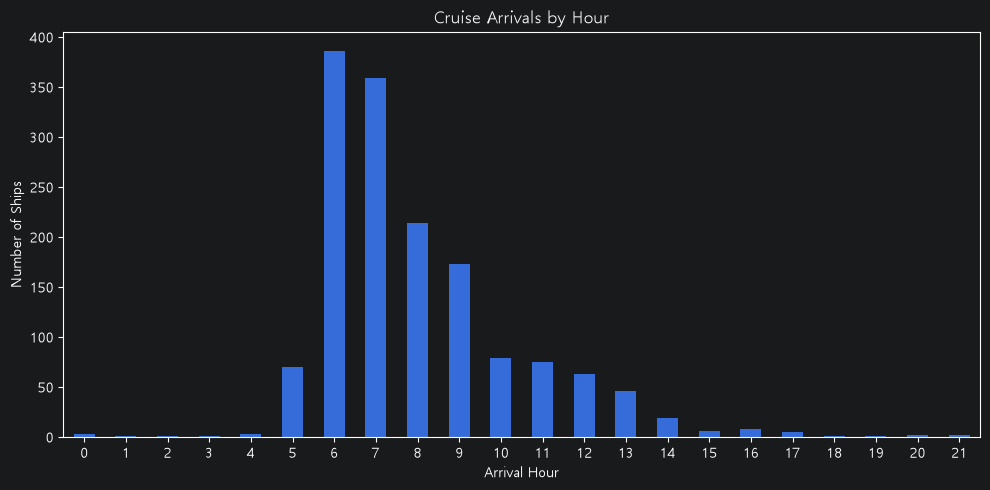

In [53]:

# ==================================================
# 시간대별 입항 집중도 분석
# 기존 df 데이터프레임 사용
# ==================================================

hourly = df.copy()

hourly["입항일자"] = hourly["입항일시"].dt.normalize()
hourly["입항시간"] = hourly["입항일시"].dt.hour

# 날짜와 시간별 입항 척수 및 승객 수 집계
hourly_group = (
    hourly.groupby(["입항일자", "입항시간"])
    .agg(
        입항척수=("입항일시", "size"),
        승객수합계=("승객", lambda x: x.sum(min_count=1)),
        승객정보보유척수=("승객", "count")
    )
    .reset_index()
)

# 승객 정보가 하나라도 누락된 시간대 표시
hourly_group["승객정보누락"] = (
    hourly_group["승객정보보유척수"]
    < hourly_group["입항척수"]
)

# ==================================================
# 1. 동일 시간대에 2척 이상 입항한 사례
# ==================================================

overlap = hourly_group[
    hourly_group["입항척수"] >= 2
].copy()

overlap = overlap.sort_values(
    ["입항척수", "승객수합계"],
    ascending=[False, False]
)

print("=== 동일 시간대 2척 이상 입항 사례 ===")
print("사례 수:", len(overlap))

print(
    overlap.head(30).to_string(index=False)
)

# ==================================================
# 2. 동일 시간대에 2척 이상 입항한 날짜 수
# ==================================================

overlap_days = (
    overlap.groupby(overlap["입항일자"].dt.year)
    .agg(
        중복시간대수=("입항척수", "size"),
        해당시간대최대입항척수=("입항척수", "max")
    )
)

print("\n=== 연도별 동일 시간대 입항 집중도 ===")
print(overlap_days)

# ==================================================
# 3. 시간대별 입항 척수와 승객 수
# ==================================================

hourly_summary = (
    hourly.groupby("입항시간")
    .agg(
        입항척수=("입항일시", "size"),
        승객수합계=("승객", lambda x: x.sum(min_count=1)),
        승객정보보유척수=("승객", "count")
    )
)

print("\n=== 시간대별 전체 입항 현황 ===")
print(hourly_summary)

# ==================================================
# 4. 시간대별 입항 척수 그래프
# ==================================================

import matplotlib.pyplot as plt

hourly_summary["입항척수"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cruise Arrivals by Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Number of Ships")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


=== 연도별 동일 시간대 중복 입항 비율 ===
      전체입항척수  중복시간대입항척수  중복시간대입항비율(%)
입항연도                                 
2013     106          2          1.89
2014     104          0          0.00
2015      64          0          0.00
2016     205         20          9.76
2017      89          0          0.00
2018      80          4          5.00
2019     107          8          7.48
2023     105          0          0.00
2024     114          2          1.75
2025     205         16          7.80


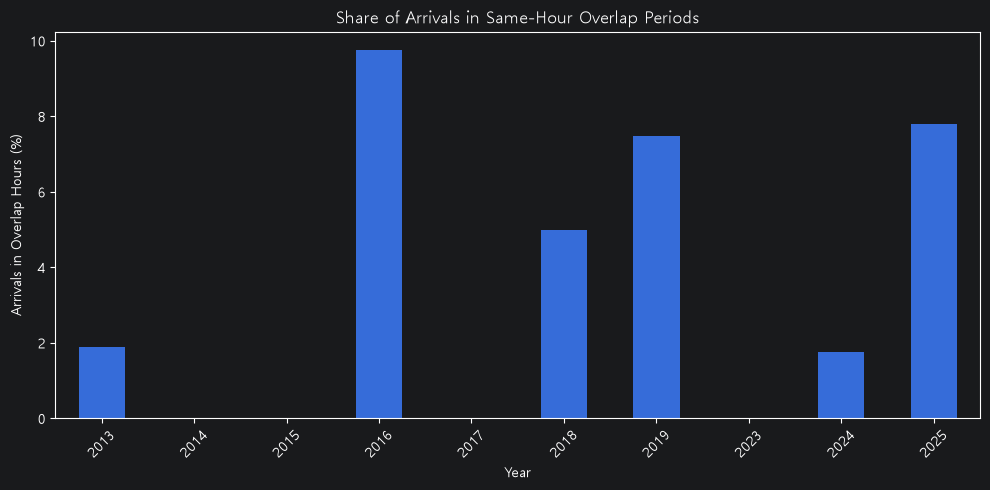

In [54]:

# ==================================================
# 연도별 동일 시간대 입항 집중도 정규화
# ==================================================

# 같은 날짜·시간에 2척 이상 입항한 시간대
overlap_keys = hourly_group.loc[
    hourly_group["입항척수"] >= 2,
    ["입항일자", "입항시간"]
].copy()

# 원본 선박별 기록에 중복 시간대 여부 연결
df_rate = df.copy()

df_rate["입항일자"] = (
    df_rate["입항일시"].dt.normalize()
)
df_rate["입항시간"] = df_rate["입항일시"].dt.hour

df_rate["중복시간대"] = (
    df_rate.set_index(["입항일자", "입항시간"]).index
    .isin(
        pd.MultiIndex.from_frame(overlap_keys)
    )
)

# 연도별 비교: 2026년 제외
complete_years = [
    2013, 2014, 2015, 2016, 2017,
    2018, 2019, 2023, 2024, 2025
]

df_rate = df_rate[
    df_rate["입항연도"].isin(complete_years)
].copy()

annual_overlap = (
    df_rate.groupby("입항연도")
    .agg(
        전체입항척수=("입항일시", "size"),
        중복시간대입항척수=("중복시간대", "sum")
    )
)

annual_overlap["중복시간대입항비율(%)"] = (
    annual_overlap["중복시간대입항척수"]
    / annual_overlap["전체입항척수"] * 100
)

print("=== 연도별 동일 시간대 중복 입항 비율 ===")
print(annual_overlap.round(2))

# 시각화
import matplotlib.pyplot as plt

annual_overlap["중복시간대입항비율(%)"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Share of Arrivals in Same-Hour Overlap Periods")
plt.xlabel("Year")
plt.ylabel("Arrivals in Overlap Hours (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [55]:
import pandas as pd
import numpy as np

# 원본을 보존하기 위해 복사
hourly_analysis = hourly_group.copy()

# 동일 날짜·시간대에 입항한 선박이 2척 이상이면 중복 시간대
hourly_analysis["중복시간대"] = (
    hourly_analysis["입항척수"] >= 2
)

# 승객 정보 누락 여부 확인
if "승객정보누락" in hourly_analysis.columns:
    hourly_analysis["승객정보누락"] = (
        hourly_analysis["승객정보누락"].fillna(False)
    )
else:
    hourly_analysis["승객정보누락"] = False

# 전체 시간대 요약
hourly_summary = (
    hourly_analysis
    .groupby("중복시간대")
    .agg(
        시간대수=("입항척수", "size"),
        총입항척수=("입항척수", "sum"),
        평균입항척수=("입항척수", "mean"),
        최대입항척수=("입항척수", "max"),
        승객정보누락시간대=("승객정보누락", "sum")
    )
)

print("===== 중복 시간대 vs 비중복 시간대 =====")
print(hourly_summary)

# 승객 수는 승객 정보가 누락된 시간대를 제외하고 비교
passenger_summary = (
    hourly_analysis[
        ~hourly_analysis["승객정보누락"]
    ]
    .groupby("중복시간대")
    .agg(
        승객정보확인시간대=("승객수합계", "count"),
        평균승객수=("승객수합계", "mean"),
        중앙값승객수=("승객수합계", "median"),
        최대승객수=("승객수합계", "max"),
        승객수합계=("승객수합계", "sum")
    )
)

print("\n===== 승객 규모 비교 =====")
print(passenger_summary)

===== 중복 시간대 vs 비중복 시간대 =====
       시간대수  총입항척수    평균입항척수  최대입항척수  승객정보누락시간대
중복시간대                                          
False  1426   1426  1.000000       1          2
True     45     92  2.044444       4          0

===== 승객 규모 비교 =====
       승객정보확인시간대        평균승객수  중앙값승객수   최대승객수      승객수합계
중복시간대                                                   
False       1424  1835.428371  1878.5  5431.0  2613650.0
True          45  3534.866667  3467.0  8277.0   159069.0


In [58]:
# 중복 시간대만 추출
overlap_passengers = hourly_analysis[
    (hourly_analysis["중복시간대"])
    & (~hourly_analysis["승객정보누락"])
].copy()

# 승객 수가 큰 순서대로 정렬
overlap_passengers = overlap_passengers.sort_values(
    by=["승객수합계", "입항척수"],
    ascending=[False, False]
)



print("===== 승객 규모가 큰 중복 입항 시간대 TOP 20 =====")

print(
    overlap_passengers[
        [
            "입항일자",
            "입항시간",
            "입항척수",
            "승객수합계"
        ]
    ].head(20).to_string(index=False)
)

===== 승객 규모가 큰 중복 입항 시간대 TOP 20 =====
      입항일자  입항시간  입항척수  승객수합계
2026-08-21     6     2 8277.0
2016-09-04     7     2 7262.0
2026-05-14     6     2 7221.0
2025-04-03     6     2 5811.0
2016-05-05     6     2 5654.0
2026-05-04     6     2 5638.0
2026-08-25     9     2 5508.0
2016-06-01     8     2 5424.0
2026-07-31     6     2 5402.0
2026-07-19     9     2 5367.0
2016-06-11     7     2 4995.0
2025-04-08     5     2 4870.0
2026-09-29     9     4 4761.0
2016-08-11     9     2 4732.0
2018-08-19    13     2 4506.0
2016-09-07     7     2 4423.0
2026-10-13     9     2 4294.0
2026-10-03     6     2 4101.0
2018-02-28     6     2 4023.0
2016-05-10     7     2 3965.0


In [59]:
# 전체 시간대 기준
total_calls = hourly_analysis["입항척수"].sum()
overlap_calls = hourly_analysis.loc[
    hourly_analysis["중복시간대"], "입항척수"
].sum()

print(f"전체 입항 척수: {total_calls:,}")
print(f"중복 시간대 입항 척수: {overlap_calls:,}")
print(f"중복 시간대 입항 척수 비중: {overlap_calls / total_calls * 100:.2f}%")

# 승객 정보 누락 시간대 제외
passenger_valid = hourly_analysis[
    ~hourly_analysis["승객정보누락"]
].copy()

total_passengers = passenger_valid["승객수합계"].sum()
overlap_passengers_total = passenger_valid.loc[
    passenger_valid["중복시간대"], "승객수합계"
].sum()

print(f"\n승객 정보 확인 시간대의 승객 수 합계: {total_passengers:,.0f}")
print(f"중복 시간대의 승객 수 합계: {overlap_passengers_total:,.0f}")

if total_passengers > 0:
    print(
        "중복 시간대 승객 수 비중: "
        f"{overlap_passengers_total / total_passengers * 100:.2f}%"
    )

전체 입항 척수: 1,518
중복 시간대 입항 척수: 92
중복 시간대 입항 척수 비중: 6.06%

승객 정보 확인 시간대의 승객 수 합계: 2,772,719
중복 시간대의 승객 수 합계: 159,069
중복 시간대 승객 수 비중: 5.74%


In [60]:
import pandas as pd
import numpy as np

# 원본 데이터 복사
df = inbound.copy()

# 날짜·시간 데이터 정리
df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")
df = df.dropna(subset=["입항일시"])

df["입항일자"] = df["입항일시"].dt.normalize()
df["입항시간"] = df["입항일시"].dt.hour
df["입항월"] = df["입항일시"].dt.month
df["요일번호"] = df["입항일시"].dt.dayofweek

요일명 = {
    0: "월요일", 1: "화요일", 2: "수요일",
    3: "목요일", 4: "금요일", 5: "토요일",
    6: "일요일"
}
df["요일"] = df["요일번호"].map(요일명)

# 선석명 정리
df["선석"] = (
    df["계선장소.2"]
    .astype("string")
    .str.strip()
)

print("분석 대상 입항 기록:", len(df))
print("선석 결측:", df["선석"].isna().sum())
print("선석 종류 수:", df["선석"].nunique())
print(df["선석"].value_counts(dropna=False).head(20))

분석 대상 입항 기록: 1518
선석 결측: 0
선석 종류 수: 16
선석
북항크루즈터미널 1선석          522
영도크루즈터미널              446
국제여객터미널 14선석          276
북항크루즈터미널 2선석          128
감만부두 3선석(신선대감만터미널)    121
1부두 14선석                7
자성대부두 64선석              4
남외항 N-4박지               4
남외항 N-5박지               2
감만부두 2선석(신선대감만터미널)      2
신선대부두 5선석               1
신선대부두 2선석               1
감만부두 4선석(신선대감만터미널)      1
수영박지(집단박지)              1
국제여객터미널 10선석            1
국제여객터미널 13선석            1
Name: count, dtype: Int64


In [61]:
# 선석별 날짜·시간대 입항 척수
berth_hourly = (
    df.dropna(subset=["선석"])
    .groupby(["선석", "입항일자", "입항시간"])
    .agg(
        입항척수=("입항일시", "size"),
        승객수합계=("승객", "sum"),
        승객정보보유척수=("승객", "count")
    )
    .reset_index()
)

# 같은 선석·날짜·시간대에 2척 이상 입항
berth_hourly["중복입항"] = berth_hourly["입항척수"] >= 2

# 선석별 요약
berth_overlap_summary = (
    berth_hourly
    .groupby("선석")
    .agg(
        관측시간대수=("입항척수", "size"),
        전체입항척수=("입항척수", "sum"),
        중복시간대수=("중복입항", "sum"),
        최대동시간대입항척수=("입항척수", "max")
    )
)

berth_overlap_summary["중복시간대비율(%)"] = (
    berth_overlap_summary["중복시간대수"]
    / berth_overlap_summary["관측시간대수"]
    * 100
).round(2)

print("===== 선석별 중복 입항 현황 =====")
print(
    berth_overlap_summary
    .sort_values("중복시간대수", ascending=False)
    .to_string()
)

print("\n===== 선석별 중복 입항 사례 TOP 20 =====")
print(
    berth_hourly[berth_hourly["중복입항"]]
    .sort_values(
        ["입항척수", "승객수합계"],
        ascending=False
    )
    .head(20)
    .to_string(index=False)
)

===== 선석별 중복 입항 현황 =====
                    관측시간대수  전체입항척수  중복시간대수  최대동시간대입항척수  중복시간대비율(%)
선석                                                                
1부두 14선석                 7       7       0           1         0.0
감만부두 2선석(신선대감만터미널)       2       2       0           1         0.0
감만부두 3선석(신선대감만터미널)     121     121       0           1         0.0
감만부두 4선석(신선대감만터미널)       1       1       0           1         0.0
국제여객터미널 10선석             1       1       0           1         0.0
국제여객터미널 13선석             1       1       0           1         0.0
국제여객터미널 14선석           276     276       0           1         0.0
남외항 N-4박지                4       4       0           1         0.0
남외항 N-5박지                2       2       0           1         0.0
북항크루즈터미널 1선석           522     522       0           1         0.0
북항크루즈터미널 2선석           128     128       0           1         0.0
수영박지(집단박지)               1       1       0           1         0.0
신선대부두 2선석                1       1   

In [62]:
# 날짜·시간대별 입항 척수
date_hour = (
    df.groupby(["입항일자", "입항시간"])
    .agg(
        입항척수=("입항일시", "size"),
        승객수합계=("승객", "sum"),
        승객정보보유척수=("승객", "count")
    )
    .reset_index()
)

date_hour["중복입항"] = date_hour["입항척수"] >= 2
date_hour["입항월"] = date_hour["입항일자"].dt.month
date_hour["요일번호"] = date_hour["입항일자"].dt.dayofweek
date_hour["요일"] = date_hour["요일번호"].map(요일명)

# 월별 중복 입항 현황
monthly_overlap = (
    date_hour
    .groupby("입항월")
    .agg(
        관측시간대수=("입항척수", "size"),
        중복시간대수=("중복입항", "sum"),
        총입항척수=("입항척수", "sum"),
        최대동시간대입항척수=("입항척수", "max")
    )
)

monthly_overlap["중복시간대비율(%)"] = (
    monthly_overlap["중복시간대수"]
    / monthly_overlap["관측시간대수"]
    * 100
).round(2)

print("===== 월별 중복 입항 =====")
print(monthly_overlap.to_string())

# 요일별 중복 입항 현황
weekday_overlap = (
    date_hour
    .groupby(["요일번호", "요일"])
    .agg(
        관측시간대수=("입항척수", "size"),
        중복시간대수=("중복입항", "sum"),
        총입항척수=("입항척수", "sum"),
        최대동시간대입항척수=("입항척수", "max")
    )
    .reset_index()
    .sort_values("요일번호")
)

weekday_overlap["중복시간대비율(%)"] = (
    weekday_overlap["중복시간대수"]
    / weekday_overlap["관측시간대수"]
    * 100
).round(2)

print("\n===== 요일별 중복 입항 =====")
print(weekday_overlap.to_string(index=False))

===== 월별 중복 입항 =====
     관측시간대수  중복시간대수  총입항척수  최대동시간대입항척수  중복시간대비율(%)
입항월                                               
1        56       0     56           1        0.00
2        50       1     51           2        2.00
3       133       2    135           2        1.50
4       206      13    219           2        6.31
5       199       8    207           2        4.02
6       155       3    158           2        1.94
7       122       3    125           2        2.46
8       136       7    143           2        5.15
9       155       3    160           4        1.94
10      147       4    151           2        2.72
11       69       0     69           1        0.00
12       43       1     44           2        2.33

===== 요일별 중복 입항 =====
 요일번호  요일  관측시간대수  중복시간대수  총입항척수  최대동시간대입항척수  중복시간대비율(%)
    0 월요일     215       4    219           2        1.86
    1 화요일     219      12    233           4        5.48
    2 수요일     222       6    228           2        2.70
    3 목요일     

In [63]:
import pandas as pd
import numpy as np

df = inbound.copy()

# 승객 수를 숫자로 변환
df["승객"] = pd.to_numeric(df["승객"], errors="coerce")

# 입항일시 정리
df["입항일시"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

df = df.dropna(subset=["입항일시", "계선장소.2"]).copy()

df["입항연도"] = df["입항일시"].dt.year
df["입항월"] = df["입항일시"].dt.month

# 2026년은 10월 16일까지의 부분 자료이므로
# 월별 비교에서는 완전연도 자료만 사용
df_full = df[df["입항연도"] <= 2025].copy()

# 주요 5개 선석
major_berths = [
    "북항크루즈터미널 1선석",
    "영도크루즈터미널",
    "국제여객터미널 14선석",
    "북항크루즈터미널 2선석",
    "감만부두 3선석(신선대감만터미널)"
]

major = df_full[
    df_full["계선장소.2"].isin(major_berths)
].copy()

# 선석별 요약
berth_summary = (
    major.groupby("계선장소.2")
    .agg(
        입항척수=("입항일시", "size"),
        승객정보보유척수=("승객", "count"),
        승객수합계=("승객", "sum"),
        평균승객수=("승객", "mean"),
        중앙값승객수=("승객", "median")
    )
    .sort_values("입항척수", ascending=False)
)

print("===== 주요 선석별 입항·승객 규모 =====")
print(berth_summary.round(1).to_string())

===== 주요 선석별 입항·승객 규모 =====
                    입항척수  승객정보보유척수     승객수합계   평균승객수  중앙값승객수
계선장소.2                                                      
북항크루즈터미널 1선석         382       382  650029.0  1701.6  1941.5
영도크루즈터미널             354       354  797035.0  2251.5  2437.0
국제여객터미널 14선석         206       206  258782.0  1256.2  1392.5
감만부두 3선석(신선대감만터미널)   121       121  440160.0  3637.7  4172.0
북항크루즈터미널 2선석          91        91   29457.0   323.7   219.0


In [64]:
# 월별 입항 척수
monthly_calls = pd.pivot_table(
    major,
    index="입항월",
    columns="계선장소.2",
    values="입항일시",
    aggfunc="count",
    fill_value=0
)

print("===== 선석별 월간 입항 척수 =====")
print(monthly_calls.to_string())

# 월별 승객 수 합계
monthly_passengers = pd.pivot_table(
    major,
    index="입항월",
    columns="계선장소.2",
    values="승객",
    aggfunc="sum",
    fill_value=0
)

print("\n===== 선석별 월간 승객 수 합계 =====")
print(monthly_passengers.to_string())

===== 선석별 월간 입항 척수 =====
계선장소.2  감만부두 3선석(신선대감만터미널)  국제여객터미널 14선석  북항크루즈터미널 1선석  북항크루즈터미널 2선석  영도크루즈터미널
입항월                                                                           
1                        9             8             6             0        14
2                        9             8             7             1         6
3                        8             4            38             9        23
4                        7            13            69            33        47
5                       14            33            49            17        46
6                       10            17            40             2        44
7                       11            25            15             0        38
8                       10            33            27             3        41
9                       11            29            36             8        38
10                      10            14            50            11        42
11                      15 

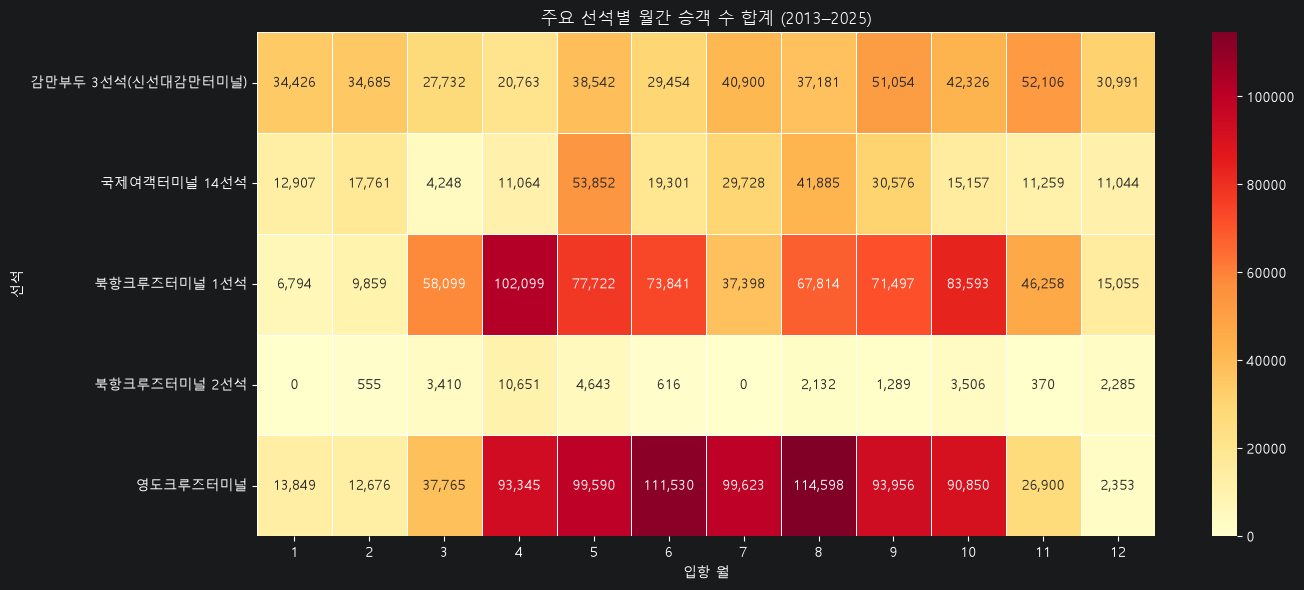

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.heatmap(
    monthly_passengers.T,
    annot=True,
    fmt=",.0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("주요 선석별 월간 승객 수 합계 (2013–2025)")
plt.xlabel("입항 월")
plt.ylabel("선석")
plt.tight_layout()
plt.show()